## 1 · Setup and configuration

In [4]:
# GridDefense | Step 1: Install & Import

!pip install pypower -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypower.api import case14, runpf, ppoption

# Reproducibility - same random results every run
np.random.seed(42)

print("PyPower installed")
print("All libraries imported")

# Load IEEE 14-bus
ppc = case14()

print(f"\n IEEE 14-Bus System Loaded:")
print(f"  Buses     : {ppc['bus'].shape[0]}")
print(f"  Branches  : {ppc['branch'].shape[0]}")
print(f"  Generators: {ppc['gen'].shape[0]}")

PyPower installed
All libraries imported

 IEEE 14-Bus System Loaded:
  Buses     : 14
  Branches  : 20
  Generators: 5


In [5]:
# ============================================================
# GridDefense | Google Drive + output folder
# ============================================================
import os
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/GridDefense'
OUT_DIR  = f'{BASE_DIR}/final_notebook'
os.makedirs(f'{OUT_DIR}/results', exist_ok=True)
print('Outputs are saved to:', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Outputs are saved to: /content/drive/MyDrive/GridDefense/final_notebook


In [6]:
# ============================================================
# GridDefense | Experiment configuration
# ============================================================
# Every setting that defines the experiment is set here.

# Random seeds
DEV_SEED  = 42      # development data: train / validation / development test
TEST_SEED = 20261014  # independent test set — generated and used only in Section 10

# Dataset size and operating conditions
N_NORMAL = 5000                     # normal snapshots
N_ATTACK = 2000                     # snapshots per attack type (3 types)
LOAD_MIN, LOAD_MAX = 0.80, 1.20     # per-bus load scaling of the IEEE 14-bus base case

# Attacks: 1–3 % of the true measurement; the slack bus (Bus 1) is never attacked
ATTACK_MIN, ATTACK_MAX = 0.010, 0.030
VA_ATTACK_MAX_DEG = 0.5             # angle bias at the maximum attack magnitude (degrees)

# Measurement noise (one standard deviation)
# Vm / Va: PMU measurements — 3σ kept within the IEEE C37.118.1 1% TVE limit
# Pd, Qd, Pg, Qg: SCADA-type measurements, 1% of value
VM_NOISE_STD = 0.002                # voltage magnitude, p.u.
VA_NOISE_STD = 0.115                # voltage angle, degrees (0.002 rad)
PD_NOISE_REL = 0.01                 # load active power, fraction of value
QD_NOISE_REL = 0.01                 # load reactive power, fraction of value
PG_NOISE_REL = 0.01                 # generator active power, fraction of value
QG_NOISE_REL = 0.01                 # generator reactive power, fraction of value
PD_NOISE_FLOOR = 0.01               # minimum magnitude used to scale relative noise
QD_NOISE_FLOOR = 0.01

# Physics validation layer
USE_S_LOADING = False               # thermal-loading check off: IEEE 14-bus ratings are 9900 MVA placeholders (Section 8)

CONFIG = {k: v for k, v in dict(globals()).items()
          if k.isupper() and not k.startswith('_') and isinstance(v, (int, float, bool))}
for k, v in CONFIG.items():
    print(f"  {k:<18} = {v}")

  DEV_SEED           = 42
  TEST_SEED          = 20261014
  N_NORMAL           = 5000
  N_ATTACK           = 2000
  LOAD_MIN           = 0.8
  LOAD_MAX           = 1.2
  ATTACK_MIN         = 0.01
  ATTACK_MAX         = 0.03
  VA_ATTACK_MAX_DEG  = 0.5
  VM_NOISE_STD       = 0.002
  VA_NOISE_STD       = 0.115
  PD_NOISE_REL       = 0.01
  QD_NOISE_REL       = 0.01
  PG_NOISE_REL       = 0.01
  QG_NOISE_REL       = 0.01
  PD_NOISE_FLOOR     = 0.01
  QD_NOISE_FLOOR     = 0.01
  USE_S_LOADING      = False


## 2 · IEEE 14-bus system

In [7]:
# GridDefense | Step 2: Explore the IEEE 14-bus Structure
# Understanding what data PYPOWER gives us


print("=" * 55)
print("BUS DATA — first 5 buses")
print("=" * 55)
print(f"Bus matrix shape: {ppc['bus'].shape}")
print(f"Columns: Bus No | Type | Pd | Qd | Gs | Bs | Area | Vm | Va | BaseKV | Zone | Vmax | Vmin")
print()
print(ppc['bus'][:5, :])

print("\n" + "=" * 55)
print("BRANCH DATA — first 5 branches")
print("=" * 55)
print(f"Branch matrix shape: {ppc['branch'].shape}")
print(f"Columns: From | To | R | X | B | RateA | RateB | RateC | ...")
print()
print(ppc['branch'][:5, :5])  # just first 5 columns

print("\n" + "=" * 55)
print("WHAT WE CARE ABOUT:")
print("=" * 55)
print("From bus data:")
print(f"  Vm (voltage magnitude) → column 7")
print(f"  Va (voltage angle)     → column 8")
print(f"  Pd (active power load) → column 2")
print(f"  Qd (reactive power)    → column 3")
print("\nFrom branch data:")
print(f"  From bus → column 0")
print(f"  To bus   → column 1")
print(f"  R (resistance)  → column 2")
print(f"  X (reactance)   → column 3")
print("\nThese are the measurements our PMU sensors would record.")
print("These are what an attacker would manipulate in FDIA.")

BUS DATA — first 5 buses
Bus matrix shape: (14, 13)
Columns: Bus No | Type | Pd | Qd | Gs | Bs | Area | Vm | Va | BaseKV | Zone | Vmax | Vmin

[[  1.      3.      0.      0.      0.      0.      1.      1.06    0.
    0.      1.      1.06    0.94 ]
 [  2.      2.     21.7    12.7     0.      0.      1.      1.045  -4.98
    0.      1.      1.06    0.94 ]
 [  3.      2.     94.2    19.      0.      0.      1.      1.01  -12.72
    0.      1.      1.06    0.94 ]
 [  4.      1.     47.8    -3.9     0.      0.      1.      1.019 -10.33
    0.      1.      1.06    0.94 ]
 [  5.      1.      7.6     1.6     0.      0.      1.      1.02   -8.78
    0.      1.      1.06    0.94 ]]

BRANCH DATA — first 5 branches
Branch matrix shape: (20, 13)
Columns: From | To | R | X | B | RateA | RateB | RateC | ...

[[1.      2.      0.01938 0.05917 0.0528 ]
 [1.      5.      0.05403 0.22304 0.0492 ]
 [2.      3.      0.04699 0.19797 0.0438 ]
 [2.      4.      0.05811 0.17632 0.034  ]
 [2.      5.      0.05

In [8]:
# GridDefense | Step 3: Run Power Flow & Extract Measurements
# This is what ONE timestep of PMU data looks like


# Set PYPOWER options - suppress output
opt = ppoption(VERBOSE=0, OUT_ALL=0)

# Run AC power flow
result = runpf(ppc, opt)

# Extract the solved case
solved = result[0]
success = result[1]

print(f"Power flow converged: {bool(success)}")
print()

# Extract measurements from all 14 buses
bus_data = solved['bus']

# Our 4 key measurements per bus
Vm = bus_data[:, 7]   # Voltage magnitude (pu)
Va = bus_data[:, 8]   # Voltage angle (degrees)
Pd = bus_data[:, 2]   # Active power load (MW)
Qd = bus_data[:, 3]   # Reactive power load (MVAr)

print("=" * 45)
print("PMU Measurements — All 14 Buses")
print("=" * 45)
print(f"{'Bus':>4} {'Vm(pu)':>8} {'Va(deg)':>8} {'Pd(MW)':>8} {'Qd(MVAr)':>10}")
print("-" * 45)
for i in range(14):
    print(f"{i+1:>4} {Vm[i]:>8.4f} {Va[i]:>8.3f} {Pd[i]:>8.2f} {Qd[i]:>10.2f}")

print()
print(f"Total active load:    {Pd.sum():.2f} MW")
print(f"Total reactive load:  {Qd.sum():.2f} MVAr")
print()
print("This is what ONE timestep of normal PMU data looks like.")
print("We will generate 5000 of these with varying loads.")

Power flow converged: True

PMU Measurements — All 14 Buses
 Bus   Vm(pu)  Va(deg)   Pd(MW)   Qd(MVAr)
---------------------------------------------
   1   1.0600    0.000     0.00       0.00
   2   1.0450   -4.983    21.70      12.70
   3   1.0100  -12.725    94.20      19.00
   4   1.0177  -10.313    47.80      -3.90
   5   1.0195   -8.774     7.60       1.60
   6   1.0700  -14.221    11.20       7.50
   7   1.0615  -13.360     0.00       0.00
   8   1.0900  -13.360     0.00       0.00
   9   1.0559  -14.939    29.50      16.60
  10   1.0510  -15.097     9.00       5.80
  11   1.0569  -14.791     3.50       1.80
  12   1.0552  -15.076     6.10       1.60
  13   1.0504  -15.156    13.50       5.80
  14   1.0355  -16.034    14.90       5.00

Total active load:    259.00 MW
Total reactive load:  73.50 MVAr

This is what ONE timestep of normal PMU data looks like.
We will generate 5000 of these with varying loads.


In [9]:
# GridDefense | Step 4: Build Graph Structure

branch_data = ppc['branch']
from_bus = branch_data[:, 0].astype(int) - 1
to_bus   = branch_data[:, 1].astype(int) - 1
resistance  = branch_data[:, 2]
reactance   = branch_data[:, 3]
impedance   = np.sqrt(resistance**2 + reactance**2)

adj_matrix = np.zeros((14, 14))
for i in range(len(from_bus)):
    f, t = from_bus[i], to_bus[i]
    adj_matrix[f, t] = 1
    adj_matrix[t, f] = 1

edge_index, edge_weights = [], []
for i in range(len(from_bus)):
    f, t = from_bus[i], to_bus[i]
    edge_index.append([f, t])
    edge_index.append([t, f])
    edge_weights.append(impedance[i])
    edge_weights.append(impedance[i])

edge_index   = np.array(edge_index).T
edge_weights = np.array(edge_weights)

print("✓ Graph structure built")
print(f"  Adjacency matrix : {adj_matrix.shape}")
print(f"  Edge list        : {edge_index.shape}")

✓ Graph structure built
  Adjacency matrix : (14, 14)
  Edge list        : (2, 40)


## 3 · Data generation and physics features

`generate_dataset(seed)` produces one dataset: normal snapshots plus the three attack types. The same function, with a different seed, produces the independent test set in Section 10.

In [10]:
# ============================================================
# GridDefense | Step 5 — Attack Injection (Final + Bus Labels)
# ============================================================
# All previous fixes retained:
#   ✓ Va fixed bias ±0.5° max
#   ✓ Scaling: Vm only, Va unchanged
#   ✓ Coordinated: topology-aware
#   ✓ Per-type noise
#   ✓ 2000 samples per type
#
# NEW: bus_label_1..14 saved per attacked sample
#   bus_label_i = 1 if bus i was attacked, 0 otherwise
#   Enables per-bus localization evaluation
#
# All parameters (sizes, attack range, noise) come from the
# configuration cell in Section 1.
# Pg_ref / Qg_ref are the generator outputs as measured: the
# power-flow value plus optional noise (PG_NOISE_REL / QG_NOISE_REL).
# ============================================================

try:
    import pypower
except ImportError:
    !pip install pypower -q

import numpy as np
import pandas as pd
from pypower.api import case14, runpf, ppoption
from pypower.idx_bus import PD, QD, VM, VA
from pypower.idx_gen import GEN_BUS, PG, QG

N_BUSES    = 14
# N_NORMAL, N_ATTACK, ATTACK_MIN/MAX, LOAD_MIN/MAX, noise levels and
# VA_ATTACK_MAX_DEG are set in the configuration cell (Section 1).

SLACK_BUS  = 0
ATTACKABLE = np.arange(1, N_BUSES)

ppopt = ppoption(VERBOSE=0, OUT_ALL=0)

base_case = case14()
base_Pd   = base_case['bus'][:, PD].copy()
base_Qd   = base_case['bus'][:, QD].copy()

base_cols = (
    [f'Vm_{i+1}' for i in range(N_BUSES)] +
    [f'Va_{i+1}' for i in range(N_BUSES)] +
    [f'Pd_{i+1}' for i in range(N_BUSES)] +
    [f'Qd_{i+1}' for i in range(N_BUSES)]
)

adj = np.zeros((N_BUSES, N_BUSES), dtype=int)
for br in base_case['branch']:
    f = int(br[0]) - 1
    t = int(br[1]) - 1
    adj[f, t] = 1
    adj[t, f] = 1

def run_pf(load_factors):
    ppc = case14()
    ppc['bus'][:, PD] = base_Pd * load_factors
    ppc['bus'][:, QD] = base_Qd * load_factors
    result, success = runpf(ppc, ppopt)
    if not success:
        return None
    pg = np.zeros(N_BUSES)
    qg = np.zeros(N_BUSES)
    for gen in result['gen']:
        idx = int(round(gen[GEN_BUS])) - 1
        pg[idx] += gen[PG]
        qg[idx] += gen[QG]
    return result, pg, qg

def add_noise(meas, rng):
    noisy = meas.copy()
    Pd = meas[2*N_BUSES:3*N_BUSES]
    Qd = meas[3*N_BUSES:4*N_BUSES]
    noisy[0:N_BUSES]           += rng.normal(0, VM_NOISE_STD, N_BUSES)
    noisy[N_BUSES:2*N_BUSES]   += rng.normal(0, VA_NOISE_STD, N_BUSES)
    noisy[2*N_BUSES:3*N_BUSES] += rng.normal(
        0, PD_NOISE_REL*np.maximum(np.abs(Pd),PD_NOISE_FLOOR), N_BUSES)
    noisy[3*N_BUSES:4*N_BUSES] += rng.normal(
        0, QD_NOISE_REL*np.maximum(np.abs(Qd),QD_NOISE_FLOOR), N_BUSES)
    return noisy

GEN_BUSES = np.unique(case14()['gen'][:, GEN_BUS].astype(int) - 1)

def add_gen_noise(pg, qg, rng):
    """Measurement noise on generator outputs (drawn only when enabled)."""
    pg, qg = pg.copy(), qg.copy()
    if PG_NOISE_REL > 0:
        pg[GEN_BUSES] += rng.normal(
            0, PG_NOISE_REL*np.maximum(np.abs(pg[GEN_BUSES]), PD_NOISE_FLOOR))
    if QG_NOISE_REL > 0:
        qg[GEN_BUSES] += rng.normal(
            0, QG_NOISE_REL*np.maximum(np.abs(qg[GEN_BUSES]), QD_NOISE_FLOOR))
    return pg, qg

def additive_attack(meas, rng):
    attacked  = meas.copy()
    n_targets = int(rng.integers(1, 4))
    targets   = rng.choice(ATTACKABLE, size=n_targets, replace=False)
    for bus in targets:
        mag       = float(rng.uniform(ATTACK_MIN, ATTACK_MAX))
        direction = int(rng.choice([-1, 1]))
        attacked[bus] *= (1 + direction * mag)
        va_bias = direction * VA_ATTACK_MAX_DEG * (mag / ATTACK_MAX)
        attacked[N_BUSES + bus] += va_bias
    return attacked, targets

def scaling_attack(meas, rng):
    attacked  = meas.copy()
    n_targets = int(rng.integers(1, 4))
    targets   = rng.choice(ATTACKABLE, size=n_targets, replace=False)
    for bus in targets:
        direction = int(rng.choice([-1, 1]))
        magnitude = float(rng.uniform(ATTACK_MIN, ATTACK_MAX))
        attacked[bus] *= (1 + direction * magnitude)
    return attacked, targets

def coordinated_attack(meas, rng, adj):
    attacked  = meas.copy()
    center    = int(rng.choice(ATTACKABLE))
    neighbors = np.where(adj[center] == 1)[0]
    neighbors = neighbors[np.isin(neighbors, ATTACKABLE)]
    if len(neighbors) > 0:
        n_nb    = min(int(rng.integers(1, 3)), len(neighbors))
        sel_nb  = rng.choice(neighbors, size=n_nb, replace=False)
        targets = np.concatenate([[center], sel_nb])
    else:
        targets = np.array([center])
    direction = int(rng.choice([-1, 1]))
    for bus in targets:
        mag = float(rng.uniform(ATTACK_MIN, ATTACK_MAX))
        attacked[bus] *= (1 + direction * mag)
        va_bias = direction * VA_ATTACK_MAX_DEG * (mag / ATTACK_MAX)
        attacked[N_BUSES + bus] += va_bias
    return attacked, targets

def generate_dataset(seed, n_normal=N_NORMAL, n_attack=N_ATTACK):
    """Generate (df_normal, df_attacked) for one seed, before physics features."""
    rng = np.random.default_rng(seed)

    # ── Generate normal data ──────────────────────────────────────
    print("=" * 60)
    print("STEP 7 — DATASET GENERATION (WITH BUS LABELS)")
    print("=" * 60)
    print(f"  Normal   : {n_normal}")
    print(f"  Per type : {n_attack}")
    print(f"  Seed     : {seed}")
    print(f"  Bus labels: saved per attacked sample")
    print()

    normal_rows    = []
    normal_pg_refs = []
    normal_qg_refs = []

    print("Normal data...")
    n_done = 0
    while n_done < n_normal:
        lf = rng.uniform(LOAD_MIN, LOAD_MAX, N_BUSES)
        pf = run_pf(lf)
        if pf is None:
            continue
        result, pg, qg = pf
        meas = np.concatenate([
            result['bus'][:, VM].copy(),
            result['bus'][:, VA].copy(),
            result['bus'][:, PD].copy(),
            result['bus'][:, QD].copy()
        ])
        meas = add_noise(meas, rng)
        pg, qg = add_gen_noise(pg, qg, rng)
        normal_rows.append(meas)
        normal_pg_refs.append(pg)
        normal_qg_refs.append(qg)
        n_done += 1
        if n_done % 1000 == 0:
            print(f"  {n_done}/{n_normal}")
    print(f"✓ Normal: {len(normal_rows)}")
    print()

    # ── Generate attacked data ────────────────────────────────────
    attack_configs = [
        ('Additive',    additive_attack,    1),
        ('Scaling',     scaling_attack,     2),
        ('Coordinated', coordinated_attack, 3),
    ]

    all_rows      = []
    all_pg_refs   = []
    all_qg_refs   = []
    all_types     = []
    all_bus_labels= []   # NEW — track which buses were attacked

    for atk_name, atk_fn, atk_label in attack_configs:
        print(f"{atk_name} ({n_attack} samples)...")
        n_done = 0
        while n_done < n_attack:
            lf = rng.uniform(LOAD_MIN, LOAD_MAX, N_BUSES)
            pf = run_pf(lf)
            if pf is None:
                continue
            result, pg, qg = pf
            meas = np.concatenate([
                result['bus'][:, VM].copy(),
                result['bus'][:, VA].copy(),
                result['bus'][:, PD].copy(),
                result['bus'][:, QD].copy()
            ])
            if atk_name == 'Coordinated':
                attacked_meas, targets = atk_fn(meas, rng, adj)
            else:
                attacked_meas, targets = atk_fn(meas, rng)

            # Build bus label vector — 1 where bus was attacked
            bus_label = np.zeros(N_BUSES, dtype=int)
            for t in targets:
                bus_label[t] = 1

            attacked_meas = add_noise(attacked_meas, rng)
            pg, qg = add_gen_noise(pg, qg, rng)
            all_rows.append(attacked_meas)
            all_pg_refs.append(pg)
            all_qg_refs.append(qg)
            all_types.append(atk_label)
            all_bus_labels.append(bus_label)
            n_done += 1
        print(f"  ✓ {n_done}")

    print()

    # ── Build dataframes ──────────────────────────────────────────
    df_normal = pd.DataFrame(normal_rows, columns=base_cols)
    df_normal['Label']       = 0
    df_normal['Attack_Type'] = 0
    normal_pg_refs = np.array(normal_pg_refs)
    normal_qg_refs = np.array(normal_qg_refs)
    for i in range(N_BUSES):
        df_normal[f'Pg_ref_{i+1}'] = normal_pg_refs[:, i]
        df_normal[f'Qg_ref_{i+1}'] = normal_qg_refs[:, i]
        df_normal[f'bus_label_{i+1}'] = 0   # normal — no bus attacked

    df_attacked = pd.DataFrame(all_rows, columns=base_cols)
    df_attacked['Label']       = 1
    df_attacked['Attack_Type'] = all_types
    all_pg_refs    = np.array(all_pg_refs)
    all_qg_refs    = np.array(all_qg_refs)
    all_bus_labels = np.array(all_bus_labels)
    for i in range(N_BUSES):
        df_attacked[f'Pg_ref_{i+1}'] = all_pg_refs[:, i]
        df_attacked[f'Qg_ref_{i+1}'] = all_qg_refs[:, i]
        df_attacked[f'bus_label_{i+1}'] = all_bus_labels[:, i]  # NEW

    return df_normal, df_attacked


df_normal, df_attacked = generate_dataset(DEV_SEED)

df_full = pd.concat([df_normal, df_attacked], ignore_index=True)

# ── Verification ──────────────────────────────────────────────
vm_cols = [f'Vm_{i+1}' for i in range(14)]
# Overlap check: for every ATTACKED bus reading, is the attacked Vm still
# inside the normal 1st–99th percentile range of that bus?
_lo = np.percentile(df_normal[vm_cols].values, 1, axis=0)
_hi = np.percentile(df_normal[vm_cols].values, 99, axis=0)
_vm_att  = df_attacked[vm_cols].values
_bl_att  = df_attacked[[f'bus_label_{i+1}' for i in range(N_BUSES)]].values == 1
_inside  = ((_vm_att >= _lo) & (_vm_att <= _hi))[_bl_att]
overlap_share = _inside.mean() * 100

print("=" * 60)
print("STEP 7 COMPLETE")
print("=" * 60)
print(f"  df_normal  : {df_normal.shape}")
print(f"  df_attacked: {df_attacked.shape}")
print(f"  df_full    : {df_full.shape}")
print()
print("Attack distribution:")
print(df_full['Attack_Type'].value_counts().sort_index())
print()
print("Bus label verification:")
bl_cols = [f'bus_label_{i+1}' for i in range(N_BUSES)]
print(f"  Normal — buses attacked: "
      f"{df_normal[bl_cols].values.sum():.0f} (should be 0)")
print(f"  Attacked — mean buses per sample: "
      f"{df_attacked[bl_cols].values.sum(axis=1).mean():.2f}")
print(f"  Attacked-bus Vm readings inside the normal 1–99% range: {overlap_share:.1f}%")
print(f"    (high % = attacks hide inside normal variation; a simple Vm limit cannot catch them)")
print()

# Attacked buses per type
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    sub = df_attacked[df_attacked['Attack_Type']==atype]
    mean_buses = sub[bl_cols].values.sum(axis=1).mean()
    print(f"  {name}: {mean_buses:.2f} buses attacked on average")
df_full.to_csv(f'{OUT_DIR}/dev_dataset_raw.csv', index=False)
print(f"✓ Saved to {OUT_DIR}/dev_dataset_raw.csv")

STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 5000
  Per type : 2000
  Seed     : 42
  Bus labels: saved per attacked sample

Normal data...
  1000/5000
  2000/5000
  3000/5000
  4000/5000
  5000/5000
✓ Normal: 5000

Additive (2000 samples)...
  ✓ 2000
Scaling (2000 samples)...
  ✓ 2000
Coordinated (2000 samples)...
  ✓ 2000

STEP 7 COMPLETE
  df_normal  : (5000, 100)
  df_attacked: (6000, 100)
  df_full    : (11000, 100)

Attack distribution:
Attack_Type
0    5000
1    2000
2    2000
3    2000
Name: count, dtype: int64

Bus label verification:
  Normal — buses attacked: 0 (should be 0)
  Attacked — mean buses per sample: 2.15
  Attacked-bus Vm readings inside the normal 1–99% range: 0.9%
    (high % = attacks hide inside normal variation; a simple Vm limit cannot catch them)

  Additive: 2.00 buses attacked on average
  Scaling: 1.98 buses attacked on average
  Coordinated: 2.46 buses attacked on average
✓ Saved to /content/drive/MyDrive/GridDefense/final_notebook/dev_dat

In [11]:
# ============================================================
# GridDefense | Step 6 — Physics Feature Engineering (Final)
# ============================================================
#
# Implementation notes:
#   - Bs_bus taken from the RAW case14 (ext2int shifts columns)
#   - BusBalance is not a model input (= -P_res always)
#   - Ybus formula verified: V*conj(Ybus@V)
#   - Q_KCL verified near-zero on clean power flow with the shunt
#
# Physics laws:
#   P_res (14)    = P_calc - (Pg_ref - Pd)      [model input]
#   Q_res (14)    = Q_calc - (Qg_ref - Qd)      [model input]
#   LineFlow (20) = max(|Sf|,|St|) per branch   [model input]
#   BusBalance(14)= (Pg-Pd) - net_P_flow        [stored, NOT input]
#   Q_KCL (14)    = Qg+Bs×Vm²-Qd-net_Q_flow    [physics val only]
#
# Literature:
#   P_res/Q_res: Abur & Exposito (2004); PowerFDNet (2022)
#   Q_KCL shunt: IEEE 14-bus standard; Luo et al. (2025)
#   BusBalance redundancy: verified algebraically (= -P_res)
#   Q_res and Q_KCL are two USES of the same reactive power
#   consistency signal, not two independent physics signals.
#
# Model features: 56 + 14 + 14 + 20 = 104 (non-redundant)
# ============================================================

import numpy as np
import pandas as pd
from pypower.api import case14
from pypower.ext2int import ext2int
from pypower.makeYbus import makeYbus
from pypower.idx_bus import BS

print("=" * 60)
print("STEP 8 — PHYSICS FEATURE ENGINEERING")
print("=" * 60)

# ── Network setup ─────────────────────────────────────────────
raw_case = case14()                  # keep raw for shunt extraction
case_int = ext2int(raw_case.copy())

baseMVA  = case_int['baseMVA']
bus_data = case_int['bus']
branch   = case_int['branch']

Ybus_sp, Yf_sp, Yt_sp = makeYbus(baseMVA, bus_data, branch)
Ybus = Ybus_sp.toarray()
Yf   = Yf_sp.toarray()
Yt   = Yt_sp.toarray()

from_buses = branch[:, 0].astype(int)
to_buses   = branch[:, 1].astype(int)
N_BRANCHES = len(branch)
N_BUSES    = 14

# ── Shunt from RAW case ───────────────────────────────────────
# ext2int() shifts column indices — bus_data[:, 4] returns zeros
# raw_case['bus'][:, BS] correctly returns Bus 9 Bs = 19 MVAr
Bs_bus = raw_case['bus'][:, BS]

print(f"✓ Network: {N_BUSES} buses, {N_BRANCHES} branches")
print(f"  baseMVA          : {baseMVA}")
print(f"  from_buses range : {from_buses.min()} to {from_buses.max()}")
print(f"  Bus 9 shunt Bs   : {Bs_bus[8]:.1f} MVAr")
print(f"  Non-zero shunts  : buses {list(np.where(Bs_bus != 0)[0] + 1)}")
if Bs_bus[8] == 19.0:
    print(f"  ✓ Shunt correctly extracted from raw case")
else:
    print(f"  ✗ Shunt extraction failed — check raw_case")
print()

# ── Helper ────────────────────────────────────────────────────
def build_V(Vm, Va_deg):
    return Vm * np.exp(1j * np.deg2rad(Va_deg))

# ── Physics feature computation ───────────────────────────────
def add_physics_features(df):
    df = df.copy()
    n  = len(df)

    P_res_all = np.zeros((n, N_BUSES))
    Q_res_all = np.zeros((n, N_BUSES))
    BB_all    = np.zeros((n, N_BUSES))
    Q_kcl_all = np.zeros((n, N_BUSES))
    S_mag_all = np.zeros((n, N_BRANCHES))

    Vm_arr = df[[f'Vm_{i+1}'     for i in range(N_BUSES)]].values
    Va_arr = df[[f'Va_{i+1}'     for i in range(N_BUSES)]].values
    Pd_arr = df[[f'Pd_{i+1}'     for i in range(N_BUSES)]].values
    Qd_arr = df[[f'Qd_{i+1}'     for i in range(N_BUSES)]].values
    Pg_arr = df[[f'Pg_ref_{i+1}' for i in range(N_BUSES)]].values
    Qg_arr = df[[f'Qg_ref_{i+1}' for i in range(N_BUSES)]].values

    print(f"  Processing {n} samples...")

    for r in range(n):
        Vm = Vm_arr[r];  Va = Va_arr[r]
        Pd = Pd_arr[r];  Qd = Qd_arr[r]
        Pg = Pg_arr[r];  Qg = Qg_arr[r]

        V = build_V(Vm, Va)

        # Law 1 & 2: AC power residuals
        # P_calc/Q_calc from noisy/attacked Vm, Va
        # Pg_ref/Qg_ref from clean PF — unchanged by attack
        # Verified: V*conj(Ybus@V) == V*conj(V@Ybus.T)
        S      = (V * np.conj(Ybus @ V)) * baseMVA
        P_calc = np.real(S)
        Q_calc = np.imag(S)

        P_res_all[r] = P_calc - (Pg - Pd)
        Q_res_all[r] = Q_calc - (Qg - Qd)

        # Branch flows
        Sf = V[from_buses] * np.conj(Yf @ V) * baseMVA
        St = V[to_buses]   * np.conj(Yt @ V) * baseMVA

        Pf = np.real(Sf);  Qf = np.imag(Sf)
        Pt = np.real(St);  Qt = np.imag(St)

        # Law 3: LineFlow — apparent power, max of both ends
        S_mag_all[r] = np.maximum(np.abs(Sf), np.abs(St))

        # Net branch flows per bus
        P_net = np.zeros(N_BUSES)
        Q_net = np.zeros(N_BUSES)
        for k in range(N_BRANCHES):
            f, t = from_buses[k], to_buses[k]
            P_net[f] += Pf[k];  P_net[t] += Pt[k]
            Q_net[f] += Qf[k];  Q_net[t] += Qt[k]

        # BusBalance — stored for documentation, NOT model input
        # Verified = -P_res always (algebraic identity, max diff 4e-13)
        BB_all[r] = (Pg - Pd) - P_net

        # Q_KCL — physics validation layer only, NOT model input
        # Q_res and Q_KCL both measure reactive power consistency
        # They are two uses of the same signal, not independent
        # Bs from raw case14: Bus 9 = 19 MVAr shunt capacitor
        Q_shunt      = Bs_bus * Vm**2
        Q_kcl_all[r] = Qg + Q_shunt - Qd - Q_net

        if (r + 1) % 2000 == 0:
            print(f"    {r+1}/{n} done...")

    for i in range(N_BUSES):
        df[f'P_res_{i+1}']      = P_res_all[:, i]
        df[f'Q_res_{i+1}']      = Q_res_all[:, i]
        df[f'BusBalance_{i+1}'] = BB_all[:, i]    # stored, not model input
        df[f'Q_KCL_{i+1}']      = Q_kcl_all[:, i] # physics val only

    for k in range(N_BRANCHES):
        df[f'LineFlow_{k+1}'] = S_mag_all[:, k]

    return df

# ── Apply ─────────────────────────────────────────────────────
print("Processing df_normal...")
df_normal = add_physics_features(df_normal)

print("Processing df_attacked...")
df_attacked = add_physics_features(df_attacked)

df_full = pd.concat([df_normal, df_attacked], ignore_index=True)

# ── Model features — 104 non-redundant ───────────────────────
model_features = (
    [f'Vm_{i+1}'       for i in range(14)] +
    [f'Va_{i+1}'       for i in range(14)] +
    [f'Pd_{i+1}'       for i in range(14)] +
    [f'Qd_{i+1}'       for i in range(14)] +
    [f'P_res_{i+1}'    for i in range(14)] +
    [f'Q_res_{i+1}'    for i in range(14)] +
    [f'LineFlow_{i+1}' for i in range(20)]
    # BusBalance excluded — algebraic identity = -P_res (verified)
    # Q_KCL excluded — physics validation layer only
)

missing = [c for c in model_features if c not in df_full.columns]

print()
print("=" * 60)
print("STEP 8 COMPLETE")
print("=" * 60)
print(f"  df_normal  : {df_normal.shape}")
print(f"  df_attacked: {df_attacked.shape}")
print(f"  df_full    : {df_full.shape}")
print()
print("Model features (104 — non-redundant):")
print(f"  Vm/Va/Pd/Qd : 56")
print(f"  P_res/Q_res : 28")
print(f"  LineFlow |S|: 20")
print(f"  Total       : {len(model_features)}")
print(f"  Missing     : {missing}")
print()
print("Stored but NOT model inputs:")
print(f"  BusBalance (14) — algebraic identity = -P_res (verified)")
print(f"  Q_KCL      (14) — physics validation layer only")
print()

# ── Q_KCL sanity on normal data ───────────────────────────────
qk = df_normal[[f'Q_KCL_{i+1}' for i in range(14)]].abs()
print(f"Q_KCL on normal data (noise-affected, not exact zero):")
print(f"  Mean |Q_KCL|: {qk.values.mean():.4f} MVAr")
print(f"  Max  |Q_KCL|: {qk.values.max():.4f} MVAr")
print()

# ── Physics residual ratios ───────────────────────────────────
print("Physics residual check (attacked vs normal):")
for cols, name in [
    ([f'P_res_{i+1}'    for i in range(14)], 'P_res'),
    ([f'Q_res_{i+1}'    for i in range(14)], 'Q_res'),
    ([f'LineFlow_{i+1}' for i in range(20)], 'LineFlow'),
    ([f'Q_KCL_{i+1}'    for i in range(14)], 'Q_KCL'),
]:
    n_mean = df_full[df_full['Label']==0][cols].abs().mean().mean()
    a_mean = df_full[df_full['Label']==1][cols].abs().mean().mean()
    ratio  = a_mean / n_mean if n_mean > 0 else 0
    elevation = "elevated" if ratio > 1.5 else "not strongly elevated"
    print(f"  {name:10}: Normal={n_mean:.3f}  "
          f"Attacked={a_mean:.3f}  Ratio={ratio:.2f}x  ({elevation})")

print()
print("Q_res by attack type (Scaling expected to be elevated):")
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    q_cols = [f'Q_res_{i+1}' for i in range(14)]
    mean   = df_full[df_full['Attack_Type']==atype][q_cols].abs().mean().mean()
    print(f"  {name:12}: {mean:.4f} MVAr")

print()
print("P_res by attack type:")
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    p_cols = [f'P_res_{i+1}' for i in range(14)]
    mean   = df_full[df_full['Attack_Type']==atype][p_cols].abs().mean().mean()
    print(f"  {name:12}: {mean:.4f} MW")

print()
print("BusBalance redundancy check:")
for atype, name in [(0,'Normal'),(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    p  = df_full[df_full['Attack_Type']==atype][
             [f'P_res_{i+1}' for i in range(14)]].values
    bb = df_full[df_full['Attack_Type']==atype][
             [f'BusBalance_{i+1}' for i in range(14)]].values
    diff = np.abs(p + bb).max()
    print(f"  {name:12}: max|P_res+BusBalance| = {diff:.2e}  "
          f"{'✓ confirmed redundant' if diff < 0.01 else '✗'}")

print()
df_full.to_csv(f'{OUT_DIR}/dev_dataset_physics.csv', index=False)
print(f"✓ Saved: {OUT_DIR}/dev_dataset_physics.csv  shape={df_full.shape}")

STEP 8 — PHYSICS FEATURE ENGINEERING
✓ Network: 14 buses, 20 branches
  baseMVA          : 100.0
  from_buses range : 0 to 12
  Bus 9 shunt Bs   : 19.0 MVAr
  Non-zero shunts  : buses [np.int64(9)]
  ✓ Shunt correctly extracted from raw case

Processing df_normal...
  Processing 5000 samples...
    2000/5000 done...
    4000/5000 done...
Processing df_attacked...
  Processing 6000 samples...
    2000/6000 done...
    4000/6000 done...
    6000/6000 done...

STEP 8 COMPLETE
  df_normal  : (5000, 176)
  df_attacked: (6000, 176)
  df_full    : (11000, 176)

Model features (104 — non-redundant):
  Vm/Va/Pd/Qd : 56
  P_res/Q_res : 28
  LineFlow |S|: 20
  Total       : 104
  Missing     : []

Stored but NOT model inputs:
  BusBalance (14) — algebraic identity = -P_res (verified)
  Q_KCL      (14) — physics validation layer only

Q_KCL on normal data (noise-affected, not exact zero):
  Mean |Q_KCL|: 3.6694 MVAr
  Max  |Q_KCL|: 33.2000 MVAr

Physics residual check (attacked vs normal):
  P_res

In [12]:
# ── Shunt column diagnostic (sanity check, not part of the pipeline) ──
# Confirms PYPOWER keeps the shunt at Bus 9 after internal re-indexing (ext2int).
from pypower.api import case14
from pypower.ext2int import ext2int
from pypower.idx_bus import BS, GS

print("Shunt column diagnostic:")
print()

# Raw case (before ext2int)
raw = case14()
print(f"Raw case14 BS column index: {BS}")
print(f"Raw bus[:, BS] (should show 19 at Bus 9):")
print(f"  {raw['bus'][:, BS]}")
print()

# After ext2int
converted = ext2int(case14())
bus_int   = converted['bus']
print(f"After ext2int bus[:, BS]:")
print(f"  {bus_int[:, BS]}")
print()
print(f"Non-zero shunt (raw)     : buses {np.where(raw['bus'][:, BS] != 0)[0] + 1}")
print(f"Non-zero shunt (ext2int) : buses {np.where(bus_int[:, BS] != 0)[0] + 1}")

Shunt column diagnostic:

Raw case14 BS column index: 5
Raw bus[:, BS] (should show 19 at Bus 9):
  [ 0.  0.  0.  0.  0.  0.  0.  0. 19.  0.  0.  0.  0.  0.]

After ext2int bus[:, BS]:
  [ 0.  0.  0.  0.  0.  0.  0.  0. 19.  0.  0.  0.  0.  0.]

Non-zero shunt (raw)     : buses [9]
Non-zero shunt (ext2int) : buses [9]


## 4 · Train / validation / development-test split

In [13]:
# ============================================================
# GridDefense | Train/Val/Test Split
# ============================================================
# Stratified 70/15/15 split on Attack_Type
# ============================================================

from sklearn.model_selection import train_test_split as sk_split
from collections import Counter

all_idx    = list(range(len(df_full)))
all_labels = df_full['Attack_Type'].fillna(0).astype(int).tolist()

train_idx, temp_idx = sk_split(
    all_idx, test_size=0.30,
    random_state=42, stratify=all_labels
)
temp_labels = [all_labels[i] for i in temp_idx]
val_idx, test_idx = sk_split(
    temp_idx, test_size=0.50,
    random_state=42, stratify=temp_labels
)

# No overlap between splits
assert len(set(train_idx) & set(val_idx))  == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx)   & set(test_idx)) == 0

# All classes represented in every split
for name, idx in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    dist = Counter(all_labels[i] for i in idx)
    print(f"{name} dist: {dict(sorted(dist.items()))}")
    assert set(dist.keys()) == {0, 1, 2, 3}, \
        f"{name} is missing an Attack_Type class"

print()
print("✓ No overlap between splits")
print("✓ All 4 classes present in Train, Val, and Test")
print(f"  Train : {len(train_idx)}")
print(f"  Val   : {len(val_idx)}")
print(f"  Test  : {len(test_idx)}")

Train dist: {0: 3500, 1: 1400, 2: 1400, 3: 1400}
Val dist: {0: 750, 1: 300, 2: 300, 3: 300}
Test dist: {0: 750, 1: 300, 2: 300, 3: 300}

✓ No overlap between splits
✓ All 4 classes present in Train, Val, and Test
  Train : 7700
  Val   : 1650
  Test  : 1650


## 5 · Autoencoder

Trained on normal training data only. The detection threshold is the mean + 2 standard deviations of the reconstruction error on normal validation data. The architecture and seed are chosen by validation loss.

In [14]:
# ============================================================
# GridDefense | AE — Step 1: Prepare Data
# Uses the SAME global train/val/test split as RF/Physics
# ============================================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

# ── AE features: 56 raw measurements only ────────────────────

ae_feature_cols = (
    [f'Vm_{i+1}' for i in range(14)] +
    [f'Va_{i+1}' for i in range(14)] +
    [f'Pd_{i+1}' for i in range(14)] +
    [f'Qd_{i+1}' for i in range(14)]
)

assert len(ae_feature_cols) == 56
assert len(set(ae_feature_cols)) == 56

# Verify no physics/label features leaked in
forbidden = [
    c for c in ae_feature_cols
    if 'bus_label' in c
    or 'P_res' in c
    or 'Q_res' in c
    or 'LineFlow' in c
    or 'BusBalance' in c
    or 'Q_KCL' in c
]

assert len(forbidden) == 0
print("✓ 56 raw features — no physics/label leakage")


# ── Use GLOBAL train / validation / test split ────────────────

train_df = df_full.iloc[train_idx]
val_df   = df_full.iloc[val_idx]
test_df  = df_full.iloc[test_idx]

print("Global split distribution:")
print("\nTrain:")
print(train_df['Attack_Type'].value_counts().sort_index())

print("\nValidation:")
print(val_df['Attack_Type'].value_counts().sort_index())

print("\nTest:")
print(test_df['Attack_Type'].value_counts().sort_index())


# ── AE trains ONLY on normal training samples ────────────────

train_normal = train_df[train_df['Label'] == 0][ae_feature_cols].to_numpy()

# Threshold calibration uses ONLY normal validation samples
val_normal   = val_df[val_df['Label'] == 0][ae_feature_cols].to_numpy()

# Final test contains both normal and attacked samples
X_test_ae  = test_df[ae_feature_cols].to_numpy()
y_test_ae  = test_df['Attack_Type'].to_numpy()

print()
print(f"AE training normal   : {train_normal.shape}")
print(f"AE validation normal : {val_normal.shape}")
print(f"AE final test        : {X_test_ae.shape}")


# ── Expected sizes ────────────────────────────────────────────

assert train_normal.shape[0] == 3500,  f"Expected 3500, got {train_normal.shape[0]}"
assert val_normal.shape[0]   == 750,   f"Expected 750, got {val_normal.shape[0]}"
assert X_test_ae.shape[0]    == 1650,  f"Expected 1650, got {X_test_ae.shape[0]}"

assert train_normal.shape[1] == 56
assert val_normal.shape[1]   == 56
assert X_test_ae.shape[1]    == 56


# ── Scaler fitted ONLY on AE training normal data ─────────────

scaler_ae = MinMaxScaler()

X_train_ae = scaler_ae.fit_transform(train_normal)
X_val_ae   = scaler_ae.transform(val_normal)
X_test_ae  = scaler_ae.transform(X_test_ae)

print("✓ MinMaxScaler fitted on training normal data only")


# ── Sanity checks ─────────────────────────────────────────────

assert np.isfinite(X_train_ae).all()
assert np.isfinite(X_val_ae).all()
assert np.isfinite(X_test_ae).all()

print()
print("=" * 55)
print("✓ AE STEP 1 COMPLETE")
print("=" * 55)
print("  56 raw features (Vm/Va/Pd/Qd) — no physics/label leakage")
print(f"  {len(X_train_ae)} normal training samples")
print(f"  {len(X_val_ae)} normal validation samples")
print(f"  {len(X_test_ae)} mixed test samples (normal + attacked)")
print("  Scaler fitted on training normal data only")
print("  SAME global split used by RF/Physics/Localization")

✓ 56 raw features — no physics/label leakage
Global split distribution:

Train:
Attack_Type
0    3500
1    1400
2    1400
3    1400
Name: count, dtype: int64

Validation:
Attack_Type
0    750
1    300
2    300
3    300
Name: count, dtype: int64

Test:
Attack_Type
0    750
1    300
2    300
3    300
Name: count, dtype: int64

AE training normal   : (3500, 56)
AE validation normal : (750, 56)
AE final test        : (1650, 56)
✓ MinMaxScaler fitted on training normal data only

✓ AE STEP 1 COMPLETE
  56 raw features (Vm/Va/Pd/Qd) — no physics/label leakage
  3500 normal training samples
  750 normal validation samples
  1650 mixed test samples (normal + attacked)
  Scaler fitted on training normal data only
  SAME global split used by RF/Physics/Localization


In [15]:
# ============================================================
# GridDefense | AE — Seed Selection (validation loss only)
# ============================================================
# First design: bottleneck of 12 units. Its validation loss varied
# strongly between seeds (unstable), so the final model uses a
# bottleneck of 24 (next cells).
# ============================================================

import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

candidate_seeds = [42, 123, 456, 789]
seed_results = {}

for seed in candidate_seeds:
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    inputs  = keras.Input(shape=(56,))
    x       = layers.Dense(40, activation='relu')(inputs)
    x       = layers.Dense(24, activation='relu')(x)
    encoded = layers.Dense(12, activation='relu')(x)
    x       = layers.Dense(24, activation='relu')(encoded)
    x       = layers.Dense(40, activation='relu')(x)
    outputs = layers.Dense(56, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')

    history = model.fit(
        X_train_ae, X_train_ae,
        validation_data=(X_val_ae, X_val_ae),
        epochs=100, batch_size=64,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=15,
            restore_best_weights=True)],
        verbose=0
    )

    best_val_loss = min(history.history['val_loss'])
    seed_results[seed] = best_val_loss
    print(f"Seed {seed:4d} → val_loss = {best_val_loss:.6f}")

best_seed = min(seed_results, key=seed_results.get)
print(f"\n✓ Selected seed: {best_seed} (lowest val_loss = {seed_results[best_seed]:.6f})")

Seed   42 → val_loss = 0.013236
Seed  123 → val_loss = 0.010543
Seed  456 → val_loss = 0.018024
Seed  789 → val_loss = 0.010635

✓ Selected seed: 123 (lowest val_loss = 0.010543)


In [16]:
from sklearn.metrics import confusion_matrix
import random, numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ── Seed sweep with corrected architecture (bottleneck=24) ──────────
candidate_seeds = [42, 123, 456, 789]
seed_results_v2 = {}

for seed in candidate_seeds:
    keras.backend.clear_session()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

    inputs  = keras.Input(shape=(56,))
    x       = layers.Dense(40, activation='relu')(inputs)
    x       = layers.Dense(24, activation='relu')(x)
    enc     = layers.Dense(24, activation='relu')(x)   # bottleneck=24
    x       = layers.Dense(24, activation='relu')(enc)
    x       = layers.Dense(40, activation='relu')(x)
    outputs = layers.Dense(56, activation='sigmoid')(x)

    ae = keras.Model(inputs, outputs)
    ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')

    early_stop = EarlyStopping(patience=15, restore_best_weights=True)
    reduce_lr  = ReduceLROnPlateau(factor=0.5, patience=7, min_lr=1e-6)

    hist = ae.fit(X_train_ae, X_train_ae,
                  validation_data=(X_val_ae, X_val_ae),
                  epochs=100, batch_size=64,
                  callbacks=[early_stop, reduce_lr],
                  verbose=0)

    best_val = min(hist.history['val_loss'])

    val_pred = ae.predict(X_val_ae, verbose=0)
    val_err  = np.mean(np.square(X_val_ae - val_pred), axis=1)
    thresh   = val_err.mean() + 2*val_err.std()

    # The seed is chosen on validation loss only — no test data is used here.
    seed_results_v2[seed] = {
        'val_loss': best_val,
        'val_threshold': thresh,
    }
    print(f"Seed {seed:4d} → val_loss={best_val:.6f}  val threshold={thresh:.6f}")

best_seed_v2 = min(seed_results_v2, key=lambda s: seed_results_v2[s]['val_loss'])
print(f"\nBest seed (by val_loss): {best_seed_v2} → {seed_results_v2[best_seed_v2]}")

# Check whether bottleneck=24 reduces initialization sensitivity
losses = [seed_results_v2[s]['val_loss'] for s in candidate_seeds]
print(f"val_loss spread across seeds: {max(losses)/min(losses):.2f}x  (bottleneck 12: {max(seed_results.values())/min(seed_results.values()):.2f}x)")

Seed   42 → val_loss=0.008098  val threshold=0.014767
Seed  123 → val_loss=0.005820  val threshold=0.009477
Seed  456 → val_loss=0.006168  val threshold=0.009937
Seed  789 → val_loss=0.006167  val threshold=0.009941

Best seed (by val_loss): 123 → {'val_loss': 0.005819611717015505, 'val_threshold': np.float64(0.009477330329006693)}
val_loss spread across seeds: 1.39x  (bottleneck 12: 1.71x)


In [17]:
# ============================================================
# GridDefense | AE — Step 2: Architecture
# ============================================================

import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# bottleneck = 24; seed = the one with the lowest validation loss (previous cell)
keras.backend.clear_session()
SEED = best_seed_v2
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

input_dim = X_train_ae.shape[1]  # 56

inputs  = keras.Input(shape=(input_dim,))
x       = layers.Dense(40, activation='relu')(inputs)
x       = layers.Dense(24, activation='relu')(x)
encoded = layers.Dense(24, activation='relu')(x)
x       = layers.Dense(24, activation='relu')(encoded)
x       = layers.Dense(40, activation='relu')(x)
outputs = layers.Dense(input_dim, activation='sigmoid')(x)

autoencoder = keras.Model(inputs, outputs, name='AE_GridDefense')
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse'
)

autoencoder.summary()
print(f"✓ Seed={SEED} | 56→40→24→24→24→40→56 | MSE")

Model: "AE_GridDefense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 56)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 40)             │         2,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 40)             │         1,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 56)             │         2,296 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,760 (30.31 KB)

 Trainable params: 7,760 (30.31 KB)

 Non-trainable params: 0 (0.00 B)

✓ Seed=123 | 56→40→24→24→24→40→56 | MSE


In [18]:
# ============================================================
# GridDefense | AE — Step 3: Train
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    min_lr=1e-6,
    verbose=1
)

history = autoencoder.fit(
    X_train_ae, X_train_ae,
    validation_data=(X_val_ae, X_val_ae),
    epochs=100,                          # cap at 100
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

print()
print("=" * 55)
print("✓ AE STEP 3 COMPLETE")
print("=" * 55)
print(f"  Best val_loss : {min(history.history['val_loss']):.6f}")
print(f"  Epochs run    : {len(history.history['loss'])}")


Epoch 44: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 52: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 59: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 66: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 73: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 80: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 87: ReduceLROnPlateau reducing learning rate to 7.812500371073838e-06.

Epoch 94: ReduceLROnPlateau reducing learning rate to 3.906250185536919e-06.
Restoring model weights from the end of the best epoch: 100.

✓ AE STEP 3 COMPLETE
  Best val_loss : 0.005820
  Epochs run    : 100


AE RECONSTRUCTION ERROR — TEST SET

Normal  : 0.005714 mean  |  0.001754 std  |  n=750
Attacked: 0.060804 mean  |  0.033718 std  |  n=900

Attack/normal ratio: 10.64x

VALIDATION THRESHOLD
Val mean : 0.005820
Val std  : 0.001829
Threshold: 0.009477  (mean + 2σ)

FINAL TEST DETECTION
Normal false positives : 20/750 (2.67%)
Attacks detected       : 892/900 (99.11%)

Detection by attack type:
  Additive    : 299/300 (99.67%)  mean_err=0.056600
  Scaling     : 293/300 (97.67%)  mean_err=0.055559
  Coordinated : 300/300 (100.00%)  mean_err=0.070255


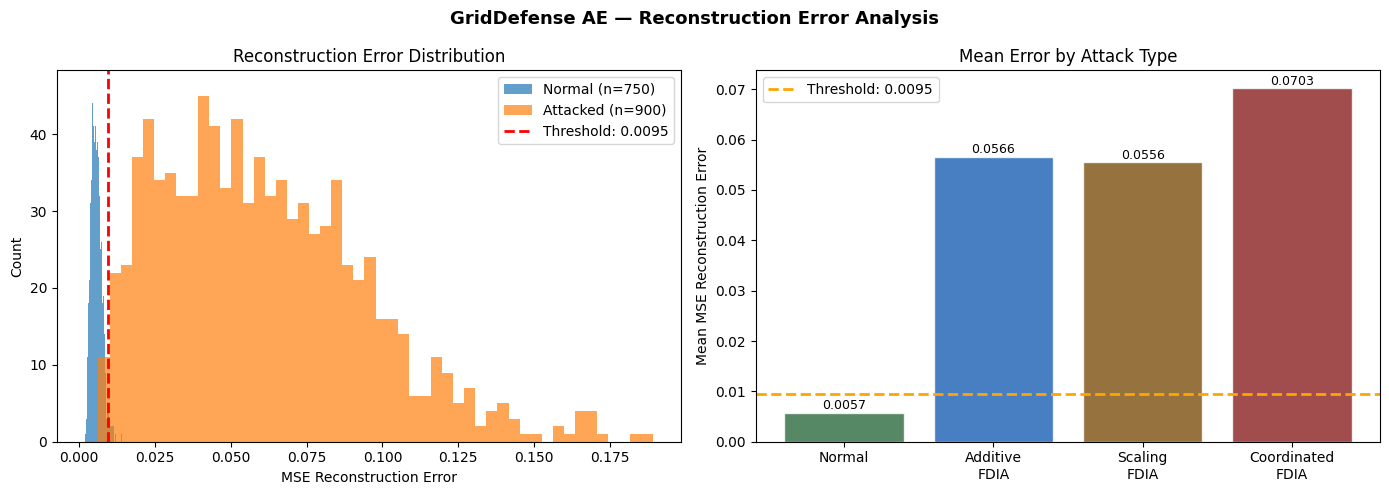


AE STEP 4 COMPLETE
Threshold (mean+2σ) : 0.009477
False positive rate : 2.67%
Attack detection    : 99.11%
AE, scaler and threshold saved to /content/drive/MyDrive/GridDefense/final_notebook ✓


In [19]:
# ============================================================
# GridDefense | AE — Step 4: Test Detection
# Uses global test split (normal + attacked together)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ── Reconstruct full test set ────────────────────────────────

test_pred   = autoencoder.predict(X_test_ae, verbose=0)
test_errors = np.mean(np.square(X_test_ae - test_pred), axis=1)

# Split errors by label using y_test_ae (Attack_Type)
normal_mask = (y_test_ae == 0)
attack_mask = (y_test_ae != 0)

normal_errors  = test_errors[normal_mask]
attacked_errors = test_errors[attack_mask]

print("=" * 60)
print("AE RECONSTRUCTION ERROR — TEST SET")
print("=" * 60)
print(f"\nNormal  : {normal_errors.mean():.6f} mean  |  {normal_errors.std():.6f} std  |  n={len(normal_errors)}")
print(f"Attacked: {attacked_errors.mean():.6f} mean  |  {attacked_errors.std():.6f} std  |  n={len(attacked_errors)}")
print(f"\nAttack/normal ratio: {attacked_errors.mean()/normal_errors.mean():.2f}x")


# ── Threshold from validation normal ────────────────────────

val_pred   = autoencoder.predict(X_val_ae, verbose=0)
val_errors = np.mean(np.square(X_val_ae - val_pred), axis=1)

threshold = val_errors.mean() + 2 * val_errors.std()
AE_THRESHOLD = float(threshold)   # kept under its own name for the later sections

print()
print("=" * 60)
print("VALIDATION THRESHOLD")
print("=" * 60)
print(f"Val mean : {val_errors.mean():.6f}")
print(f"Val std  : {val_errors.std():.6f}")
print(f"Threshold: {threshold:.6f}  (mean + 2σ)")


# ── Final detection ──────────────────────────────────────────

false_positives     = (normal_errors  > threshold).sum()
true_positives      = (attacked_errors > threshold).sum()
false_positive_rate = false_positives / len(normal_errors)
detection_rate      = true_positives  / len(attacked_errors)

print()
print("=" * 60)
print("FINAL TEST DETECTION")
print("=" * 60)
print(f"Normal false positives : {false_positives}/{len(normal_errors)} ({false_positive_rate*100:.2f}%)")
print(f"Attacks detected       : {true_positives}/{len(attacked_errors)} ({detection_rate*100:.2f}%)")


# ── Per attack type ──────────────────────────────────────────

print("\nDetection by attack type:")
for attack_name, atype in [("Additive", 1), ("Scaling", 2), ("Coordinated", 3)]:
    mask     = (y_test_ae == atype)
    errs     = test_errors[mask]
    detected = (errs > threshold).sum()
    rate     = detected / len(errs) if len(errs) > 0 else 0
    print(f"  {attack_name:12s}: {detected}/{len(errs)} ({rate*100:.2f}%)  mean_err={errs.mean():.6f}")


# ── Plot ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('GridDefense AE — Reconstruction Error Analysis', fontsize=13, fontweight='bold')

axes[0].hist(normal_errors,  bins=50, alpha=0.7, label=f'Normal (n={len(normal_errors)})')
axes[0].hist(attacked_errors, bins=50, alpha=0.7, label=f'Attacked (n={len(attacked_errors)})')
axes[0].axvline(threshold, linestyle='--', linewidth=2, color='red', label=f'Threshold: {threshold:.4f}')
axes[0].set_title('Reconstruction Error Distribution')
axes[0].set_xlabel('MSE Reconstruction Error')
axes[0].set_ylabel('Count')
axes[0].legend()

categories = ['Normal', 'Additive\nFDIA', 'Scaling\nFDIA', 'Coordinated\nFDIA']
means = [
    normal_errors.mean(),
    test_errors[y_test_ae == 1].mean(),
    test_errors[y_test_ae == 2].mean(),
    test_errors[y_test_ae == 3].mean()
]
colors = ['#2d6a3f', '#1a5fb4', '#7c4f0e', '#8a2020']

bars = axes[1].bar(categories, means, color=colors, alpha=0.8, edgecolor='white')
axes[1].axhline(threshold, linestyle='--', linewidth=2, color='orange', label=f'Threshold: {threshold:.4f}')
axes[1].set_title('Mean Error by Attack Type')
axes[1].set_ylabel('Mean MSE Reconstruction Error')
axes[1].legend()

for bar, val in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.0001,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/ae_detection_results.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print("=" * 60)
print("AE STEP 4 COMPLETE")
print("=" * 60)
print(f"Threshold (mean+2σ) : {threshold:.6f}")
print(f"False positive rate : {false_positive_rate*100:.2f}%")
print(f"Attack detection    : {detection_rate*100:.2f}%")
# Save the AE together with its scaler and threshold
import joblib, json
autoencoder.save(f'{OUT_DIR}/autoencoder.h5')
joblib.dump(scaler_ae, f'{OUT_DIR}/scaler_ae.pkl')
with open(f'{OUT_DIR}/ae_threshold.json', 'w') as _f:
    json.dump({'threshold_mean_plus_2sd': AE_THRESHOLD, 'seed': int(SEED),
               'val_mean': float(val_errors.mean()), 'val_std': float(val_errors.std()),
               'feature_cols': list(ae_feature_cols)}, _f, indent=2)
print(f"AE, scaler and threshold saved to {OUT_DIR} ✓")

## 6 · Random Forest classifier

In [20]:
# ============================================================
# GridDefense | Random Forest Classifier
# ============================================================
#
# Primary classifier for GridDefense.
#
# Features: 104 (non-redundant)
#   56 raw      : Vm, Va, Pd, Qd
#   14 P_res    : AC active power residual
#   14 Q_res    : AC reactive power residual
#   20 LineFlow : branch apparent power |S|
#
# No scaling required for Random Forest.
# Tree-based models are invariant to monotonic feature scaling.
#
# class_weight='balanced': predefined to compensate for the
# lower training frequency of each attack class relative to Normal
# (3500 Normal vs 1400 samples per attack type).
#
# oob_score=True: provides an out-of-bag training estimate.
#
# Literature:
#   Louppe et al. (2013) — Random Forest theory
#   Ashrafuzzaman et al. (2020) — RF for FDIA on IEEE 14-bus
#
# IMPORTANT:
#   BusBalance excluded — algebraically redundant with P_res.
#   Q_KCL excluded — reserved for physics validation layer.
#   bus_label_* excluded — ground-truth localization labels.
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np
import joblib
import os

print("=" * 60)
print("GridDefense — Random Forest Classifier (Primary)")
print("=" * 60)

# ── Feature set: 104 non-redundant ───────────────────────────

rf_feature_cols = (
    [f'Vm_{i+1}'       for i in range(14)] +
    [f'Va_{i+1}'       for i in range(14)] +
    [f'Pd_{i+1}'       for i in range(14)] +
    [f'Qd_{i+1}'       for i in range(14)] +
    [f'P_res_{i+1}'    for i in range(14)] +
    [f'Q_res_{i+1}'    for i in range(14)] +
    [f'LineFlow_{i+1}' for i in range(20)]
    # BusBalance excluded — = -P_res (algebraic identity, verified)
    # Q_KCL excluded — physics validation layer only
    # bus_label_* excluded — ground-truth labels, never model input
)

print(f"Features : {len(rf_feature_cols)} (non-redundant)")
print(f"Task     : 4-class classification")
print(f"           Normal / Additive / Scaling / Coordinated")
print()

# ── Same split as all other models ───────────────────────────

X_train_rf = df_full.iloc[list(train_idx)][rf_feature_cols].values
y_train_rf = (
    df_full.iloc[list(train_idx)]['Attack_Type']
    .astype(int)
    .values
)

X_val_rf = df_full.iloc[list(val_idx)][rf_feature_cols].values
y_val_rf = (
    df_full.iloc[list(val_idx)]['Attack_Type']
    .astype(int)
    .values
)

X_test_rf = df_full.iloc[list(test_idx)][rf_feature_cols].values
y_test_rf = (
    df_full.iloc[list(test_idx)]['Attack_Type']
    .astype(int)
    .values
)

print(f"Train : {X_train_rf.shape}")
print(f"Val   : {X_val_rf.shape}")
print(f"Test  : {X_test_rf.shape}")
print()

# ── Train ─────────────────────────────────────────────────────

print("Training Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators      = 500,    # Fixed ensemble size for final configuration
    max_depth         = None,   # Fully grown trees
    min_samples_split = 5,      # Light regularisation
    class_weight      = 'balanced',
    oob_score         = True,
    random_state      = 42,
    n_jobs            = -1
)

rf_model.fit(X_train_rf, y_train_rf)

print(f"✓ Trained {rf_model.n_estimators} trees")
print(f"  OOB training estimate : {rf_model.oob_score_:.4f}")
print()

# ── Development-test evaluation ──────────────────────────────

rf_pred = rf_model.predict(X_test_rf)

acc = accuracy_score(
    y_test_rf,
    rf_pred
)

mf1 = f1_score(
    y_test_rf,
    rf_pred,
    average='macro',
    zero_division=0
)

wf1 = f1_score(
    y_test_rf,
    rf_pred,
    average='weighted',
    zero_division=0
)

# Binary attack detection recall:
# Fraction of attacked samples correctly identified
# as any non-Normal class.

binary_detection_recall = (
    (rf_pred[y_test_rf != 0] != 0).mean() * 100
)

# False-positive rate:
# Fraction of normal samples incorrectly classified
# as an attack.

binary_fpr = (
    (rf_pred[y_test_rf == 0] != 0).mean() * 100
)

print("=" * 60)
print("RF TEST RESULTS")
print("=" * 60)

print(f"\n  4-class accuracy         : {acc * 100:.2f}%")
print(f"  Macro F1                 : {mf1:.4f}")
print(f"  Weighted F1              : {wf1:.4f}")
print(f"  Binary attack recall     : {binary_detection_recall:.2f}%")
print(f"  False-positive rate      : {binary_fpr:.2f}%")
print()

print(
    classification_report(
        y_test_rf,
        rf_pred,
        target_names=[
            'Normal',
            'Additive',
            'Scaling',
            'Coordinated'
        ],
        zero_division=0
    )
)

# ── Feature importance — top 15 ───────────────────────────────

print("=" * 60)
print("FEATURE IMPORTANCE — Top 15")
print("=" * 60)

importances = rf_model.feature_importances_

top15 = np.argsort(importances)[::-1][:15]

for rank, idx in enumerate(top15, 1):
    print(
        f"  {rank:2d}. "
        f"{rf_feature_cols[idx]:<25} "
        f"{importances[idx]:.4f}"
    )

# ── Save ──────────────────────────────────────────────────────

joblib.dump(rf_model,        f'{OUT_DIR}/rf_final.pkl')
joblib.dump(rf_feature_cols, f'{OUT_DIR}/rf_feature_cols.pkl')

print()
print(f"✓ rf_final.pkl and rf_feature_cols.pkl saved to {OUT_DIR}")
print()

# ── Summary ───────────────────────────────────────────────────

print("=" * 60)
print("SUMMARY")
print("=" * 60)

print(f"  4-class accuracy         : {acc * 100:.2f}%")
print(f"  Macro F1                 : {mf1:.4f}")
print(f"  Weighted F1              : {wf1:.4f}")
print(f"  Binary attack recall     : {binary_detection_recall:.2f}%")
print(f"  False-positive rate      : {binary_fpr:.2f}%")
print()
print("✓ Random Forest classifier configuration complete.")

GridDefense — Random Forest Classifier (Primary)
Features : 104 (non-redundant)
Task     : 4-class classification
           Normal / Additive / Scaling / Coordinated

Train : (7700, 104)
Val   : (1650, 104)
Test  : (1650, 104)

Training Random Forest...
✓ Trained 500 trees
  OOB training estimate : 0.8883

RF TEST RESULTS

  4-class accuracy         : 88.79%
  Macro F1                 : 0.8483
  Weighted F1              : 0.8863
  Binary attack recall     : 98.33%
  False-positive rate      : 0.53%

              precision    recall  f1-score   support

      Normal       0.98      0.99      0.99       750
    Additive       0.80      0.73      0.76       300
     Scaling       0.82      0.76      0.79       300
 Coordinated       0.81      0.91      0.85       300

    accuracy                           0.89      1650
   macro avg       0.85      0.85      0.85      1650
weighted avg       0.89      0.89      0.89      1650

FEATURE IMPORTANCE — Top 15
   1. Q_res_7                  

## 7 · Bus-level localisation

First a baseline localiser on the 104 detection features, then the final topology-aware localiser (172 features) with its threshold chosen on validation data. Bus 1 is the slack bus and is never attacked, so bus-level averages use buses 2–14.

In [21]:
# ============================================================
# GridDefense | RF Localization — Bus-Level Attack Detection
# ============================================================
#
# Purpose:
#   Identify which buses are suspected to be under attack.
#
# Separate from RF attack-type classifier.
#
# Input:
#   104 physics-enriched features
#
# Output:
#   bus_label_1 ... bus_label_14
#
# Model:
#   MultiOutputClassifier(RandomForestClassifier)
#
# Ground truth:
#   bus_label_1 ... bus_label_14 from Step 7
#
# Evaluation:
#   - Exact match rate
#   - Localization recall
#   - Micro F1
#   - Macro F1
#   - Mean per-bus F1
#   - Hamming loss
#   - Per-attack-type localization
#   - Per-bus F1
#
# IMPORTANT:
#   bus_label columns are ground truth ONLY.
#   They are NEVER used as model inputs.
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score, hamming_loss
import numpy as np
import joblib
import os

print("=" * 60)
print("GridDefense — RF Bus Localization")
print("=" * 60)


# ============================================================
# 1. BUS LABEL COLUMNS — GROUND TRUTH ONLY
# ============================================================

bus_label_cols = [f'bus_label_{i+1}' for i in range(14)]


# ============================================================
# 2. LEAKAGE CHECK
# ============================================================

forbidden_cols = bus_label_cols + ['Label', 'Attack_Type']

assert not any(
    c in rf_feature_cols for c in forbidden_cols
), "LEAKAGE: target/label column found in localization features"

print("✓ No target leakage — labels excluded from features")


# ============================================================
# 3. SAME GLOBAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train_loc = df_full.iloc[list(train_idx)][rf_feature_cols].values
y_train_loc = df_full.iloc[list(train_idx)][bus_label_cols].values

X_val_loc = df_full.iloc[list(val_idx)][rf_feature_cols].values
y_val_loc = df_full.iloc[list(val_idx)][bus_label_cols].values

X_test_loc = df_full.iloc[list(test_idx)][rf_feature_cols].values
y_test_loc = df_full.iloc[list(test_idx)][bus_label_cols].values

print()
print("Dataset shapes:")
print(f"  Train: {X_train_loc.shape} | Labels: {y_train_loc.shape}")
print(f"  Val  : {X_val_loc.shape}   | Labels: {y_val_loc.shape}")
print(f"  Test : {X_test_loc.shape}  | Labels: {y_test_loc.shape}")
print()


# ============================================================
# 4. TRAIN RF LOCALIZATION MODEL
# ============================================================

print("Training RF Localization model...")
print("  14 bus-level RF classifiers × 500 trees")
print()

base_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=1
)

rf_loc = MultiOutputClassifier(
    base_rf,
    n_jobs=-1
)

rf_loc.fit(
    X_train_loc,
    y_train_loc
)

print("✓ RF localization model trained")
print()


# ============================================================
# 5. TEST PREDICTIONS
# ============================================================

y_pred_loc = rf_loc.predict(X_test_loc)


# ============================================================
# 6. ATTACKED SAMPLES ONLY
# ============================================================
#
# Localization is evaluated on samples that actually contain
# at least one attacked bus.
# ============================================================

attacked_mask_loc = y_test_loc.sum(axis=1) > 0

y_true_att = y_test_loc[attacked_mask_loc]
y_pred_att = y_pred_loc[attacked_mask_loc]

print("=" * 60)
print("LOCALIZATION EVALUATION SET")
print("=" * 60)
print(f"  Total test samples       : {len(y_test_loc)}")
print(f"  Attacked test samples    : {len(y_true_att)}")
print(f"  Normal test samples     : {(~attacked_mask_loc).sum()}")
print()


# ============================================================
# 7. EXACT MATCH RATE
# ============================================================
#
# A prediction is correct only if ALL 14 bus labels exactly
# match the ground truth.
# ============================================================

exact_match = (
    (y_true_att == y_pred_att)
    .all(axis=1)
    .mean()
) * 100


# ============================================================
# 8. LOCALIZATION RECALL
# ============================================================
#
# Fraction of the truly attacked buses that were correctly
# identified.
#
# Example:
#   True buses = {3, 8, 10}
#   Predicted  = {3, 10}
#
#   Localization recall = 2 / 3 = 66.7%
# ============================================================

localization_recall_per_sample = []

for i in range(len(y_true_att)):

    true_buses = set(
        np.where(y_true_att[i] == 1)[0]
    )

    pred_buses = set(
        np.where(y_pred_att[i] == 1)[0]
    )

    if len(true_buses) > 0:

        overlap = len(
            true_buses & pred_buses
        ) / len(true_buses)

        localization_recall_per_sample.append(
            overlap
        )

localization_recall = (
    np.mean(localization_recall_per_sample)
) * 100


# ============================================================
# 9. PER-BUS F1
# ============================================================

bus_f1 = []

for b in range(14):

    f1 = f1_score(
        y_true_att[:, b],
        y_pred_att[:, b],
        zero_division=0
    )

    bus_f1.append(f1)

# Bus 1 (index 0) is the slack bus and is never attacked, so its F1
# is undefined (always 0). Bus-level averages use buses 2–14.
ATTACKABLE_BUSES = np.arange(1, 14)
mean_bus_f1 = np.mean([bus_f1[b] for b in ATTACKABLE_BUSES]) * 100


# ============================================================
# 10. MICRO / MACRO F1
# ============================================================

micro_f1 = f1_score(
    y_true_att,
    y_pred_att,
    average='micro',
    zero_division=0
) * 100

macro_f1 = f1_score(
    y_true_att[:, ATTACKABLE_BUSES],
    y_pred_att[:, ATTACKABLE_BUSES],
    average='macro',
    zero_division=0
) * 100


# ============================================================
# 11. HAMMING LOSS
# ============================================================
#
# Percentage of all bus labels that were incorrectly predicted.
# ============================================================

h_loss = (
    hamming_loss(
        y_true_att,
        y_pred_att
    )
) * 100


# ============================================================
# 12. OVERALL LOCALIZATION RESULTS
# ============================================================

print("=" * 60)
print("RF LOCALIZATION RESULTS — ATTACKED SAMPLES")
print("=" * 60)

print()
print(f"  Exact match rate    : {exact_match:.1f}%")
print(
    f"  Localization recall : {localization_recall:.1f}%"
)
print(
    "    (fraction of true attacked buses correctly identified)"
)
print(f"  Mean bus F1         : {mean_bus_f1:.1f}%")
print(f"  Micro bus F1        : {micro_f1:.1f}%")
print(f"  Macro bus F1        : {macro_f1:.1f}%")
print(f"  Hamming loss        : {h_loss:.1f}%")
print(
    "    (% of bus labels incorrectly predicted)"
)
print()


# ============================================================
# 13. LOCALIZATION BY ATTACK TYPE
# ============================================================

print("Per attack type localization:")
print()

test_type = df_full.iloc[
    list(test_idx)
]['Attack_Type'].values

for atype, name in [
    (1, 'Additive'),
    (2, 'Scaling'),
    (3, 'Coordinated')
]:

    mask = test_type == atype

    if mask.sum() == 0:
        continue

    yt = y_test_loc[mask]
    yp = y_pred_loc[mask]

    # Exact match
    em = (
        (yt == yp)
        .all(axis=1)
        .mean()
    ) * 100

    # Localization recall
    recall_values = []

    for i in range(len(yt)):

        true_buses = set(
            np.where(yt[i] == 1)[0]
        )

        pred_buses = set(
            np.where(yp[i] == 1)[0]
        )

        if len(true_buses) > 0:

            recall_values.append(
                len(true_buses & pred_buses)
                / len(true_buses)
            )

    type_recall = (
        np.mean(recall_values) * 100
        if recall_values
        else 0
    )

    print(
        f"  {name:<14}: "
        f"exact={em:.1f}%  "
        f"localization recall={type_recall:.1f}%"
    )

print()


# ============================================================
# 14. PER-BUS LOCALIZATION F1
# ============================================================

print("Per-bus localization F1:")
print()

print(
    f"  {'Bus':<6}"
    f"{'F1':>8}"
    f"{'True attacked%':>18}"
    f"{'Pred attacked%':>18}"
)

print("  " + "-" * 54)

for b in range(14):

    if b == 0:
        print(f"  Bus 1  {'—':>7}   (slack bus, never attacked — not scored)")
        continue

    true_rate = (
        y_true_att[:, b].mean()
    ) * 100

    pred_rate = (
        y_pred_att[:, b].mean()
    ) * 100

    print(
        f"  Bus {b+1:<3}"
        f"{bus_f1[b]:>8.3f}"
        f"{true_rate:>17.1f}%"
        f"{pred_rate:>17.1f}%"
    )

print()



# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("=" * 60)
print("LOCALIZATION SUMMARY")
print("=" * 60)

print(
    f"""
GridDefense Bus Localization (RF):

  Exact match         : {exact_match:.1f}%
  Localization recall : {localization_recall:.1f}%
  Mean bus F1         : {mean_bus_f1:.1f}%
  Micro bus F1        : {micro_f1:.1f}%
  Macro bus F1        : {macro_f1:.1f}%
  Hamming loss        : {h_loss:.1f}%

Purpose:
  Identify which buses are suspected to be attacked.

The localization model is separate from the RF attack-type
classifier.

The decision layer can therefore combine:

  AE                 → measurement anomaly evidence
  RF type classifier → attack type
  RF localization    → suspected attacked bus(es)
  Physics layer      → physical consistency evidence
"""
)

print("=" * 60)
print("✓ RF LOCALIZATION COMPLETE")
print("=" * 60)

GridDefense — RF Bus Localization
✓ No target leakage — labels excluded from features

Dataset shapes:
  Train: (7700, 104) | Labels: (7700, 14)
  Val  : (1650, 104)   | Labels: (1650, 14)
  Test : (1650, 104)  | Labels: (1650, 14)

Training RF Localization model...
  14 bus-level RF classifiers × 500 trees

✓ RF localization model trained

LOCALIZATION EVALUATION SET
  Total test samples       : 1650
  Attacked test samples    : 900
  Normal test samples     : 750

RF LOCALIZATION RESULTS — ATTACKED SAMPLES

  Exact match rate    : 91.1%
  Localization recall : 95.8%
    (fraction of true attacked buses correctly identified)
  Mean bus F1         : 97.6%
  Micro bus F1        : 97.7%
  Macro bus F1        : 97.6%
  Hamming loss        : 0.7%
    (% of bus labels incorrectly predicted)

Per attack type localization:

  Additive      : exact=92.7%  localization recall=96.4%
  Scaling       : exact=93.3%  localization recall=96.3%
  Coordinated   : exact=87.3%  localization recall=94.6%


In [22]:
# ═══════════════════════════════════════════════════════════════════
# GRIDDEFENSE — FINAL BUS LOCALISATION
# 172 features | Random Forest | Single vs Dual Threshold
#
# A = Primary model: single validation-selected threshold
# B = Additional experiment: predicted attack-type routing
# NOTE: attack types follow Step 7 — 1=Additive, 2=Scaling (Vm only), 3=Coordinated.
# Internal variable names containing 'va' refer to class 2 (Scaling).
# Macro F1 is computed over the 13 attackable buses (Bus 1 is never attacked).
#
# IMPORTANT:
# - X_*_rf contains the original 104 features.
# - y_*_loc contains 14 binary bus-localisation labels.
# - y_*_rf contains attack type labels: 0, 1, 2, 3.
# - rf_model is the already-trained attack-type classifier.
# - Features and labels MUST remain aligned row-by-row.
# ═══════════════════════════════════════════════════════════════════

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score

# Map global session's rf_model to rf_type
rf_type = rf_model

# ── 1. PRE-FLIGHT CHECKS ──────────────────────────────────────────

print("=" * 68)
print("GRIDDEFENSE — PRE-FLIGHT CHECKS")
print("=" * 68)

X_train_base = np.asarray(X_train_rf)
X_val_base   = np.asarray(X_val_rf)
X_test_base  = np.asarray(X_test_rf)

y_train_bus = np.asarray(y_train_loc, dtype=int)
y_val_bus   = np.asarray(y_val_loc, dtype=int)
y_test_bus  = np.asarray(y_test_loc, dtype=int)

y_train_type = np.asarray(y_train_rf).ravel().astype(int)
y_val_type   = np.asarray(y_val_rf).ravel().astype(int)
y_test_type  = np.asarray(y_test_rf).ravel().astype(int)

# Dimensions
assert X_train_base.ndim == 2
assert X_val_base.ndim == 2
assert X_test_base.ndim == 2

assert X_train_base.shape[1] == 104
assert X_val_base.shape[1] == 104
assert X_test_base.shape[1] == 104

assert y_train_bus.shape == (len(X_train_base), 14)
assert y_val_bus.shape == (len(X_val_base), 14)
assert y_test_bus.shape == (len(X_test_base), 14)

assert len(y_train_type) == len(X_train_base)
assert len(y_val_type) == len(X_val_base)
assert len(y_test_type) == len(X_test_base)

# Label validity
for split_name, y_type, y_bus in [
    ("Train", y_train_type, y_train_bus),
    ("Validation", y_val_type, y_val_bus),
    ("Test", y_test_type, y_test_bus),
]:
    assert set(np.unique(y_type)).issubset({0, 1, 2, 3}), (
        f"{split_name}: unexpected attack-type labels"
    )
    assert set(np.unique(y_bus)).issubset({0, 1}), (
        f"{split_name}: bus labels must be binary"
    )

    normal_mask = (y_type == 0)
    assert np.all(y_bus[normal_mask] == 0), (
        f"{split_name}: normal samples have nonzero bus labels"
    )

    assert np.any(normal_mask), (
        f"{split_name}: no normal samples available"
    )
    assert np.any(~normal_mask), (
        f"{split_name}: no attacked samples available"
    )

assert np.any(y_train_type == 1)
assert np.any(y_train_type == 2)
assert np.any(y_train_type == 3)

assert "rf_feature_cols" in globals(), (
    "rf_feature_cols is missing. Run the original feature-preparation cells."
)
assert "rf_type" in globals() and hasattr(rf_type, "predict"), (
    "The fitted attack-type classifier rf_type is missing."
)

print(f"Train:      {X_train_base.shape}")
print(f"Validation: {X_val_base.shape}")
print(f"Test:       {X_test_base.shape}")
print("✓ Shape and label checks passed.")

print(
    f"Train distribution: "
    f"{np.sum(y_train_type == 0)} normal, "
    f"{np.sum(y_train_type != 0)} attacked"
)

# NOTE: matching lengths cannot prove row-by-row alignment.
# Confirm that each feature array and its labels use identical split
# indices and identical row order from the original dataset.


# ── 2. IEEE 14-BUS ADJACENCY ──────────────────────────────────────

NEIGHBORS = {
    1:  [2, 5],
    2:  [1, 3, 4, 5],
    3:  [2, 4],
    4:  [2, 3, 5, 7, 9],
    5:  [1, 2, 4, 6],
    6:  [5, 11, 12, 13],
    7:  [4, 8, 9],
    8:  [7],
    9:  [4, 7, 10, 14],
    10: [9, 11],
    11: [6, 10],
    12: [6, 13],
    13: [6, 12, 14],
    14: [9, 13],
}

# Derive exact two-hop neighbours from the adjacency instead of
# manually maintaining lists. Exclude the bus itself and its
# immediate neighbours.
NEIGHBORS_2 = {}

for bus in (3, 11, 14):
    two_hop_candidates = set()

    for first_hop_bus in NEIGHBORS[bus]:
        two_hop_candidates.update(NEIGHBORS[first_hop_bus])

    two_hop_candidates.discard(bus)
    two_hop_candidates -= set(NEIGHBORS[bus])

    NEIGHBORS_2[bus] = sorted(two_hop_candidates)

expected_two_hop = {
    3:  [1, 5, 7, 9],
    11: [5, 9, 12, 13],
    14: [4, 6, 7, 10, 12],
}

assert NEIGHBORS_2 == expected_two_hop, (
    f"Unexpected second-order neighbours: {NEIGHBORS_2}"
)

print("\nSecond-order neighbour lists:")
for bus, neighbours in NEIGHBORS_2.items():
    print(f"  Bus {bus}: {neighbours}")


# ── 3. FEATURE NAMES AND ORDER ────────────────────────────────────

feat_names = (
    [f"Vm_{i}" for i in range(1, 15)]
    + [f"Va_{i}" for i in range(1, 15)]
    + [f"Pd_{i}" for i in range(1, 15)]
    + [f"Qd_{i}" for i in range(1, 15)]
    + [f"P_res_{i}" for i in range(1, 15)]
    + [f"Q_res_{i}" for i in range(1, 15)]
    + [f"LineFlow_{i}" for i in range(1, 21)]
)

assert len(feat_names) == 104
assert list(rf_feature_cols) == feat_names, (
    "Feature names/order differ from rf_feature_cols."
)

print("\n✓ Base feature names and order verified.")


# ── 4. TOPOLOGY FEATURE BUILDER ───────────────────────────────────

def add_topo_features(X_arr):
    """Add 56 first-order and 12 selected second-order features."""
    X_arr = np.asarray(X_arr)

    if X_arr.ndim != 2 or X_arr.shape[1] != 104:
        raise ValueError(
            f"Expected an (n, 104) array; received {X_arr.shape}"
        )

    df = pd.DataFrame(X_arr, columns=feat_names)
    new_cols = {}

    # First-order features: 4 per bus × 14 buses = 56.
    for bus in range(1, 15):
        neighbours = NEIGHBORS[bus]

        own_vm = df[f"Vm_{bus}"].to_numpy()
        own_va = df[f"Va_{bus}"].to_numpy()

        neighbour_vm = df[
            [f"Vm_{n}" for n in neighbours]
        ].to_numpy().mean(axis=1)

        new_cols[f"neigh_Vm_{bus}"] = neighbour_vm
        new_cols[f"diff_Vm_{bus}"] = own_vm - neighbour_vm

        angles = np.deg2rad(
            df[[f"Va_{n}" for n in neighbours]].to_numpy()
        )

        neighbour_va = np.rad2deg(
            np.arctan2(
                np.sin(angles).mean(axis=1),
                np.cos(angles).mean(axis=1),
            )
        )

        new_cols[f"neigh_Va_{bus}"] = neighbour_va
        new_cols[f"diff_Va_{bus}"] = (
            (own_va - neighbour_va + 180) % 360
        ) - 180

    # Second-order features: 4 per selected bus × 3 buses = 12.
    for bus, neighbours in NEIGHBORS_2.items():
        own_vm = df[f"Vm_{bus}"].to_numpy()
        own_va = df[f"Va_{bus}"].to_numpy()

        neighbour_vm = df[
            [f"Vm_{n}" for n in neighbours]
        ].to_numpy().mean(axis=1)

        new_cols[f"neigh2_Vm_{bus}"] = neighbour_vm
        new_cols[f"diff2_Vm_{bus}"] = own_vm - neighbour_vm

        angles = np.deg2rad(
            df[[f"Va_{n}" for n in neighbours]].to_numpy()
        )

        neighbour_va = np.rad2deg(
            np.arctan2(
                np.sin(angles).mean(axis=1),
                np.cos(angles).mean(axis=1),
            )
        )

        new_cols[f"neigh2_Va_{bus}"] = neighbour_va
        new_cols[f"diff2_Va_{bus}"] = (
            (own_va - neighbour_va + 180) % 360
        ) - 180

    extra = pd.DataFrame(new_cols).to_numpy()
    output = np.hstack([X_arr, extra])

    assert output.shape == (len(X_arr), 172), (
        f"Expected 172 features, got {output.shape}"
    )
    assert np.isfinite(output).all(), (
        "Non-finite values found in the extended features."
    )

    return output


print("\nBuilding 172-feature datasets...")

X_tr = add_topo_features(X_train_base)
X_va = add_topo_features(X_val_base)

print(f"Train extended: {X_tr.shape}")
print(f"Validation extended: {X_va.shape}")


# ── 5. TRAIN LOCALISATION MODEL ───────────────────────────────────

print("\nTraining topology-aware Random Forest (200 trees)...")

rf_loc_final = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_split=5,
        n_jobs=-1,
    ),
    n_jobs=1,
)

rf_loc_final.fit(X_tr, y_train_bus)

print("✓ Localisation model trained.")


# ── 6. EXTRACT BUS PROBABILITIES ──────────────────────────────────

def get_bus_probas(model, X):
    """Return positive-class probabilities for all 14 bus classifiers."""
    X = np.asarray(X)
    probabilities = []

    for estimator in model.estimators_:
        p = estimator.predict_proba(X)
        classes = estimator.classes_

        positive_indices = np.where(classes == 1)[0]

        if len(positive_indices) == 0:
            probabilities.append(np.zeros(len(X)))
        else:
            probabilities.append(p[:, positive_indices[0]])

    result = np.column_stack(probabilities)

    assert result.shape == (len(X), 14)
    assert np.isfinite(result).all()

    return result


val_probas = get_bus_probas(rf_loc_final, X_va)

norm_val = (y_val_type == 0)
atk_val = ~norm_val

norm_te = (y_test_type == 0)
atk_te = ~norm_te

FALSE_LOC_LIMIT = 0.05


# ── 7. A — PRIMARY: SINGLE THRESHOLD ──────────────────────────────

print("\nTuning single threshold on validation data...")

best_ex_A = -1.0
best_th_A = None
best_fl_A = None

# Use integer steps to avoid floating-point step inconsistencies.
for threshold_int in range(20, 71):
    loc_th = threshold_int / 100.0

    yp_val = (val_probas >= loc_th).astype(int)

    false_loc = np.mean(
        np.any(yp_val[norm_val] == 1, axis=1)
    )

    if false_loc > FALSE_LOC_LIMIT:
        continue

    exact_match = np.mean(
        np.all(
            yp_val[atk_val] == y_val_bus[atk_val],
            axis=1,
        )
    )

    if exact_match > best_ex_A:
        best_ex_A = exact_match
        best_th_A = loc_th
        best_fl_A = false_loc

assert best_th_A is not None, (
    "No single threshold met the validation false-localisation limit."
)

BASE_THRESH = best_th_A

print(f"Selected single threshold: {best_th_A:.2f}")
print(f"Validation attacked exact match: {best_ex_A * 100:.2f}%")
print(f"Validation normal false-localisation: {best_fl_A * 100:.2f}%")


# ── 8. B — ADDITIONAL: DUAL-THRESHOLD EXPERIMENT ──────────────────

print("\nPredicting attack types for threshold routing...")

# rf_type must be trained already; do not fit it on validation/test data.
y_val_type_pred = np.asarray(
    rf_type.predict(X_val_base)
).ravel().astype(int)

assert set(np.unique(y_val_type_pred)).issubset({0, 1, 2, 3})

routing_acc_val = np.mean(
    y_val_type_pred == y_val_type
)

print(f"Validation type-routing accuracy: {routing_acc_val * 100:.2f}%")

best_ex_B = -1.0
best_th_B = None
best_fl_B = None

va_routed_val = (y_val_type_pred == 2)

# Tune the Scaling (class 2) threshold using validation only.
# All other predicted types use the validation-selected primary threshold.
for threshold_int in range(20, int(round(BASE_THRESH * 100)) + 1):
    va_threshold = threshold_int / 100.0

    yp_val_B = np.zeros_like(val_probas, dtype=int)

    yp_val_B[va_routed_val] = (
        val_probas[va_routed_val] >= va_threshold
    ).astype(int)

    yp_val_B[~va_routed_val] = (
        val_probas[~va_routed_val] >= BASE_THRESH
    ).astype(int)

    false_loc = np.mean(
        np.any(yp_val_B[norm_val] == 1, axis=1)
    )

    if false_loc > FALSE_LOC_LIMIT:
        continue

    exact_match = np.mean(
        np.all(
            yp_val_B[atk_val] == y_val_bus[atk_val],
            axis=1,
        )
    )

    if exact_match > best_ex_B:
        best_ex_B = exact_match
        best_th_B = va_threshold
        best_fl_B = false_loc

assert best_th_B is not None, (
    "No dual-threshold setting met the validation false-localisation limit."
)

print(f"Selected Scaling threshold: {best_th_B:.2f}")
print(f"Non-Scaling threshold: {BASE_THRESH:.2f}")
print(f"Validation attacked exact match: {best_ex_B * 100:.2f}%")
print(f"Validation normal false-localisation: {best_fl_B * 100:.2f}%")


# ── 9. FREEZE THRESHOLDS; EVALUATE TEST ONCE ──────────────────────

print("\nFreezing thresholds and evaluating the test set...")

# Construct test features only now, after threshold selection.
X_te = add_topo_features(X_test_base)
test_probas = get_bus_probas(rf_loc_final, X_te)

# A: Single threshold
yp_A = (test_probas >= best_th_A).astype(int)

# B: Predicted-type dual threshold
y_test_type_pred = np.asarray(
    rf_type.predict(X_test_base)
).ravel().astype(int)

assert set(np.unique(y_test_type_pred)).issubset({0, 1, 2, 3})

va_routed_te = (y_test_type_pred == 2)

yp_B = np.zeros_like(test_probas, dtype=int)

yp_B[va_routed_te] = (
    test_probas[va_routed_te] >= best_th_B
).astype(int)

yp_B[~va_routed_te] = (
    test_probas[~va_routed_te] >= BASE_THRESH
).astype(int)


# ── 10. EVALUATION HELPERS ────────────────────────────────────────

def evaluate_localisation(y_true_bus, y_pred_bus, normal_mask, attacked_mask):
    false_localisation = np.mean(
        np.any(y_pred_bus[normal_mask] == 1, axis=1)
    )

    exact_match = np.mean(
        np.all(
            y_pred_bus[attacked_mask] == y_true_bus[attacked_mask],
            axis=1,
        )
    )

    micro_f1 = f1_score(
        y_true_bus[attacked_mask],
        y_pred_bus[attacked_mask],
        average="micro",
        zero_division=0,
    )

    macro_f1 = f1_score(
        y_true_bus[attacked_mask][:, 1:],   # buses 2–14
        y_pred_bus[attacked_mask][:, 1:],
        average="macro",
        zero_division=0,
    )

    return {
        "exact_match": exact_match,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "false_localisation": false_localisation,
    }


metrics_A = evaluate_localisation(
    y_test_bus, yp_A, norm_te, atk_te
)

metrics_B = evaluate_localisation(
    y_test_bus, yp_B, norm_te, atk_te
)


# ── 11. PRINT TEST RESULTS ────────────────────────────────────────

def print_results(title, metrics, threshold_text, y_pred):
    print("\n" + "=" * 68)
    print(title)
    print("=" * 68)
    print(f"Thresholds: {threshold_text}")
    print(f"Test samples: {len(y_test_type)}")
    print(f"Normal: {norm_te.sum()} | Attacked: {atk_te.sum()}")
    print(f"Exact match (attacked): {metrics['exact_match'] * 100:.2f}%")
    print(f"Micro F1 (attacked):    {metrics['micro_f1'] * 100:.2f}%")
    print(f"Macro F1 (attacked):    {metrics['macro_f1'] * 100:.2f}%")
    print(
        f"Normal false-localisation: "
        f"{metrics['false_localisation'] * 100:.2f}%"
    )
    print(
        f"Meets 5% limit: "
        f"{metrics['false_localisation'] <= FALSE_LOC_LIMIT}"
    )

    print("\nPer-attack results:")
    for attack_type, name in [
        (1, "Additive"),
        (2, "Scaling"),
        (3, "Coordinated"),
    ]:
        mask = (y_test_type == attack_type)

        if not np.any(mask):
            print(f"  {name}: no test samples")
            continue

        exact = np.mean(
            np.all(y_pred[mask] == y_test_bus[mask], axis=1)
        )

        micro = f1_score(
            y_test_bus[mask],
            y_pred[mask],
            average="micro",
            zero_division=0,
        )

        print(
            f"  {name} (n={mask.sum()}): "
            f"Exact={exact * 100:.2f}% | "
            f"Micro F1={micro * 100:.2f}%"
        )


print_results(
    "(A) PRIMARY — SINGLE THRESHOLD",
    metrics_A,
    f"{best_th_A:.2f}",
    yp_A,
)

print_results(
    "(B) ADDITIONAL — DUAL THRESHOLD",
    metrics_B,
    f"Scaling={best_th_B:.2f}, other={BASE_THRESH:.2f}",
    yp_B,
)

delta = metrics_B['exact_match'] - metrics_A['exact_match']

print("\n" + "=" * 68)
print("A vs B — TEST COMPARISON")
print("=" * 68)
print(f"{'Metric':<28}{'A: Single':>15}{'B: Dual':>15}")
print("-" * 58)
print(
    f"{'Exact match':<28}"
    f"{metrics_A['exact_match'] * 100:>14.2f}%"
    f"{metrics_B['exact_match'] * 100:>14.2f}%"
)
print(
    f"{'Micro F1':<28}"
    f"{metrics_A['micro_f1'] * 100:>14.2f}%"
    f"{metrics_B['micro_f1'] * 100:>14.2f}%"
)
print(
    f"{'Macro F1':<28}"
    f"{metrics_A['macro_f1'] * 100:>14.2f}%"
    f"{metrics_B['macro_f1'] * 100:>14.2f}%"
)
print(
    f"{'Normal false-localisation':<28}"
    f"{metrics_A['false_localisation'] * 100:>14.2f}%"
    f"{metrics_B['false_localisation'] * 100:>14.2f}%"
)
print(f"\nDual-threshold exact-match difference: {delta * 100:+.2f} percentage points")
print("Primary method = A (single validation-selected threshold); B is an additional experiment.")


# ── 12. SAVE MODEL, THRESHOLDS, CONFIGURATION AND RESULTS ─────────

save_path = OUT_DIR + "/"
os.makedirs(save_path, exist_ok=True)

joblib.dump(
    rf_loc_final,
    os.path.join(save_path, "rf_loc_final_172feat.pkl"),
)

config = {
    "feature_count": 172,
    "base_feature_count": 104,
    "first_order_feature_count": 56,
    "second_order_feature_count": 12,
    "feature_names_base": feat_names,
    "neighbors": NEIGHBORS,
    "second_order_neighbors": NEIGHBORS_2,
    "single_threshold": float(best_th_A),
    "dual_va_threshold": float(best_th_B),   # legacy key name: class 2 = Scaling
    "dual_other_threshold": float(BASE_THRESH),
    "false_localisation_limit": float(FALSE_LOC_LIMIT),
    "model_parameters": {
        "n_estimators": 200,
        "random_state": 42,
        "class_weight": "balanced",
        "min_samples_split": 5,
    },
    "test_metrics_single": {
        k: float(v) for k, v in metrics_A.items()
    },
    "test_metrics_dual": {
        k: float(v) for k, v in metrics_B.items()
    },
}

joblib.dump(
    config,
    os.path.join(save_path, "loc_thresholds_and_config.pkl"),
)

np.save(os.path.join(save_path, "yp_loc_A_test.npy"), yp_A)
np.save(os.path.join(save_path, "yp_loc_B_test.npy"), yp_B)
np.save(os.path.join(save_path, "probas_loc_final_test.npy"), test_probas)

print("\nSaved model, configuration, thresholds and predictions to:")
print(save_path)
print("✓ Localisation evaluation complete.")

GRIDDEFENSE — PRE-FLIGHT CHECKS
Train:      (7700, 104)
Validation: (1650, 104)
Test:       (1650, 104)
✓ Shape and label checks passed.
Train distribution: 3500 normal, 4200 attacked

Second-order neighbour lists:
  Bus 3: [1, 5, 7, 9]
  Bus 11: [5, 9, 12, 13]
  Bus 14: [4, 6, 7, 10, 12]

✓ Base feature names and order verified.

Building 172-feature datasets...
Train extended: (7700, 172)
Validation extended: (1650, 172)

Training topology-aware Random Forest (200 trees)...
✓ Localisation model trained.

Tuning single threshold on validation data...
Selected single threshold: 0.31
Validation attacked exact match: 96.67%
Validation normal false-localisation: 0.80%

Predicting attack types for threshold routing...
Validation type-routing accuracy: 89.52%
Selected Scaling threshold: 0.29
Non-Scaling threshold: 0.31
Validation attacked exact match: 96.67%
Validation normal false-localisation: 0.80%

Freezing thresholds and evaluating the test set...

(A) PRIMARY — SINGLE THRESHOLD
Thresh

## 8 · Physics validation layer and fusion

Physics: per-bus checks are standardised with the mean and standard deviation of normal **training** data. The z-score limit is chosen on normal **validation** data (the first value with under 5 % false alarms when 2 checks must agree). Fusion weights and threshold are chosen by F1 on **validation** data. The tables in this section use the development-test split.

In [23]:
# ============================================================
# GridDefense | Combined Evaluation — AE + RF
# ============================================================
#
# Combines:
#   AE  — 56 feature anomaly detection (unsupervised)
#   RF  — 104 feature attack classification (supervised)
#
# Both evaluated on the SAME test set (test_idx)
# AE flags: reconstruction error > threshold
# RF flags: predicted class != Normal (class 0)
#
# Fusion strategies:
#   Either (OR):  AE OR RF flags → alarm
#   Both  (AND):  AE AND RF flag → alarm
# ============================================================

import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score

print("=" * 65)
print("GRIDDEFENSE — AE + RF COMBINED EVALUATION")
print("=" * 65)
print()

# ── Same development-test rows for both models ─────────────────
# (750 normal + 900 attacked, test_idx)

# Ground truth from RF test set
true_label = (y_test_rf != 0).astype(int)   # binary: 0=normal, 1=attack
true_type  = y_test_rf                       # 4-class

# ── AE scores on RF test set ──────────────────────────────────
# Recompute AE reconstruction error on test_idx samples
test_df = df_full.iloc[list(test_idx)].reset_index(drop=True)

ae_cols = (
    [f'Vm_{i+1}' for i in range(14)] +
    [f'Va_{i+1}' for i in range(14)] +
    [f'Pd_{i+1}' for i in range(14)] +
    [f'Qd_{i+1}' for i in range(14)]
)

test_ae_raw    = test_df[ae_cols].values
test_ae_scaled = scaler_ae.transform(test_ae_raw)
test_ae_pred   = autoencoder.predict(test_ae_scaled, verbose=0)
test_ae_errors = np.mean(np.square(test_ae_scaled - test_ae_pred), axis=1)

# AE binary flag using threshold from Step 4
ae_flags = (test_ae_errors > AE_THRESHOLD).astype(int)

# RF binary flag
rf_flags = (rf_pred != 0).astype(int)

print(f"Test set: {len(true_label)} samples")
print(f"  Normal  : {(true_label==0).sum()}")
print(f"  Attacked: {(true_label==1).sum()}")
print()
print(f"Individual performance on this test set:")
print(f"  AE  detection: {ae_flags[true_label==1].mean()*100:.2f}%  "
      f"FP: {ae_flags[true_label==0].mean()*100:.2f}%")
print(f"  RF  detection: {rf_flags[true_label==1].mean()*100:.2f}%  "
      f"FP: {rf_flags[true_label==0].mean()*100:.2f}%")
print()

# ── Helper ────────────────────────────────────────────────────
def metrics(yt, yp, name, width=35):
    tp = ((yp==1)&(yt==1)).sum()
    fp = ((yp==1)&(yt==0)).sum()
    fn = ((yp==0)&(yt==1)).sum()
    tn = ((yp==0)&(yt==0)).sum()
    det  = tp/(tp+fn)*100 if tp+fn>0 else 0
    fpr  = fp/(fp+tn)*100 if fp+tn>0 else 0
    prec = tp/(tp+fp) if tp+fp>0 else 0
    rec  = tp/(tp+fn) if tp+fn>0 else 0
    f1   = 2*prec*rec/(prec+rec) if prec+rec>0 else 0
    print(f"  {name:<{width}} {det:>8.1f}%  {fpr:>7.1f}%  {f1:>8.4f}")
    return det, fpr, f1

# ── Combined results ──────────────────────────────────────────
either = ((ae_flags + rf_flags) >= 1).astype(int)   # OR
both   = ((ae_flags + rf_flags) >= 2).astype(int)   # AND

print("=" * 65)
print("COMBINED RESULTS")
print("=" * 65)
print(f"  {'Model':<35} {'Detection':>9}  {'FP Rate':>7}  {'F1':>8}")
print("-" * 65)
print("  Individual:")
metrics(true_label, ae_flags, "  AE alone (56 features)")
metrics(true_label, rf_flags, "  RF alone (104 features)")
print()
print("  Combined:")
metrics(true_label, either,   "  AE + RF (either)")
metrics(true_label, both,     "  AE + RF (both)")

# ── Per attack type ───────────────────────────────────────────
print()
print("Per attack type detection:")
print(f"  {'Attack':<14} {'AE':>8} {'RF':>8} {'Either':>8} {'Both':>8}")
print("  " + "-" * 44)
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask = true_type == atype
    ae_r = ae_flags[mask].mean() * 100
    rf_r = rf_flags[mask].mean() * 100
    ei_r = either[mask].mean()   * 100
    bo_r = both[mask].mean()     * 100
    print(f"  {name:<14} {ae_r:>7.1f}%  {rf_r:>7.1f}%  "
          f"{ei_r:>7.1f}%  {bo_r:>7.1f}%")

# ── AE score continuous analysis ─────────────────────────────
print()
print("AE reconstruction error by class:")
print(f"  Normal      : {test_ae_errors[true_label==0].mean():.6f}")
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask = true_type == atype
    print(f"  {name:<12}: {test_ae_errors[mask].mean():.6f}")

print()
print("=" * 65)
print("SUMMARY")
print("=" * 65)
def get_metrics(yt, yp):
    tp=((yp==1)&(yt==1)).sum(); fp=((yp==1)&(yt==0)).sum()
    fn=((yp==0)&(yt==1)).sum(); tn=((yp==0)&(yt==0)).sum()
    det=tp/(tp+fn)*100 if tp+fn>0 else 0
    fpr=fp/(fp+tn)*100 if fp+tn>0 else 0
    prec=tp/(tp+fp) if tp+fp>0 else 0
    rec=tp/(tp+fn) if tp+fn>0 else 0
    f1=2*prec*rec/(prec+rec) if prec+rec>0 else 0
    return det, fpr, f1

d_ae,  f_ae,  f1_ae  = get_metrics(true_label, ae_flags)
d_rf,  f_rf,  f1_rf  = get_metrics(true_label, rf_flags)
d_ei,  f_ei,  f1_ei  = get_metrics(true_label, either)
d_bo,  f_bo,  f1_bo  = get_metrics(true_label, both)

print(f"""
  AE alone       : {d_ae:.1f}% det  {f_ae:.1f}% FP  F1={f1_ae:.4f}
  RF alone       : {d_rf:.1f}% det  {f_rf:.1f}% FP  F1={f1_rf:.4f}
  AE+RF (either) : {d_ei:.1f}% det  {f_ei:.1f}% FP  F1={f1_ei:.4f}
  AE+RF (both)   : {d_bo:.1f}% det  {f_bo:.1f}% FP  F1={f1_bo:.4f}
""")

GRIDDEFENSE — AE + RF COMBINED EVALUATION

Test set: 1650 samples
  Normal  : 750
  Attacked: 900

Individual performance on this test set:
  AE  detection: 99.11%  FP: 2.67%
  RF  detection: 98.33%  FP: 0.53%

COMBINED RESULTS
  Model                               Detection  FP Rate        F1
-----------------------------------------------------------------
  Individual:
    AE alone (56 features)                99.1%      2.7%    0.9845
    RF alone (104 features)               98.3%      0.5%    0.9894

  Combined:
    AE + RF (either)                      99.6%      3.1%    0.9852
    AE + RF (both)                        97.9%      0.1%    0.9888

Per attack type detection:
  Attack               AE       RF   Either     Both
  --------------------------------------------
  Additive          99.7%     97.7%     99.7%     97.7%
  Scaling           97.7%     97.7%     99.0%     96.3%
  Coordinated      100.0%     99.7%    100.0%     99.7%

AE reconstruction error by class:
  Normal 

In [24]:
# ============================================================
# GridDefense | Physics Validation Layer
# ============================================================
#
# Protocol:
#   Train normal → compute μ/σ per check
#   Validation normal → select Z_FINAL and SCORE_FINAL
#   Development-test split → evaluation with these fixed parameters
#
# Physics checks:
#   1. P_res       — AC active-power residual
#   2. Q_res       — AC reactive-power residual
#   3. Va_neighbor — voltage-angle branch deviation
#   4. Vm_neighbor — voltage-magnitude branch deviation
#   5. S_loading   — thermal-loading constraint (if USE_S_LOADING)
#
# Q_KCL is NOT a separate check: Q_KCL = −Q_res exactly, because
#   Q_calc from Ybus already contains the line flows and the bus-9
#   shunt. Counting both would give one reactive-power anomaly two
#   votes. The proof is printed below.
#
# S_loading: in the IEEE 14-bus data shipped with PYPOWER every
#   branch rating (RATE_A) is 9900 MVA, a placeholder meaning "no
#   limit", so this check can never fire. It is controlled by
#   USE_S_LOADING in the configuration cell.
#
# BusBalance excluded:
#   Algebraically = -P_res (verified, max diff ≈ 4e-13)
#   Including it would double-count active-power residual
#
# Note on check independence:
#   Va_neighbor and Vm_neighbor are both voltage-topology checks;
#   the checks are distinct but not statistically independent
#
# Bs_bus from RAW case14 (not ext2int):
#   Bus 9 shunt = 19 MVAr — verified in Step 8
#
# S_loading threshold fixed at 95% of branch rating:
#   Engineering constraint, not tuned on validation or test
#   Expected to contribute little at 3% attack magnitude
# ============================================================

import numpy as np
from pypower.api import case14
from pypower.ext2int import ext2int
from pypower.makeYbus import makeYbus
from pypower.idx_brch import RATE_A, F_BUS, T_BUS
from pypower.idx_bus import BS

print("=" * 65)
print("GRIDDEFENSE — PHYSICS VALIDATION LAYER")
print("=" * 65)

# ── Network ───────────────────────────────────────────────────
raw_case = case14()                    # raw — for shunt extraction
case_int = ext2int(raw_case.copy())

baseMVA  = case_int['baseMVA']
bus_data = case_int['bus']
branch   = case_int['branch']

Ybus_sp, Yf_sp, Yt_sp = makeYbus(baseMVA, bus_data, branch)
Ybus = Ybus_sp.toarray()
Yf   = Yf_sp.toarray()
Yt   = Yt_sp.toarray()

from_buses = branch[:, F_BUS].astype(int)
to_buses   = branch[:, T_BUS].astype(int)
rateA      = branch[:, RATE_A].astype(float)
nb, n_br   = 14, 20

# Shunt from RAW case — ext2int shifts column indices
# Bus 9 shunt Bs = 19 MVAr — verified in Step 8
Bs_bus = raw_case['bus'][:, BS]

print(f"✓ Network: {nb} buses, {n_br} branches")
print(f"  Bus 9 shunt Bs : {Bs_bus[8]:.1f} MVAr")

# S_loading threshold — fixed engineering constraint
# Not tuned on validation or test data
thr_S = 0.95
print(f"  S_loading thr  : {thr_S*100:.0f}% of branch rating (fixed)")
print(f"  Branch ratings RATE_A (MVA): {np.unique(rateA)}  (9900 = placeholder, no real limit)")
print(f"  S_loading check used: {USE_S_LOADING}")
print()

# ── Helper ────────────────────────────────────────────────────
def build_V(Vm, Va_deg):
    return Vm * np.exp(1j * np.deg2rad(Va_deg))

# ── Aligned splits — same partition as AE and RF ─────────────
train_normal_idx = [i for i in train_idx
                    if df_full.iloc[i]['Label'] == 0]
val_normal_idx   = [i for i in val_idx
                    if df_full.iloc[i]['Label'] == 0]
test_idx_list    = list(test_idx)

train_normal_df  = df_full.iloc[train_normal_idx].reset_index(drop=True)
val_normal_df    = df_full.iloc[val_normal_idx].reset_index(drop=True)
test_df_ph       = df_full.iloc[test_idx_list].reset_index(drop=True)
test_normal_df   = test_df_ph[test_df_ph['Label']==0].reset_index(drop=True)
test_attacked_df = test_df_ph[test_df_ph['Label']==1].reset_index(drop=True)

print(f"Split (same partition as AE and RF):")
print(f"  Train normal : {len(train_normal_df)}  ← compute μ/σ")
print(f"  Val normal   : {len(val_normal_df)}   ← select Z, SCORE")
print(f"  Test normal  : {len(test_normal_df)}   ← final FPR")
print(f"  Test attacked: {len(test_attacked_df)}  ← final detection")
print()

# ── Baselines from training normal ────────────────────────────
Vm_tr = train_normal_df[[f'Vm_{i+1}' for i in range(nb)]].values
Va_tr = train_normal_df[[f'Va_{i+1}' for i in range(nb)]].values

baseline_va = np.mean(
    np.abs(Va_tr[:, from_buses] - Va_tr[:, to_buses]), axis=0
)
baseline_vm = np.mean(
    Vm_tr[:, from_buses] - Vm_tr[:, to_buses], axis=0
)

# ── Physics computation ───────────────────────────────────────
def compute_physics(df):
    n         = len(df)
    Vm_arr    = df[[f'Vm_{i+1}'     for i in range(nb)]].values
    Va_arr    = df[[f'Va_{i+1}'     for i in range(nb)]].values
    P_res_arr = df[[f'P_res_{i+1}'  for i in range(nb)]].values
    Q_res_arr = df[[f'Q_res_{i+1}'  for i in range(nb)]].values
    Qg_arr    = df[[f'Qg_ref_{i+1}' for i in range(nb)]].values
    Qd_arr    = df[[f'Qd_{i+1}'     for i in range(nb)]].values

    QK_arr  = np.zeros((n, nb))
    VAd_arr = np.zeros((n, nb))
    VMd_arr = np.zeros((n, nb))
    SL_arr  = np.zeros((n, nb))

    for r in range(n):
        Vm, Va = Vm_arr[r], Va_arr[r]
        V      = build_V(Vm, Va)

        # Check 4: Va neighbour deviation
        Va_br = Va[from_buses] - Va[to_buses]
        vad   = np.zeros(nb)
        for k in range(n_br):
            d = abs(abs(Va_br[k]) - baseline_va[k])
            vad[from_buses[k]] = max(vad[from_buses[k]], d)
            vad[to_buses[k]]   = max(vad[to_buses[k]], d)
        VAd_arr[r] = vad

        # Check 5: Vm neighbour deviation
        Vm_br = Vm[from_buses] - Vm[to_buses]
        vmd   = np.zeros(nb)
        for k in range(n_br):
            d = abs(Vm_br[k] - baseline_vm[k])
            vmd[from_buses[k]] = max(vmd[from_buses[k]], d)
            vmd[to_buses[k]]   = max(vmd[to_buses[k]], d)
        VMd_arr[r] = vmd

        # Check 6: S loading (thermal limit)
        Pf  = np.real(V[from_buses] * np.conj(Yf @ V)) * baseMVA
        Qff = np.imag(V[from_buses] * np.conj(Yf @ V)) * baseMVA
        Pt  = np.real(V[to_buses]   * np.conj(Yt @ V)) * baseMVA
        Qtt = np.imag(V[to_buses]   * np.conj(Yt @ V)) * baseMVA
        S   = np.maximum(
            np.sqrt(Pf**2 + Qff**2),
            np.sqrt(Pt**2 + Qtt**2)
        )
        sr  = np.where(rateA > 0, rateA, np.nan)
        sp  = np.where(np.isnan(sr), 0.0, S / sr)
        sb  = np.zeros(nb)
        for k in range(n_br):
            sb[from_buses[k]] = max(sb[from_buses[k]], sp[k])
            sb[to_buses[k]]   = max(sb[to_buses[k]], sp[k])
        SL_arr[r] = sb

        # Check 3: True Q_KCL with shunt correction
        # Qg + Bs×Vm² - Qd - net_Q_flow = 0 (clean PF)
        # Bs from raw case14 — Bus 9 = 19 MVAr
        Q_shunt = Bs_bus * Vm**2
        Q_net   = np.zeros(nb)
        for k in range(n_br):
            f, t = from_buses[k], to_buses[k]
            Q_net[f] += Qff[k]
            Q_net[t] += Qtt[k]
        QK_arr[r] = Qg_arr[r] + Q_shunt - Qd_arr[r] - Q_net

    # P_res and Q_res already computed in Step 8
    # Use directly from dataframe — no recomputation needed
    return P_res_arr, Q_res_arr, QK_arr, VAd_arr, VMd_arr, SL_arr

# ── Step 1: μ/σ from training normal ──────────────────────────
print("Step 1: Computing μ/σ from training normal data...")
P_tr,Q_tr,QK_tr,VAd_tr,VMd_tr,SL_tr = compute_physics(train_normal_df)

P_mu,   P_sig   = np.abs(P_tr).mean(0),  np.abs(P_tr).std(0)  + 1e-6
Q_mu,   Q_sig   = np.abs(Q_tr).mean(0),  np.abs(Q_tr).std(0)  + 1e-6
QK_mu,  QK_sig  = np.abs(QK_tr).mean(0), np.abs(QK_tr).std(0) + 1e-6
Vad_mu, Vad_sig = VAd_tr.mean(0),        VAd_tr.std(0)         + 1e-6
Vmd_mu, Vmd_sig = VMd_tr.mean(0),        VMd_tr.std(0)         + 1e-6
print("✓ μ/σ computed")

# Proof that Q_KCL duplicates Q_res (so it is not used as a check)
_dup = np.abs(np.abs(Q_tr) - np.abs(QK_tr)).max()
print(f"  max | |Q_res| − |Q_KCL| | on training normals = {_dup:.2e}"
      f"  → {'identical (Q_KCL = −Q_res), not used' if _dup < 1e-6 else 'NOT identical — check!'}")
assert _dup < 1e-6, "Q_KCL is not a duplicate of Q_res here — investigate"

CHECK_NAMES = ['P_res', 'Q_res', 'Va_neighbor', 'Vm_neighbor'] + (['S_loading'] if USE_S_LOADING else [])
N_CHECKS = len(CHECK_NAMES)
print(f"  Physics checks used ({N_CHECKS}): {', '.join(CHECK_NAMES)}")

# ── Scoring function ──────────────────────────────────────────
def score_samples(P, Q, VAd, VMd, SL, z):
    """
    Per-bus violation count across the physics checks (CHECK_NAMES).
    Returns shape (n, nb) — integer 0..N_CHECKS per bus.
    A sample is flagged if any bus reaches SCORE_FINAL violations.
    BusBalance (= -P_res) and Q_KCL (= -Q_res) are not separate checks.
    """
    s = (
        ((np.abs(P)  - P_mu)  / P_sig  > z).astype(int) +
        ((np.abs(Q)  - Q_mu)  / Q_sig  > z).astype(int) +
        ((VAd - Vad_mu) / Vad_sig       > z).astype(int) +
        ((VMd - Vmd_mu) / Vmd_sig       > z).astype(int)
    )
    if USE_S_LOADING:
        s = s + (SL > thr_S).astype(int)
    return s

# ── Step 2: Z and SCORE selection on validation normal ────────
print()
print("Step 2: Selecting Z and SCORE on validation normal...")
P_vn,Q_vn,QK_vn,VAd_vn,VMd_vn,SL_vn = compute_physics(val_normal_df)

print()
print("Validation FPR grid (target: FPR < 5% at SCORE≥2):")
print(f"  {'Z':<6} {'SCORE≥1':>9} {'SCORE≥2':>9} {'SCORE≥3':>9}")
print("  " + "-" * 36)

best_z, best_s, best_fpr = None, None, 100.0
for z in [2.0, 2.5, 3.0, 3.5, 4.0]:
    sc  = score_samples(P_vn,Q_vn,VAd_vn,VMd_vn,SL_vn, z)
    fp1 = (sc >= 1).any(axis=1).mean() * 100
    fp2 = (sc >= 2).any(axis=1).mean() * 100
    fp3 = (sc >= 3).any(axis=1).mean() * 100
    print(f"  {z:<6} {fp1:>8.1f}%  {fp2:>8.1f}%  {fp3:>8.1f}%")
    if fp2 < 5.0 and best_z is None:
        best_z, best_s, best_fpr = z, 2, fp2

if best_z is None:
    best_z, best_s = 4.0, 2
    print("  → No Z achieved FPR<5% at SCORE≥2, defaulting to Z=4.0")
else:
    print(f"\n✓ Selected: Z={best_z}, SCORE≥{best_s}")
    print(f"  Validation FPR: {best_fpr:.1f}%")
    print("  Parameters fixed before any test evaluation")

Z_FINAL     = best_z
SCORE_FINAL = best_s

# ── Step 3: Development-test evaluation ───────────────────────
print()
print("Step 3: Evaluation on the development-test split...")
print("        Z and SCORE are fixed (chosen on validation).")

P_tn,Q_tn,QK_tn,VAd_tn,VMd_tn,SL_tn = compute_physics(test_normal_df)
P_ta,Q_ta,QK_ta,VAd_ta,VMd_ta,SL_ta = compute_physics(test_attacked_df)
P_tt,Q_tt,QK_tt,VAd_tt,VMd_tt,SL_tt = compute_physics(test_df_ph)

sc_n = score_samples(P_tn,Q_tn,VAd_tn,VMd_tn,SL_tn, Z_FINAL)
sc_a = score_samples(P_ta,Q_ta,VAd_ta,VMd_ta,SL_ta, Z_FINAL)
sc_t = score_samples(P_tt,Q_tt,VAd_tt,VMd_tt,SL_tt, Z_FINAL)

pf_n = (sc_n >= SCORE_FINAL).any(axis=1)
pf_a = (sc_a >= SCORE_FINAL).any(axis=1)
physics_flags = (sc_t >= SCORE_FINAL).any(axis=1).astype(int)

true_label_ph = test_df_ph['Label'].astype(int).values

fp_test  = pf_n.mean() * 100
det_test = pf_a.mean() * 100
tp = pf_a.sum();  fn = (~pf_a).sum()
fp = pf_n.sum();  tn = (~pf_n).sum()
prec = tp/(tp+fp) if tp+fp>0 else 0
rec  = tp/(tp+fn) if tp+fn>0 else 0
f1   = 2*prec*rec/(prec+rec) if prec+rec>0 else 0

print()
print("=" * 65)
print(f"PHYSICS RESULTS (Z={Z_FINAL}, SCORE≥{SCORE_FINAL})")
print("=" * 65)
print(f"  Detection rate : {det_test:.1f}%")
print(f"  FP rate        : {fp_test:.1f}%")
print(f"  Precision      : {prec*100:.1f}%")
print(f"  F1             : {f1:.4f}")
print()
print("Per attack type:")
atypes = test_attacked_df['Attack_Type'].values
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask = atypes == atype
    rate = pf_a[mask].mean() * 100
    print(f"  {name:<14}: {rate:.1f}%")

# ── Check contributions — VALIDATION data (analysis only) ─────
# 1) each check alone: share of snapshots it flags (≥1 vote)
# 2) leave-one-out: all checks minus one, with the final rule (≥2 votes)
print()
print("=" * 65)
print("PHYSICS CHECK CONTRIBUTIONS — validation data")
print("=" * 65)
val_attacked_df = df_full.iloc[[i for i in val_idx if df_full.iloc[i]['Label'] == 1]].reset_index(drop=True)
P_va,Q_va,QK_va,VAd_va,VMd_va,SL_va = compute_physics(val_attacked_df)

def _votes(names, P, Q, VAd, VMd, SL):
    parts = {
        'P_res':       ((np.abs(P) - P_mu) / P_sig   > Z_FINAL),
        'Q_res':       ((np.abs(Q) - Q_mu) / Q_sig   > Z_FINAL),
        'Va_neighbor': ((VAd - Vad_mu) / Vad_sig     > Z_FINAL),
        'Vm_neighbor': ((VMd - Vmd_mu) / Vmd_sig     > Z_FINAL),
        'S_loading':   (SL > thr_S),
    }
    return sum(parts[n].astype(int) for n in names)

_A = (P_va, Q_va, VAd_va, VMd_va, SL_va)
_N = (P_vn, Q_vn, VAd_vn, VMd_vn, SL_vn)

print(f"\n1) Each check alone (flag if it fires, Z={Z_FINAL})")
print(f"  {'Check':<14} {'Attacked':>10}  {'Normal':>8}  {'Ratio':>7}")
print("  " + "-" * 44)
for nm in ['P_res', 'Q_res', 'Va_neighbor', 'Vm_neighbor', 'S_loading']:
    a_ = (_votes([nm], *_A) >= 1).any(axis=1).mean() * 100
    n_ = (_votes([nm], *_N) >= 1).any(axis=1).mean() * 100
    tag = '' if nm in CHECK_NAMES else '   (not used)'
    print(f"  {nm:<14} {a_:>9.1f}%  {n_:>7.1f}%  {(a_/n_ if n_ else float('inf')):>6.1f}x{tag}")

print(f"\n2) Leave-one-out (final rule: ≥{SCORE_FINAL} votes, Z={Z_FINAL})")
print(f"  {'Checks used':<28} {'Detection':>10}  {'FP Rate':>8}")
print("  " + "-" * 50)
d_ = (_votes(CHECK_NAMES, *_A) >= SCORE_FINAL).any(axis=1).mean() * 100
f_ = (_votes(CHECK_NAMES, *_N) >= SCORE_FINAL).any(axis=1).mean() * 100
print(f"  {'All ' + str(N_CHECKS):<28} {d_:>9.1f}%  {f_:>7.1f}%")
for nm in CHECK_NAMES:
    used = [c for c in CHECK_NAMES if c != nm]
    d_ = (_votes(used, *_A) >= SCORE_FINAL).any(axis=1).mean() * 100
    f_ = (_votes(used, *_N) >= SCORE_FINAL).any(axis=1).mean() * 100
    print(f"  {'without ' + nm:<28} {d_:>9.1f}%  {f_:>7.1f}%")

# ── Save for combined evaluation ──────────────────────────────
np.save(f'{OUT_DIR}/physics_flags_devtest.npy', physics_flags)
np.save(f'{OUT_DIR}/physics_scores_devtest.npy', sc_t)
np.savez(f'{OUT_DIR}/physics_params.npz',
         P_mu=P_mu, P_sig=P_sig, Q_mu=Q_mu, Q_sig=Q_sig, Vad_mu=Vad_mu, Vad_sig=Vad_sig,
         Vmd_mu=Vmd_mu, Vmd_sig=Vmd_sig, baseline_va=baseline_va, baseline_vm=baseline_vm,
         thr_S=thr_S, Z_FINAL=Z_FINAL, SCORE_FINAL=SCORE_FINAL, N_CHECKS=N_CHECKS,
         USE_S_LOADING=USE_S_LOADING)

print()
print(f"✓ Physics flags and parameters saved to {OUT_DIR}")
print(f"  Z_FINAL={Z_FINAL}, SCORE_FINAL={SCORE_FINAL}, checks={N_CHECKS}")

GRIDDEFENSE — PHYSICS VALIDATION LAYER
✓ Network: 14 buses, 20 branches
  Bus 9 shunt Bs : 19.0 MVAr
  S_loading thr  : 95% of branch rating (fixed)
  Branch ratings RATE_A (MVA): [9900.]  (9900 = placeholder, no real limit)
  S_loading check used: False

Split (same partition as AE and RF):
  Train normal : 3500  ← compute μ/σ
  Val normal   : 750   ← select Z, SCORE
  Test normal  : 750   ← final FPR
  Test attacked: 900  ← final detection

Step 1: Computing μ/σ from training normal data...
✓ μ/σ computed
  max | |Q_res| − |Q_KCL| | on training normals = 1.79e-12  → identical (Q_KCL = −Q_res), not used
  Physics checks used (4): P_res, Q_res, Va_neighbor, Vm_neighbor

Step 2: Selecting Z and SCORE on validation normal...

Validation FPR grid (target: FPR < 5% at SCORE≥2):
  Z        SCORE≥1   SCORE≥2   SCORE≥3
  ------------------------------------
  2.0        77.5%      32.8%       3.2%
  2.5        51.7%      16.4%       1.1%
  3.0        30.0%       7.1%       0.5%
  3.5        1

In [25]:
# ============================================================
# GridDefense | Final Combined Evaluation
# ============================================================
#
# Three detection layers on the development-test split (test_idx):
#   AE      — 56 feature reconstruction anomaly
#   RF      — 104 feature attack classification
#   Physics — per-bus electrical-law checks (CHECK_NAMES)
#
# Fusion strategies:
#   Any 1 of 3 agrees → alarm  (OR / highest recall)
#   Any 2 of 3 agree  → alarm  (2-of-3 / balanced)
#   All 3 agree       → alarm  (AND / highest precision)
#
# Protocol: all parameters chosen on training / validation data
#   AE threshold    : validation mean + 2σ
#   RF              : no threshold tuning
#   Physics Z       : selected on validation normal
#   Fusion          : AE-score scaling bounds, weights and threshold
#                     all from VALIDATION data
# ============================================================

import numpy as np
import joblib
import os
import json
from sklearn.metrics import roc_auc_score, f1_score

print("=" * 70)
print("GRIDDEFENSE — COMBINED EVALUATION (development-test split)")
print("=" * 70)
print()

assert list(rf_model.classes_) == [0, 1, 2, 3]   # class 0 = Normal

# ── Ground truth ──────────────────────────────────────────────
test_df_eval  = df_full.iloc[list(test_idx)].reset_index(drop=True)
true_label    = test_df_eval['Label'].astype(int).values
true_type     = test_df_eval['Attack_Type'].astype(int).values

print(f"Test set: {len(true_label)} samples")
print(f"  Normal  : {(true_label==0).sum()}")
print(f"  Attacked: {(true_label==1).sum()}")
print()

# ── Binary flags (already computed) ──────────────────────────
# AE:      ae_flags      (recomputed on test_idx in AE+RF cell)
# RF:      rf_flags      = (rf_pred != 0).astype(int)
# Physics: physics_flags = (sc_t >= SCORE_FINAL).any(axis=1)

ae_b    = ae_flags.astype(int)
rf_b    = rf_flags.astype(int)
phys_b  = physics_flags.astype(int)

# ── Continuous scores for weighted fusion ─────────────────────
# AE:      reconstruction error scaled to [0,1]; scaling bounds from VALIDATION
val_df_f   = df_full.iloc[list(val_idx)].reset_index(drop=True)
val_true   = val_df_f['Label'].astype(int).values
val_ae_sc  = scaler_ae.transform(val_df_f[ae_cols].values)
val_ae_err = np.mean(np.square(val_ae_sc - autoencoder.predict(val_ae_sc, verbose=0)), axis=1)
ae_score_min = val_ae_err[val_true==0].mean() - \
               2*val_ae_err[val_true==0].std()
ae_score_max = val_ae_err.max()
ae_score     = np.clip(
    (test_ae_errors - ae_score_min) /
    (ae_score_max - ae_score_min + 1e-9), 0, 1
)

# RF:      P(attack) = 1 - P(Normal)
rf_probs     = rf_model.predict_proba(X_test_rf)
rf_score     = 1 - rf_probs[:, 0]   # class 0 = Normal

# Physics: max violation score across buses, normalised to [0,1]
phys_score   = sc_t.max(axis=1) / N_CHECKS

# ── Helper ────────────────────────────────────────────────────
def qm(yt, yp, name, width=38):
    tp=((yp==1)&(yt==1)).sum(); fp=((yp==1)&(yt==0)).sum()
    fn=((yp==0)&(yt==1)).sum(); tn=((yp==0)&(yt==0)).sum()
    det =tp/(tp+fn)*100 if tp+fn>0 else 0
    fpr =fp/(fp+tn)*100 if fp+tn>0 else 0
    prec=tp/(tp+fp) if tp+fp>0 else 0
    rec =tp/(tp+fn) if tp+fn>0 else 0
    f1  =2*prec*rec/(prec+rec) if prec+rec>0 else 0
    print(f"  {name:<{width}} {det:>8.1f}%  {fpr:>7.1f}%  {f1:>8.4f}")
    return det, fpr, f1

# ── Table 1: Cross-layer ablation ─────────────────────────────
print("=" * 70)
print("TABLE 1 — CROSS-LAYER ABLATION")
print("=" * 70)
print(f"  {'Model':<38} {'Detection':>9}  {'FP Rate':>7}  {'F1':>8}")
print("-" * 70)

print("  Individual detectors:")
d_ae,  f_ae,  f1_ae  = qm(true_label, ae_b,   "    AE alone (56 features)")
d_rf,  f_rf,  f1_rf  = qm(true_label, rf_b,   "    RF alone (104 features)")
d_ph,  f_ph,  f1_ph  = qm(true_label, phys_b, f"    Physics alone (Z={Z_FINAL})")

print()
print("  Two-detector combinations:")
qm(true_label, ((ae_b+rf_b)>=1).astype(int),    "    AE + RF (either)")
qm(true_label, ((ae_b+rf_b)>=2).astype(int),    "    AE + RF (both)")
qm(true_label, ((ae_b+phys_b)>=1).astype(int),  "    AE + Physics (either)")
qm(true_label, ((ae_b+phys_b)>=2).astype(int),  "    AE + Physics (both)")
qm(true_label, ((rf_b+phys_b)>=1).astype(int),  "    RF + Physics (either)")
qm(true_label, ((rf_b+phys_b)>=2).astype(int),  "    RF + Physics (both)")

print()
print("  Full GridDefense system:")
any1 = ((ae_b+rf_b+phys_b)>=1).astype(int)
any2 = ((ae_b+rf_b+phys_b)>=2).astype(int)
any3 = ((ae_b+rf_b+phys_b)>=3).astype(int)
qm(true_label, any1, "    AE+RF+Physics (any 1)")
d_2,f_2,f1_2 = qm(true_label, any2, "    AE+RF+Physics (any 2)")
qm(true_label, any3, "    AE+RF+Physics (all 3)")

# ── Table 2: Per attack type ───────────────────────────────────
print()
print("=" * 70)
print("TABLE 2 — PER ATTACK TYPE (AE+RF+Physics, any 2 agree)")
print("=" * 70)
print(f"  {'Attack':<14} {'AE':>8} {'RF':>8} {'Physics':>9} {'2-of-3':>8}")
print("  " + "-" * 52)
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask  = true_type == atype
    ae_r  = ae_b[mask].mean()    * 100
    rf_r  = rf_b[mask].mean()    * 100
    ph_r  = phys_b[mask].mean()  * 100
    two_r = any2[mask].mean()    * 100
    print(f"  {name:<14} {ae_r:>7.1f}%  {rf_r:>7.1f}%  " \
          f"{ph_r:>8.1f}%  {two_r:>7.1f}%")

# ── Table 3: Weighted score fusion ────────────────────────────
print()
print("=" * 70)
print("TABLE 3 — WEIGHTED SCORE FUSION")
print("=" * 70)
print()
print("Searching for optimal weights on VALIDATION set...")

# Val AE score (val_ae_err computed above)
val_ae_score  = np.clip(
    (val_ae_err - ae_score_min) /
    (ae_score_max - ae_score_min + 1e-9), 0, 1
)

# Val RF score
val_rf_probs  = rf_model.predict_proba(X_val_rf)
val_rf_score  = 1 - val_rf_probs[:, 0]

# Val Physics score
P_vt,Q_vt,QK_vt,VAd_vt,VMd_vt,SL_vt = compute_physics(val_df_f)
sc_val = score_samples(P_vt,Q_vt,VAd_vt,VMd_vt,SL_vt, Z_FINAL)
val_phys_score = sc_val.max(axis=1) / N_CHECKS

# Grid search on validation
best_f1, best_w, best_thr = 0, (0.3, 0.5, 0.2), 0.5
for w_rf in [0.3, 0.4, 0.5, 0.6]:
    for w_ae in [0.1, 0.2, 0.3]:
        w_ph = 1.0 - w_rf - w_ae
        if w_ph < 0.1 or w_ph > 0.6:
            continue
        fusion_val = w_ae*val_ae_score + w_rf*val_rf_score + \
                     w_ph*val_phys_score
        for thr in np.arange(0.2, 0.8, 0.05):
            pred = (fusion_val >= thr).astype(int)
            tp=((pred==1)&(val_true==1)).sum()
            fp=((pred==1)&(val_true==0)).sum()
            fn=((pred==0)&(val_true==1)).sum()
            prec=tp/(tp+fp) if tp+fp>0 else 0
            rec =tp/(tp+fn) if tp+fn>0 else 0
            f1  =2*prec*rec/(prec+rec) if prec+rec>0 else 0
            if f1 > best_f1:
                best_f1=f1; best_w=(w_ae,w_rf,w_ph); best_thr=thr

w_ae, w_rf, w_ph = best_w
print(f"  Selected on validation:")
print(f"    w_AE={w_ae:.2f}  w_RF={w_rf:.2f}  w_Physics={w_ph:.2f}")
print(f"    Threshold: {best_thr:.2f}")
print(f"    Val F1:    {best_f1:.4f}")
print()

# Development-test weighted fusion
fusion_test  = w_ae*ae_score + w_rf*rf_score + w_ph*phys_score
weighted_pred= (fusion_test >= best_thr).astype(int)

try:
    auc = roc_auc_score(true_label, fusion_test)
except:
    auc = 0

d_w,f_w,f1_w = qm(true_label, weighted_pred, "  Weighted fusion (test)")
print(f"  ROC-AUC: {auc:.4f}")

# ── ROC-AUC comparison ────────────────────────────────────────
print()
print("=" * 70)
print("ROC-AUC COMPARISON")
print("=" * 70)
print()
try:
    aucs = {
        'AE alone':          roc_auc_score(true_label, ae_score),
        'RF alone':          roc_auc_score(true_label, rf_score),
        'Physics alone':     roc_auc_score(true_label, phys_score),
        'Weighted fusion':   roc_auc_score(true_label, fusion_test),
    }
    for name, auc_val in sorted(aucs.items(), key=lambda x: -x[1]):
        bar = '█' * int(auc_val * 30)
        print(f"  {name:<25} {auc_val:.4f}  {bar}")
except Exception as e:
    print(f"  ROC-AUC error: {e}")

# ── Summary ───────────────────────────────────────────────────
print()
print("=" * 70)
print("RESULTS SUMMARY — development-test split")
print("=" * 70)
print(f"""
Dataset : IEEE 14-bus, 1-3% synthetic measurement-perturbation FDIA, {len(df_full)} samples
Test set: {len(true_label)} samples ({(true_label==0).sum()} normal, {(true_label==1).sum()} attacked)
(Final results on the independent test set are in Section 10.)

INDIVIDUAL DETECTORS:
  AE  (56 features)      : {d_ae:.1f}% det  {f_ae:.1f}% FP  F1={f1_ae:.4f}
  RF  (104 features)     : {d_rf:.1f}% det  {f_rf:.1f}% FP  F1={f1_rf:.4f}
  Physics (Z={Z_FINAL})        : {d_ph:.1f}% det  {f_ph:.1f}% FP  F1={f1_ph:.4f}

COMBINED SYSTEM:
  2-of-3 voting          : {d_2:.1f}% det  {f_2:.1f}% FP  F1={f1_2:.4f}
  Weighted fusion        : {d_w:.1f}% det  {f_w:.1f}% FP  F1={f1_w:.4f}
  ROC-AUC (weighted)     : {auc:.4f}
""")

# Fusion settings — reused unchanged on the independent test set
FUSION = {'ae_lo': float(ae_score_min), 'ae_hi': float(ae_score_max),
          'w_ae': float(w_ae), 'w_rf': float(w_rf), 'w_phys': float(w_ph),
          'threshold': float(best_thr), 'val_f1': float(best_f1),
          'ae_threshold': AE_THRESHOLD, 'physics_Z': float(Z_FINAL),
          'physics_votes': int(SCORE_FINAL), 'physics_checks': CHECK_NAMES}
with open(f'{OUT_DIR}/fusion_config.json', 'w') as _f:
    json.dump(FUSION, _f, indent=2)

# ── Save ──────────────────────────────────────────────────────
import pandas as pd
results_df = pd.DataFrame({
    'true_label'   : true_label,
    'true_type'    : true_type,
    'ae_flag'      : ae_b,
    'rf_flag'      : rf_b,
    'physics_flag' : phys_b,
    'ae_score'     : ae_score,
    'rf_score'     : rf_score,
    'phys_score'   : phys_score,
    'fusion_score' : fusion_test,
    'voting_2of3'  : any2,
    'weighted_pred': weighted_pred,
})
results_df.to_csv(f'{OUT_DIR}/results/devtest_evaluation.csv', index=False)
print(f"✓ Development-test results and fusion_config.json saved to {OUT_DIR}")

GRIDDEFENSE — COMBINED EVALUATION (development-test split)

Test set: 1650 samples
  Normal  : 750
  Attacked: 900

TABLE 1 — CROSS-LAYER ABLATION
  Model                                  Detection  FP Rate        F1
----------------------------------------------------------------------
  Individual detectors:
      AE alone (56 features)                 99.1%      2.7%    0.9845
      RF alone (104 features)                98.3%      0.5%    0.9894
      Physics alone (Z=3.5)                  99.0%      1.2%    0.9900

  Two-detector combinations:
      AE + RF (either)                       99.6%      3.1%    0.9852
      AE + RF (both)                         97.9%      0.1%    0.9888
      AE + Physics (either)                  99.7%      3.7%    0.9830
      AE + Physics (both)                    98.4%      0.1%    0.9916
      RF + Physics (either)                  99.1%      1.3%    0.9900
      RF + Physics (both)                    98.2%      0.4%    0.9894

  Full GridDefense

In [26]:
# ============================================================
# GridDefense | Final Localization Integration & Evaluation
# ============================================================
# Reports:
#   1. Fusion attack-detection coverage
#   2. Conditional localization metrics
#   3. End-to-end localization metrics
#   4. Per-attack-type performance
#   5. Per-bus F1 for attackable buses
#   6. Auditable CSV with test-row indices
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    f1_score,
    hamming_loss,
    precision_score,
    recall_score
)

print("=" * 70)
print("GRIDDEFENSE — LOCALIZATION + FUSION (development-test split)")
print("=" * 70)

# ------------------------------------------------------------
# 1. Ground-truth test rows and bus labels
# ------------------------------------------------------------
bl_cols = [f"bus_label_{i+1}" for i in range(14)]

test_idx_arr = np.asarray(list(test_idx), dtype=int)
test_df_eval = df_full.iloc[test_idx_arr].reset_index(drop=True)

true_buses = test_df_eval[bl_cols].to_numpy(dtype=int)
true_type = test_df_eval["Attack_Type"].to_numpy(dtype=int)

# An attack is present when at least one bus is labelled attacked.
true_attack = (true_buses.sum(axis=1) > 0).astype(int)

n_test = len(test_df_eval)

# ------------------------------------------------------------
# 2. Validate predictions and fusion outputs
# ------------------------------------------------------------
if "yp_A" not in globals():
    raise RuntimeError(
        "yp_A not found. Run the RF localization prediction cell first."
    )

if "weighted_pred" not in globals():
    raise RuntimeError(
        "weighted_pred not found. Run the fusion evaluation cell first."
    )

yp_A = np.asarray(yp_A)
fusion_decision = np.asarray(weighted_pred).reshape(-1)

if yp_A.shape != true_buses.shape:
    raise ValueError(
        f"Localization shape mismatch: yp_A={yp_A.shape}, "
        f"true_buses={true_buses.shape}"
    )

if len(fusion_decision) != n_test:
    raise ValueError(
        f"Fusion length mismatch: {len(fusion_decision)} vs {n_test}"
    )

if not np.isin(yp_A, [0, 1]).all():
    raise ValueError("yp_A must contain only binary 0/1 predictions.")

if not np.isin(fusion_decision, [0, 1]).all():
    raise ValueError(
        "weighted_pred must contain binary 0/1 fusion decisions."
    )

if not np.isin(true_buses, [0, 1]).all():
    raise ValueError("Ground-truth bus labels must be binary 0/1.")

if not np.isin(true_attack, [0, 1]).all():
    raise ValueError("Ground-truth attack labels must be binary 0/1.")

# Bus 1 is protected by the attack-generation design.
# Verify that it is never labelled as attacked.
if true_buses[:, 0].sum() != 0:
    raise ValueError(
        "Bus 1 has positive ground-truth attack labels. "
        "Check the attack-generation and bus-label code."
    )

# Localization must not predict Bus 1 as attacked if it is protected.
if yp_A[:, 0].sum() != 0:
    print(
        "WARNING: yp_A predicts Bus 1 as attacked in "
        f"{int(yp_A[:, 0].sum())} test samples."
    )

# ------------------------------------------------------------
# 3. Fusion detection performance
# ------------------------------------------------------------
fusion_detected = (fusion_decision == 1)

n_attacks = int(true_attack.sum())
n_normal = int((true_attack == 0).sum())

if n_attacks == 0:
    raise ValueError("No attacked samples found in the test set.")

# Attacks correctly detected by fusion.
detected_attacks = fusion_detected & (true_attack == 1)

# False alarms and missed attacks.
false_alarms = fusion_detected & (true_attack == 0)
missed_attacks = (~fusion_detected) & (true_attack == 1)

n_detected_attacks = int(detected_attacks.sum())
n_missed_attacks = int(missed_attacks.sum())
n_false_alarms = int(false_alarms.sum())

detection_coverage = n_detected_attacks / n_attacks
attack_recall = recall_score(
    true_attack, fusion_decision, zero_division=0
)
attack_precision = precision_score(
    true_attack, fusion_decision, zero_division=0
)
attack_f1 = f1_score(
    true_attack, fusion_decision, zero_division=0
)
false_alarm_rate = (
    n_false_alarms / n_normal if n_normal else float("nan")
)

print("\n" + "=" * 70)
print("A. FUSION ATTACK DETECTION")
print("=" * 70)
print(f"Total test samples          : {n_test}")
print(f"Ground-truth attacked       : {n_attacks}")
print(f"Ground-truth normal         : {n_normal}")
print(f"Attacks detected by fusion  : {n_detected_attacks}")
print(f"Attacks missed by fusion    : {n_missed_attacks}")
print(f"False alarms                : {n_false_alarms}")
print(f"Attack detection coverage   : {detection_coverage:.4f}")
print(f"Attack precision            : {attack_precision:.4f}")
print(f"Attack recall               : {attack_recall:.4f}")
print(f"Attack F1                   : {attack_f1:.4f}")
print(f"False-alarm rate            : {false_alarm_rate:.4f}")

# ------------------------------------------------------------
# 4. Conditional localization
# ------------------------------------------------------------
# Only true attacks detected by fusion are included.
# This measures localization quality once fusion has detected
# an actual attack.
conditional_mask = detected_attacks

# Bus 1 is excluded because it is protected by design.
attackable_cols = np.arange(1, 14)

y_true_cond = true_buses[conditional_mask][:, attackable_cols]
y_pred_cond = yp_A[conditional_mask][:, attackable_cols]

if conditional_mask.sum() > 0:
    cond_f1_micro = f1_score(
        y_true_cond, y_pred_cond,
        average="micro", zero_division=0
    )
    cond_f1_macro = f1_score(
        y_true_cond, y_pred_cond,
        average="macro", zero_division=0
    )
    cond_hamming = hamming_loss(y_true_cond, y_pred_cond)
    cond_exact = (
        (y_true_cond == y_pred_cond).all(axis=1).mean()
    )
else:
    cond_f1_micro = float("nan")
    cond_f1_macro = float("nan")
    cond_hamming = float("nan")
    cond_exact = float("nan")

print("\n" + "=" * 70)
print("B. CONDITIONAL LOCALIZATION")
print("=" * 70)
print("Scope: true attacks detected by fusion only.")
print(f"Samples evaluated            : {int(conditional_mask.sum())}")
print(f"Bus labels evaluated         : {len(attackable_cols)} attackable buses")
print(f"Micro F1                     : {cond_f1_micro:.4f}")
print(f"Macro F1                     : {cond_f1_macro:.4f}")
print(f"Hamming loss                 : {cond_hamming:.4f}")
print(f"Exact-match rate             : {cond_exact:.4f}")

# ------------------------------------------------------------
# 5. End-to-end localization
# ------------------------------------------------------------
# A successful end-to-end localization requires:
#   (a) fusion detects the attack, AND
#   (b) the predicted set of attacked buses matches the
#       ground-truth set exactly.
#
# A missed attack is therefore a failed end-to-end localization.
# False-positive fusion decisions on normal rows also remain
# visible in the separate detection metrics above.
#
# The bus-level end-to-end metrics use all TRUE ATTACKED rows.
# If fusion misses an attack, its predicted localization is
# replaced with all zeros for this end-to-end calculation.
# Thus missed attacks count as false negatives for the bus labels.

e2e_true = true_buses[true_attack == 1][:, attackable_cols]
e2e_fusion = fusion_detected[true_attack == 1]
e2e_pred_raw = yp_A[true_attack == 1][:, attackable_cols]

e2e_pred = e2e_pred_raw.copy()
e2e_pred[~e2e_fusion] = 0

e2e_f1_micro = f1_score(
    e2e_true, e2e_pred, average="micro", zero_division=0
)
e2e_f1_macro = f1_score(
    e2e_true, e2e_pred, average="macro", zero_division=0
)
e2e_hamming = hamming_loss(e2e_true, e2e_pred)

# Strict end-to-end exact match:
# successful fusion detection AND all attackable bus labels correct.
e2e_exact = (
    (e2e_true == e2e_pred).all(axis=1).mean()
)

# A separate operational success measure requiring fusion to
# detect the attack and the complete bus set to be exactly correct.
e2e_success = (
    e2e_fusion &
    (e2e_true == e2e_pred_raw).all(axis=1)
).mean()

print("\n" + "=" * 70)
print("C. END-TO-END LOCALIZATION")
print("=" * 70)
print("Scope: every ground-truth attacked test sample.")
print(f"Attacked samples evaluated    : {len(e2e_true)}")
print(f"Micro F1                      : {e2e_f1_micro:.4f}")
print(f"Macro F1                      : {e2e_f1_macro:.4f}")
print(f"Hamming loss                  : {e2e_hamming:.4f}")
print(f"Exact-match rate              : {e2e_exact:.4f}")
print(f"Detected + exactly localized  : {e2e_success:.4f}")

# ------------------------------------------------------------
# 6. Per-attack-type conditional and end-to-end performance
# ------------------------------------------------------------
attack_names = {
    1: "Additive",
    2: "Scaling",
    3: "Coordinated"
}

print("\n" + "=" * 70)
print("D. PER-ATTACK-TYPE RESULTS")
print("=" * 70)
print(
    f"{'Type':<14} {'Total':>7} {'Detected':>9} "
    f"{'Coverage':>10} {'Cond F1':>9} {'E2E F1':>9} {'E2E Exact':>11}"
)
print("-" * 80)

for atype, name in attack_names.items():
    type_mask_all = (true_attack == 1) & (true_type == atype)
    type_detected = type_mask_all & fusion_detected

    total_type = int(type_mask_all.sum())
    detected_type = int(type_detected.sum())

    if total_type == 0:
        print(f"{name:<14} {0:>7}")
        continue

    coverage_type = detected_type / total_type

    # Conditional localization for this attack type.
    yt_cond = true_buses[type_detected][:, attackable_cols]
    yp_cond = yp_A[type_detected][:, attackable_cols]

    if detected_type > 0:
        cond_f1_type = f1_score(
            yt_cond, yp_cond, average="micro", zero_division=0
        )
    else:
        cond_f1_type = float("nan")

    # End-to-end localization across every attack of this type.
    yt_type = true_buses[type_mask_all][:, attackable_cols]
    yp_type_raw = yp_A[type_mask_all][:, attackable_cols]
    detected_type_arr = fusion_detected[type_mask_all]

    yp_type_e2e = yp_type_raw.copy()
    yp_type_e2e[~detected_type_arr] = 0

    e2e_f1_type = f1_score(
        yt_type, yp_type_e2e, average="micro", zero_division=0
    )
    e2e_exact_type = (
        (yt_type == yp_type_e2e).all(axis=1).mean()
    )

    print(
        f"{name:<14} {total_type:>7} {detected_type:>9} "
        f"{coverage_type:>9.1%} {cond_f1_type:>9.4f} "
        f"{e2e_f1_type:>9.4f} {e2e_exact_type:>10.1%}"
    )

# ------------------------------------------------------------
# 7. Per-bus F1, conditional localization
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("E. PER-BUS F1 — CONDITIONAL LOCALIZATION")
print("=" * 70)
print("Bus 1 is excluded because it is protected by design.")

if conditional_mask.sum() > 0:
    per_bus_f1 = f1_score(
        y_true_cond, y_pred_cond,
        average=None, zero_division=0
    )

    for bus, score in zip(attackable_cols + 1, per_bus_f1):
        bar = "█" * int(score * 20)
        print(f"Bus {bus:>2}: {score:.3f} {bar}")
else:
    print("No true attacks were detected by fusion; no conditional scores.")

# ------------------------------------------------------------
# 8. Save complete auditable CSV
# ------------------------------------------------------------
# All columns below preserve the original test-row ordering.
# Optional component outputs are included only if present.
output = pd.DataFrame({
    "test_row_index": test_idx_arr,
    "true_label": true_attack,
    "true_type": true_type,
    "fusion_detected": fusion_decision.astype(int),
    "true_bus_count": true_buses.sum(axis=1),
})

# Include original component flags/scores if available.
optional_columns = {
    "ae_flag": "ae_flags",
    "rf_flag": "rf_flags",
    "physics_flag": "physics_flags",
    "fusion_score": "fusion_test",
}

for output_col, variable_name in optional_columns.items():
    if variable_name in globals():
        values = np.asarray(globals()[variable_name]).reshape(-1)
        if len(values) == n_test:
            output[output_col] = values
        else:
            print(
                f"WARNING: {variable_name} length {len(values)} "
                f"does not match test length {n_test}; omitted."
            )

for i in range(14):
    output[f"true_bus_{i+1}"] = true_buses[:, i]
    output[f"pred_bus_{i+1}"] = yp_A[:, i].astype(int)

# Per-row end-to-end localization prediction:
# for true attacks missed by fusion, predicted bus labels are zero.
output["e2e_localization_eligible"] = (
    (true_attack == 1) & fusion_detected
).astype(int)

e2e_bus_preds_all = yp_A.copy()
missed_attack_rows = (true_attack == 1) & (~fusion_detected)
e2e_bus_preds_all[missed_attack_rows] = 0

for i in range(14):
    output[f"e2e_pred_bus_{i+1}"] = e2e_bus_preds_all[:, i].astype(int)

output_dir = f"{OUT_DIR}/results"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir, "devtest_evaluation_with_loc.csv"
)
output.to_csv(output_path, index=False)

print("\n" + "=" * 70)
print("F. OUTPUT")
print("=" * 70)
print(f"Saved: {output_path}")
print(f"Rows: {len(output)}")
print(f"Columns: {len(output.columns)}")
print("\nLocalization integration completed.")

GRIDDEFENSE — LOCALIZATION + FUSION (development-test split)

A. FUSION ATTACK DETECTION
Total test samples          : 1650
Ground-truth attacked       : 900
Ground-truth normal         : 750
Attacks detected by fusion  : 890
Attacks missed by fusion    : 10
False alarms                : 3
Attack detection coverage   : 0.9889
Attack precision            : 0.9966
Attack recall               : 0.9889
Attack F1                   : 0.9927
False-alarm rate            : 0.0040

B. CONDITIONAL LOCALIZATION
Scope: true attacks detected by fusion only.
Samples evaluated            : 890
Bus labels evaluated         : 13 attackable buses
Micro F1                     : 0.9913
Macro F1                     : 0.9910
Hamming loss                 : 0.0029
Exact-match rate             : 0.9652

C. END-TO-END LOCALIZATION
Scope: every ground-truth attacked test sample.
Attacked samples evaluated    : 900
Micro F1                      : 0.9888
Macro F1                      : 0.9884
Hamming loss          

## 9 · Feature importance (validation data)

Which inputs each part of the system relies on. Everything in this section uses **validation** data only.

In [27]:
# ============================================================
# GridDefense | Feature importance — Random Forest
# ============================================================
# Permutation importance on VALIDATION data: shuffle a feature (or a
# whole feature family) and measure how much balanced accuracy drops.
# Unlike the impurity importance printed in Section 6, this measures
# the effect on predictions on data the model was not trained on.
# ============================================================
import numpy as np, pandas as pd
from sklearn.metrics import balanced_accuracy_score
from sklearn.inspection import permutation_importance

base_bacc = balanced_accuracy_score(y_val_rf, rf_model.predict(X_val_rf))
print(f"RF balanced accuracy on validation: {base_bacc:.4f}\n")

FAMILIES = ['Vm', 'Va', 'Pd', 'Qd', 'P_res', 'Q_res', 'LineFlow']
fam_of = lambda c: c.rsplit('_', 1)[0]
rng_fi = np.random.default_rng(0)
fam_rows = []
for fam in FAMILIES:
    idx = [j for j, c in enumerate(rf_feature_cols) if fam_of(c) == fam]
    drops = []
    for _ in range(5):
        Xp = X_val_rf.copy()
        Xp[:, idx] = Xp[rng_fi.permutation(len(Xp))][:, idx]   # shuffle the family's rows together
        drops.append(base_bacc - balanced_accuracy_score(y_val_rf, rf_model.predict(Xp)))
    fam_rows.append((fam, len(idx), np.mean(drops), np.std(drops)))
print("Feature FAMILY importance (drop in balanced accuracy when shuffled, 5 repeats)")
print(f"  {'Family':<10}{'# feats':>8}{'Drop':>10}{'± sd':>9}")
for fam, n, m, s in sorted(fam_rows, key=lambda r: -r[2]):
    print(f"  {fam:<10}{n:>8}{m:>10.4f}{s:>9.4f}")

print("\nIndividual features (permutation importance, 5 repeats) — a few minutes...")
pi = permutation_importance(rf_model, X_val_rf, y_val_rf, scoring='balanced_accuracy',
                            n_repeats=5, random_state=0, n_jobs=1)
rf_perm = pd.DataFrame({'feature': rf_feature_cols, 'importance': pi.importances_mean,
                        'sd': pi.importances_std}).sort_values('importance', ascending=False)
print(rf_perm.head(15).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
rf_perm.to_csv(f'{OUT_DIR}/results/fi_rf_permutation.csv', index=False)
pd.DataFrame(fam_rows, columns=['family', 'n_features', 'drop_mean', 'drop_sd']).to_csv(
    f'{OUT_DIR}/results/fi_rf_families.csv', index=False)

RF balanced accuracy on validation: 0.8588

Feature FAMILY importance (drop in balanced accuracy when shuffled, 5 repeats)
  Family     # feats      Drop     ± sd
  Q_res           14    0.2997   0.0111
  P_res           14    0.1625   0.0054
  LineFlow        20    0.1186   0.0048
  Vm              14    0.0728   0.0075
  Pd              14    0.0005   0.0026
  Va              14   -0.0018   0.0014
  Qd              14   -0.0018   0.0011

Individual features (permutation importance, 5 repeats) — a few minutes...
    feature  importance     sd
LineFlow_19      0.0284 0.0028
   Q_res_14      0.0210 0.0019
    Q_res_3      0.0167 0.0024
       Vm_8      0.0132 0.0014
    Q_res_7      0.0112 0.0017
    Q_res_9      0.0091 0.0029
    P_res_8      0.0089 0.0016
   Q_res_12      0.0087 0.0019
       Vm_3      0.0085 0.0026
LineFlow_13      0.0081 0.0019
LineFlow_16      0.0073 0.0033
    P_res_6      0.0071 0.0016
    Q_res_5      0.0070 0.0024
   Q_res_11      0.0069 0.0030
       Vm_7     

In [28]:
# ============================================================
# GridDefense | Feature importance — Autoencoder
# ============================================================
# The AE flags a snapshot when its reconstruction error is high.
# Per feature, compare the squared reconstruction error on attacked vs
# normal VALIDATION snapshots: features whose error rises most are the
# ones the AE uses to notice attacks.
# ============================================================
val_df_ae  = df_full.iloc[list(val_idx)].reset_index(drop=True)
Xv_sc      = scaler_ae.transform(val_df_ae[ae_feature_cols].values)
sq_err     = np.square(Xv_sc - autoencoder.predict(Xv_sc, verbose=0))
is_att     = val_df_ae['Label'].values == 1
rise       = sq_err[is_att].mean(axis=0) - sq_err[~is_att].mean(axis=0)

ae_fi = pd.DataFrame({'feature': ae_feature_cols, 'error_rise': rise,
                      'share_%': rise / rise.sum() * 100}).sort_values('error_rise', ascending=False)
print("AE — share of the extra reconstruction error on attacks, by feature family")
fam_share = ae_fi.assign(family=ae_fi['feature'].map(lambda c: c.rsplit('_', 1)[0])) \
                 .groupby('family')['share_%'].sum().sort_values(ascending=False)
for fam, v in fam_share.items():
    print(f"  {fam:<4} {v:6.1f}%")
print("\nTop 10 features:")
print(ae_fi.head(10).to_string(index=False, float_format=lambda v: f'{v:.5f}'))

print("\nPer attack type — family shares (%)")
types_v = val_df_ae['Attack_Type'].values
print(f"  {'Type':<12}" + ''.join(f"{f:>8}" for f in ['Vm', 'Va', 'Pd', 'Qd']))
for t, nm in [(1, 'Additive'), (2, 'Scaling'), (3, 'Coordinated')]:
    r = sq_err[types_v == t].mean(axis=0) - sq_err[~is_att].mean(axis=0)
    sh = {f: r[[j for j, c in enumerate(ae_feature_cols) if c.rsplit('_', 1)[0] == f]].sum() / r.sum() * 100
          for f in ['Vm', 'Va', 'Pd', 'Qd']}
    print(f"  {nm:<12}" + ''.join(f"{sh[f]:>8.1f}" for f in ['Vm', 'Va', 'Pd', 'Qd']))
ae_fi.to_csv(f'{OUT_DIR}/results/fi_ae_features.csv', index=False)

AE — share of the extra reconstruction error on attacks, by feature family
  Vm     96.1%
  Qd      1.9%
  Pd      1.3%
  Va      0.7%

Top 10 features:
feature  error_rise  share_%
   Vm_2     0.40729 12.97909
   Vm_6     0.37317 11.89173
   Vm_8     0.30235  9.63501
   Vm_4     0.24779  7.89638
   Vm_7     0.24348  7.75904
   Vm_5     0.24002  7.64864
   Vm_3     0.22970  7.31993
  Vm_11     0.22201  7.07481
  Vm_13     0.21674  6.90673
  Vm_12     0.17971  5.72665

Per attack type — family shares (%)
  Type              Vm      Va      Pd      Qd
  Additive        96.8     0.7     1.0     1.5
  Scaling         97.0     0.5     1.0     1.5
  Coordinated     94.8     0.8     1.9     2.5


In [29]:
# ============================================================
# GridDefense | Contribution of each detector to the fusion
# ============================================================
# Remove one detector at a time, re-select the remaining weights and
# threshold on VALIDATION data (same grid and rule as Section 8), and
# compare validation performance. Physics-check contributions are in
# Section 8 (leave-one-check-out).
# ============================================================
def _f1_det_fpr(pred, y):
    tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
    fn = ((pred == 0) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
    p = tp / (tp + fp) if tp + fp else 0; r = tp / (tp + fn) if tp + fn else 0
    return (2 * p * r / (p + r) if p + r else 0), r * 100, fp / (fp + tn) * 100

def select_fusion(scores, y):
    """Choose weights and threshold by validation F1.
    3 detectors [AE, RF, Physics]: exactly the Section 8 grid.
    2 detectors: weights in 0.1 steps summing to 1."""
    k = len(scores)
    if k == 3:
        grids = []
        for w_rf_ in [0.3, 0.4, 0.5, 0.6]:
            for w_ae_ in [0.1, 0.2, 0.3]:
                w_ph_ = 1.0 - w_rf_ - w_ae_
                if 0.1 <= w_ph_ <= 0.6:
                    grids.append(np.array([w_ae_, w_rf_, w_ph_]))
    else:
        grids = [np.array([a, 1.0 - a]) for a in np.arange(0.1, 1.0, 0.1)]
    best = (-1, None, None)
    for w in grids:
        f = sum(wi * s for wi, s in zip(w, scores))
        for thr in np.arange(0.2, 0.8, 0.05):
            f1 = _f1_det_fpr((f >= thr).astype(int), y)[0]
            if f1 > best[0]:
                best = (f1, w, thr)
    return best

comps = {'AE': val_ae_score, 'RF': val_rf_score, 'Physics': val_phys_score}
full_pred = ((w_ae * val_ae_score + w_rf * val_rf_score + w_ph * val_phys_score) >= best_thr).astype(int)
f1_, d_, fp_ = _f1_det_fpr(full_pred, val_true)
print("Fusion — validation data")
print(f"  {'Detectors used':<24}{'Weights':>22}{'Thr':>6}{'Det %':>8}{'FA %':>7}{'F1':>8}")
print(f"  {'AE + RF + Physics':<24}{f'AE {w_ae:.1f} / RF {w_rf:.1f} / Ph {w_ph:.1f}':>22}{best_thr:>6.2f}{d_:>8.1f}{fp_:>7.1f}{f1_:>8.4f}")
for drop in comps:
    keep = [c for c in comps if c != drop]
    f1b, w, thr = select_fusion([comps[c] for c in keep], val_true)
    f = sum(wi * comps[c] for wi, c in zip(w, keep))
    f1b, d_, fp_ = _f1_det_fpr((f >= thr).astype(int), val_true)
    _lab = ' / '.join(f"{ {'AE': 'AE', 'RF': 'RF', 'Physics': 'Ph'}[c] } {x:.1f}" for c, x in zip(keep, w))
    print(f"  {'without ' + drop:<24}{_lab:>22}{thr:>6.2f}{d_:>8.1f}{fp_:>7.1f}{f1b:>8.4f}")

Fusion — validation data
  Detectors used                         Weights   Thr   Det %   FA %      F1
  AE + RF + Physics       AE 0.3 / RF 0.4 / Ph 0.3  0.40    99.7    0.3  0.9972
  without AE                     RF 0.7 / Ph 0.3  0.60    99.6    0.3  0.9967
  without RF                     AE 0.3 / Ph 0.7  0.20    99.6    2.1  0.9890
  without Physics                AE 0.1 / RF 0.9  0.55    99.6    0.8  0.9945


## 10 · Final evaluation — independent test set

The test set is generated here with `TEST_SEED`, using the same generator and physics code as the development data, at the same size and class balance. Every model, threshold and fusion weight is the one fixed in the sections above. Nothing is trained, tuned or selected on this set.

In [30]:
# ============================================================
# GridDefense | Independent test set
# ============================================================
print("=" * 60)
print(f"INDEPENDENT TEST SET — seed {TEST_SEED}")
print("=" * 60)
df_normal_T, df_attacked_T = generate_dataset(TEST_SEED)
print("Physics features — normal...")
df_normal_T = add_physics_features(df_normal_T)
print("Physics features — attacked...")
df_attacked_T = add_physics_features(df_attacked_T)
df_test_ind = pd.concat([df_normal_T, df_attacked_T], ignore_index=True)

assert TEST_SEED != DEV_SEED
assert df_test_ind.shape == df_full.shape
assert list(df_test_ind.columns) == list(df_full.columns)
print(f"\n✓ Independent test set: {df_test_ind.shape}")
print(df_test_ind['Attack_Type'].value_counts().sort_index().to_string())

_key = lambda d: set(map(tuple, np.round(d[['Vm_2', 'Vm_5', 'Va_7', 'Pd_9']].values, 9)))
print(f"  Snapshots shared with the development data: {len(_key(df_test_ind) & _key(df_full))}")

df_test_ind.to_csv(f'{OUT_DIR}/test_dataset_seed{TEST_SEED}.csv', index=False)
print(f"✓ Saved {OUT_DIR}/test_dataset_seed{TEST_SEED}.csv")

INDEPENDENT TEST SET — seed 20261014
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 5000
  Per type : 2000
  Seed     : 20261014
  Bus labels: saved per attacked sample

Normal data...
  1000/5000
  2000/5000
  3000/5000
  4000/5000
  5000/5000
✓ Normal: 5000

Additive (2000 samples)...
  ✓ 2000
Scaling (2000 samples)...
  ✓ 2000
Coordinated (2000 samples)...
  ✓ 2000

Physics features — normal...
  Processing 5000 samples...
    2000/5000 done...
    4000/5000 done...
Physics features — attacked...
  Processing 6000 samples...
    2000/6000 done...
    4000/6000 done...
    6000/6000 done...

✓ Independent test set: (11000, 176)
Attack_Type
0    5000
1    2000
2    2000
3    2000
  Snapshots shared with the development data: 0
✓ Saved /content/drive/MyDrive/GridDefense/final_notebook/test_dataset_seed20261014.csv


In [31]:
# ============================================================
# GridDefense | FINAL RESULTS — independent test set
# ============================================================
import json
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report

F  = df_test_ind
yF = F['Label'].astype(int).values
tF = F['Attack_Type'].astype(int).values
print(f"Independent test set: {len(F)} snapshots — {(yF==0).sum()} normal, {(yF==1).sum()} attacked")

# AE
xsF   = scaler_ae.transform(F[ae_feature_cols].values)
errF  = np.mean(np.square(xsF - autoencoder.predict(xsF, verbose=0)), axis=1)
ae_fF = (errF > AE_THRESHOLD).astype(int)
ae_sF = np.clip((errF - FUSION['ae_lo']) / (FUSION['ae_hi'] - FUSION['ae_lo'] + 1e-9), 0, 1)
# RF
XF      = F[rf_feature_cols].values
rf_clsF = rf_model.predict(XF)
rf_fF   = (rf_clsF != 0).astype(int)
rf_sF   = 1 - rf_model.predict_proba(XF)[:, 0]
# Physics
print("Physics checks (a few minutes)...")
_P, _Q, _QK, _VAd, _VMd, _SL = compute_physics(F)
votesF = score_samples(_P, _Q, _VAd, _VMd, _SL, Z_FINAL)
ph_fF  = (votesF >= SCORE_FINAL).any(axis=1).astype(int)
ph_sF  = votesF.max(axis=1) / N_CHECKS
# Fusion + voting
fusF    = FUSION['w_ae'] * ae_sF + FUSION['w_rf'] * rf_sF + FUSION['w_phys'] * ph_sF
fus_fF  = (fusF >= FUSION['threshold']).astype(int)
vote_fF = ((ae_fF + rf_fF + ph_fF) >= 2).astype(int)

def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion, in %."""
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h) * 100, (c + h) * 100

DETECTORS = [('AE alone', ae_fF, ae_sF), ('RF alone', rf_fF, rf_sF),
             ('Physics alone', ph_fF, ph_sF), ('2-of-3 voting', vote_fF, None),
             ('Weighted fusion', fus_fF, fusF)]
TYPES = [(1, 'Additive'), (2, 'Scaling'), (3, 'Coordinated')]

summary, rows = {}, []
for name, pred, score in DETECTORS:
    tn = int(((pred == 0) & (yF == 0)).sum()); fp = int(((pred == 1) & (yF == 0)).sum())
    fn = int(((pred == 0) & (yF == 1)).sum()); tp = int(((pred == 1) & (yF == 1)).sum())
    det, fpr = tp / (tp + fn) * 100, fp / (fp + tn) * 100
    prec = tp / (tp + fp) * 100 if tp + fp else 0.0
    f1v = 2 * prec * det / (prec + det) / 100 if prec + det else 0.0
    auc = roc_auc_score(yF, score) if score is not None else None
    per = {nm: float(pred[tF == t].mean() * 100) for t, nm in TYPES}
    rows.append((name, det, wilson(tp, tp + fn), fpr, wilson(fp, fp + tn), prec, f1v, auc, per, (tn, fp, fn, tp)))
    summary[name] = dict(detection=det, detection_95ci=wilson(tp, tp + fn), false_alarm=fpr,
                         false_alarm_95ci=wilson(fp, fp + tn), precision=prec, f1=f1v, roc_auc=auc,
                         per_class_recall={'Normal': 100 - fpr, **per}, TN_FP_FN_TP=[tn, fp, fn, tp])

print("\n" + "=" * 100)
print(f"FINAL RESULTS — independent test set (seed {TEST_SEED}: {(yF==0).sum():,} normal + {(yF==1).sum():,} attacked)")
print("=" * 100)
print(f"  {'Detector':<20}{'Detection % [95% CI]':>24}{'False alarm % [95% CI]':>26}{'Prec %':>8}{'F1':>8}{'AUC':>8}")
for name, det, dci, fpr, fci, prec, f1v, auc, per, cm in rows:
    print(f"  {name:<20}{det:>8.2f} [{dci[0]:5.2f},{dci[1]:6.2f}]{fpr:>10.2f} [{fci[0]:5.2f},{fci[1]:6.2f}]"
          f"{prec:>8.2f}{f1v:>8.4f}{(f'{auc:.4f}' if auc is not None else '—'):>8}")

print("\n  PER-CLASS RECALL (%) — Normal = correctly not flagged; attack classes = detected")
print(f"  {'Detector':<20}{'Normal':>9}{'Additive':>10}{'Scaling':>10}{'Coordinated':>13}")
for name, det, dci, fpr, fci, prec, f1v, auc, per, cm in rows:
    print(f"  {name:<20}{100 - fpr:>9.2f}{per['Additive']:>10.2f}{per['Scaling']:>10.2f}{per['Coordinated']:>13.2f}")

print(f"\n  {'Confusion  TN / FP / FN / TP':<34}")
for name, *_, cm in rows:
    print(f"  {name:<34}{cm[0]:>6} / {cm[1]:>4} / {cm[2]:>4} / {cm[3]:>5}")

acc4 = accuracy_score(tF, rf_clsF) * 100
mf1  = f1_score(tF, rf_clsF, average='macro')
print(f"\n  RF attack-type classification (4 classes): accuracy {acc4:.2f}%, macro F1 {mf1:.4f}")
print(classification_report(tF, rf_clsF, target_names=['Normal', 'Additive', 'Scaling', 'Coordinated'], digits=4))
summary['RF 4-class'] = dict(accuracy=acc4, macro_f1=mf1)

# Localisation (method A, buses 2–14)
busF = F[[f'bus_label_{i+1}' for i in range(14)]].values.astype(int)
ypF  = (get_bus_probas(rf_loc_final, add_topo_features(XF)) >= best_th_A).astype(int)
atkF, norF, C = (yF == 1), (yF == 0), np.arange(1, 14)
loc = dict(
    exact_match=float(np.mean(np.all(ypF[atkF][:, C] == busF[atkF][:, C], axis=1)) * 100),
    micro_f1=float(f1_score(busF[atkF][:, C], ypF[atkF][:, C], average='micro', zero_division=0) * 100),
    macro_f1=float(f1_score(busF[atkF][:, C], ypF[atkF][:, C], average='macro', zero_division=0) * 100),
    false_localisation=float(np.mean(np.any(ypF[norF] == 1, axis=1)) * 100))
e2e = ypF.copy(); e2e[(yF == 1) & (fus_fF == 0)] = 0      # attacks missed by fusion → nothing localised
loc['end_to_end_exact'] = float(np.mean(np.all(e2e[atkF][:, C] == busF[atkF][:, C], axis=1)) * 100)
loc['end_to_end_micro_f1'] = float(f1_score(busF[atkF][:, C], e2e[atkF][:, C], average='micro', zero_division=0) * 100)
summary['Localisation'] = loc
print(f"  LOCALISATION (threshold {best_th_A:.2f}, buses 2–14)")
print(f"    Attacked snapshots : exact match {loc['exact_match']:.2f}% | micro F1 {loc['micro_f1']:.2f}% | macro F1 {loc['macro_f1']:.2f}%")
print(f"    Normal snapshots   : false localisation {loc['false_localisation']:.2f}%")
print(f"    End-to-end (fusion must detect first): exact {loc['end_to_end_exact']:.2f}% | micro F1 {loc['end_to_end_micro_f1']:.2f}%")

pd.DataFrame({'row': np.arange(len(F)), 'true_label': yF, 'true_type': tF,
              'ae_error': errF, 'ae_flag': ae_fF, 'ae_score': ae_sF,
              'rf_class': rf_clsF, 'rf_flag': rf_fF, 'rf_score': rf_sF,
              'phys_votes_max': votesF.max(axis=1), 'phys_flag': ph_fF, 'phys_score': ph_sF,
              'vote_2of3': vote_fF, 'fusion_score': fusF, 'fusion_pred': fus_fF,
              **{f'pred_bus_{i+1}': ypF[:, i] for i in range(14)}}
             ).to_csv(f'{OUT_DIR}/results/final_results_seed{TEST_SEED}.csv', index=False)
summary['_config'] = {**CONFIG, 'fusion': FUSION, 'physics_checks': CHECK_NAMES}
with open(f'{OUT_DIR}/results/final_summary_seed{TEST_SEED}.json', 'w') as _f:
    json.dump(summary, _f, indent=2, default=float)
print(f"\n✓ Saved final_results_seed{TEST_SEED}.csv and final_summary_seed{TEST_SEED}.json to {OUT_DIR}/results")

Independent test set: 11000 snapshots — 5000 normal, 6000 attacked
Physics checks (a few minutes)...

FINAL RESULTS — independent test set (seed 20261014: 5,000 normal + 6,000 attacked)
  Detector                Detection % [95% CI]    False alarm % [95% CI]  Prec %      F1     AUC
  AE alone               99.40 [99.17, 99.57]      3.66 [ 3.17,  4.22]   97.02  0.9820  0.9990
  RF alone               99.33 [99.09, 99.51]      0.42 [ 0.27,  0.64]   99.65  0.9949  0.9997
  Physics alone          99.10 [98.83, 99.31]      1.70 [ 1.38,  2.10]   98.59  0.9884  0.9972
  2-of-3 voting          99.52 [99.31, 99.66]      0.36 [ 0.23,  0.57]   99.70  0.9961       —
  Weighted fusion        99.32 [99.07, 99.50]      0.30 [ 0.18,  0.49]   99.75  0.9953  0.9998

  PER-CLASS RECALL (%) — Normal = correctly not flagged; attack classes = detected
  Detector               Normal  Additive   Scaling  Coordinated
  AE alone                96.34     99.15     99.05       100.00
  RF alone                99

In [32]:
# ============================================================
# GridDefense | Alarm report — what an operator would see (independent test set)
# ============================================================
# Section 10 already decides alarm / no alarm for every snapshot:
#   fus_fF = 1  → ALARM   (fusion score fusF ≥ FUSION['threshold'])
#   fus_fF = 0  → no alarm
# This cell turns those 0/1 decisions into readable alarm reports:
# fusion score, the three detector scores, attack type (RF), attacked
# buses (localiser) and WHICH physics checks fired at WHICH bus.
# Nothing is trained or tuned here — it only reads Section 10's results.
# ============================================================
import os, numpy as np, pandas as pd

# Later cells (Sections 13 and 16) reuse the name F, so read the test table directly.
TEST = df_test_ind
busF_true = TEST[[f'bus_label_{i+1}' for i in range(14)]].values.astype(int)
assert len(TEST) == len(fusF) and np.array_equal(TEST['Label'].astype(int).values, yF) \
    and np.array_equal(TEST['Attack_Type'].astype(int).values, tF), \
    "test table does not match Section 10's results — re-run Section 10, then this cell"

TYPE_NAME = {0: 'Normal', 1: 'Additive', 2: 'Scaling', 3: 'Coordinated'}
THR = FUSION['threshold']

# Per-check, per-bus physics flags — the same tests score_samples() adds up
CHECK_FLAGS = {
    'P_res':       (np.abs(_P) - P_mu) / P_sig   > Z_FINAL,
    'Q_res':       (np.abs(_Q) - Q_mu) / Q_sig   > Z_FINAL,
    'Va_neighbor': (_VAd - Vad_mu) / Vad_sig     > Z_FINAL,
    'Vm_neighbor': (_VMd - Vmd_mu) / Vmd_sig     > Z_FINAL,
}
if USE_S_LOADING:                                   # off in the final system; kept so the cell stays correct if switched on
    CHECK_FLAGS['S_loading'] = _SL > thr_S

# ── Consistency checks: this cell must reproduce Section 10 exactly ──
# 1) the per-check flags add up to Section 10's physics votes
assert np.array_equal(sum(f.astype(int) for f in CHECK_FLAGS.values()), votesF), \
    "per-check flags do not add up to Section 10's physics votes"
# 2) the fusion formula printed below is the one Section 10 used
_fus_check = FUSION['w_ae'] * ae_sF + FUSION['w_rf'] * rf_sF + FUSION['w_phys'] * ph_sF
assert np.allclose(_fus_check, fusF), "fusion formula does not match Section 10's fusion score"
assert np.array_equal((fusF >= THR).astype(int), fus_fF), "alarm decisions do not match Section 10"
print("✓ Checks passed: physics flags sum to votesF; fusion formula and alarm decisions match Section 10\n")

def physics_reasons(i):
    """Buses where the physics layer voted (≥ SCORE_FINAL checks), with the checks that fired."""
    out = []
    for b in np.where(votesF[i] >= SCORE_FINAL)[0]:
        fired = [nm for nm, f in CHECK_FLAGS.items() if f[i, b]]
        out.append(f"Bus {b + 1}: {' + '.join(fired)}")
    return out

def alarm_report(i):
    if fus_fF[i] == 0:
        return f"Snapshot {i}: no alarm (fusion score {fusF[i]:.2f} < threshold {THR:.2f})"
    named = [int(b) + 1 for b in np.where(ypF[i])[0]]
    phys = physics_reasons(i)
    lines = [f"🚨 ALARM — snapshot {i}",
             f"   Fusion score {fusF[i]:.2f} (threshold {THR:.2f})  =  "
             f"{FUSION['w_ae']:.2f}×AE {ae_sF[i]:.2f} + {FUSION['w_rf']:.2f}×RF {rf_sF[i]:.2f} + {FUSION['w_phys']:.2f}×Physics {ph_sF[i]:.2f}",
             f"   Attack type (RF)      : {TYPE_NAME[int(rf_clsF[i])]}",
             f"   Attacked buses        : {named if named else 'none named'}",
             f"   Physics checks fired  : {'; '.join(phys) if phys else 'none (alarm came from AE/RF)'}",
             f"   [ground truth: {TYPE_NAME[int(tF[i])]}, buses {[int(b) + 1 for b in np.where(busF_true[i])[0]]}]"]
    return '\n'.join(lines)


# ── Counts ──
n_alarm = int(fus_fF.sum())
print(f"Independent test set: {len(TEST)} snapshots → {n_alarm} alarms raised")
print(f"  true alarms (attacks)  : {int(((fus_fF == 1) & (yF == 1)).sum())} of {int((yF == 1).sum())} attacks")
print(f"  false alarms (normals) : {int(((fus_fF == 1) & (yF == 0)).sum())} of {int((yF == 0).sum())} normals")
print(f"  alarms with ≥1 physics bus vote: {int(((fus_fF == 1) & (votesF.max(axis=1) >= SCORE_FINAL)).sum())}\n")

# ── Example reports: one per attack type, one missed attack, one false alarm (if any) ──
rng_a = np.random.default_rng(7)
picks = []
for t in (1, 2, 3):
    c = np.where((fus_fF == 1) & (tF == t))[0]
    if len(c): picks.append(rng_a.choice(c))
for cond in [(fus_fF == 0) & (yF == 1), (fus_fF == 1) & (yF == 0)]:
    c = np.where(cond)[0]
    if len(c): picks.append(rng_a.choice(c))
for i in picks:
    print(alarm_report(int(i))); print()

# ── Full alarm log saved for the report / dashboard ──
log = pd.DataFrame({
    'snapshot': np.arange(len(TEST)), 'alarm': fus_fF, 'fusion_score': fusF.round(3),
    'ae_score': ae_sF.round(3), 'rf_score': rf_sF.round(3), 'physics_score': ph_sF.round(3),
    'rf_type': [TYPE_NAME[int(c)] for c in rf_clsF],
    'named_buses': [' '.join(str(int(b) + 1) for b in np.where(r)[0]) for r in ypF],
    'physics_reasons': [' | '.join(physics_reasons(i)) for i in range(len(TEST))],
    'true_type': [TYPE_NAME[int(t)] for t in tF]})
os.makedirs(f'{OUT_DIR}/results', exist_ok=True)
log.to_csv(f'{OUT_DIR}/results/alarm_log.csv', index=False)
print(f"✓ Saved alarm_log.csv ({n_alarm} alarms) to {OUT_DIR}/results/")

✓ Checks passed: physics flags sum to votesF; fusion formula and alarm decisions match Section 10

Independent test set: 11000 snapshots → 5974 alarms raised
  true alarms (attacks)  : 5959 of 6000 attacks
  false alarms (normals) : 15 of 5000 normals
  alarms with ≥1 physics bus vote: 5951

🚨 ALARM — snapshot 6888
   Fusion score 0.68 (threshold 0.40)  =  0.30×AE 0.21 + 0.40×RF 0.99 + 0.30×Physics 0.75
   Attack type (RF)      : Additive
   Attacked buses        : [7, 9]
   Physics checks fired  : Bus 7: P_res + Q_res + Vm_neighbor; Bus 8: Q_res + Vm_neighbor; Bus 9: P_res + Q_res + Vm_neighbor; Bus 10: P_res + Q_res + Vm_neighbor; Bus 14: P_res + Q_res + Vm_neighbor
   [ground truth: Additive, buses [7, 9]]

🚨 ALARM — snapshot 8249
   Fusion score 0.64 (threshold 0.40)  =  0.30×AE 0.38 + 0.40×RF 0.93 + 0.30×Physics 0.50
   Attack type (RF)      : Coordinated
   Attacked buses        : [2, 5, 13, 14]
   Physics checks fired  : Bus 1: Q_res + Vm_neighbor; Bus 2: Q_res + Vm_neighbor; Bu

Independent test: 6000 attacked snapshots | exact match 96.35% | false localisation on normals 0.82% | threshold 0.31


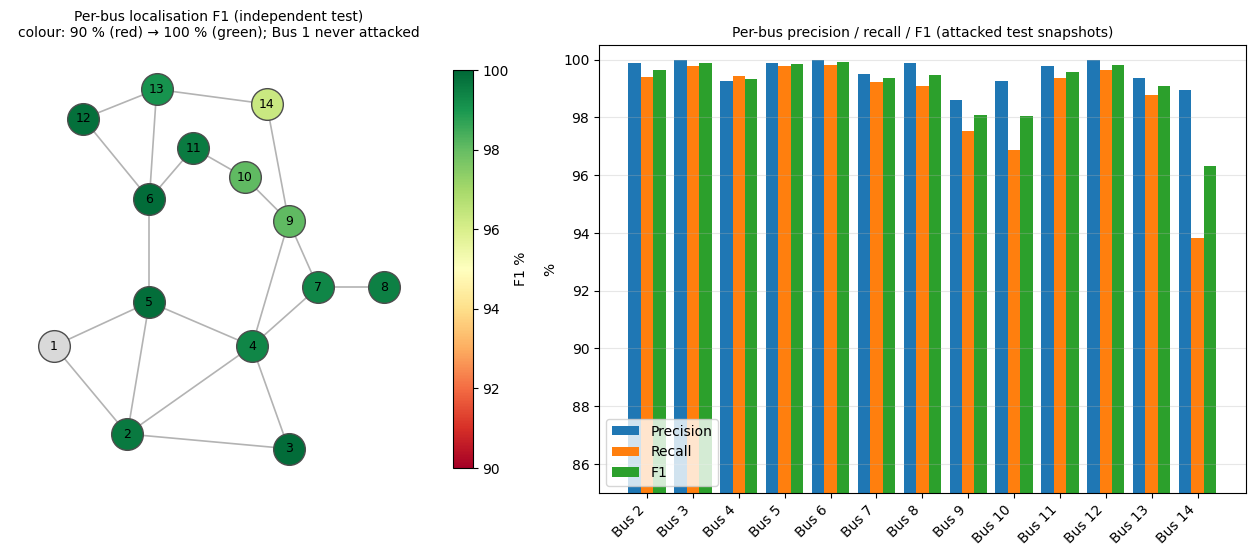

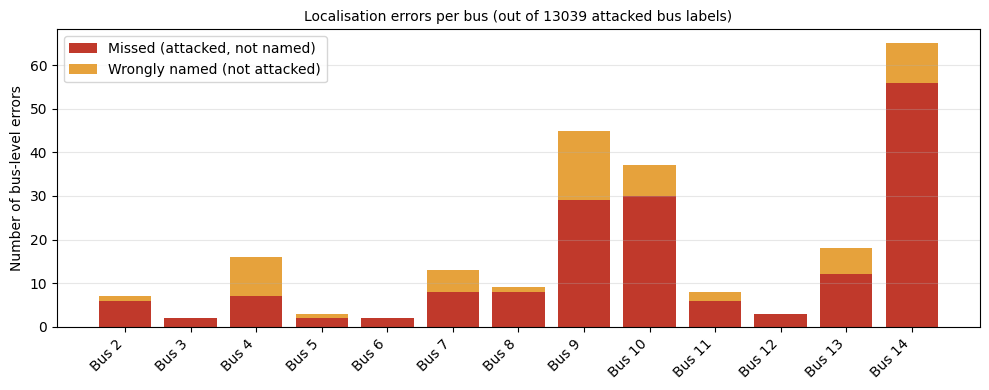

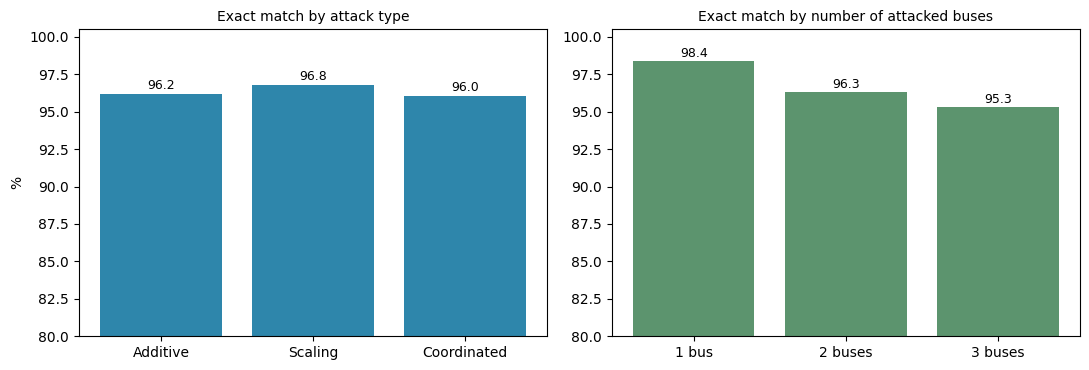

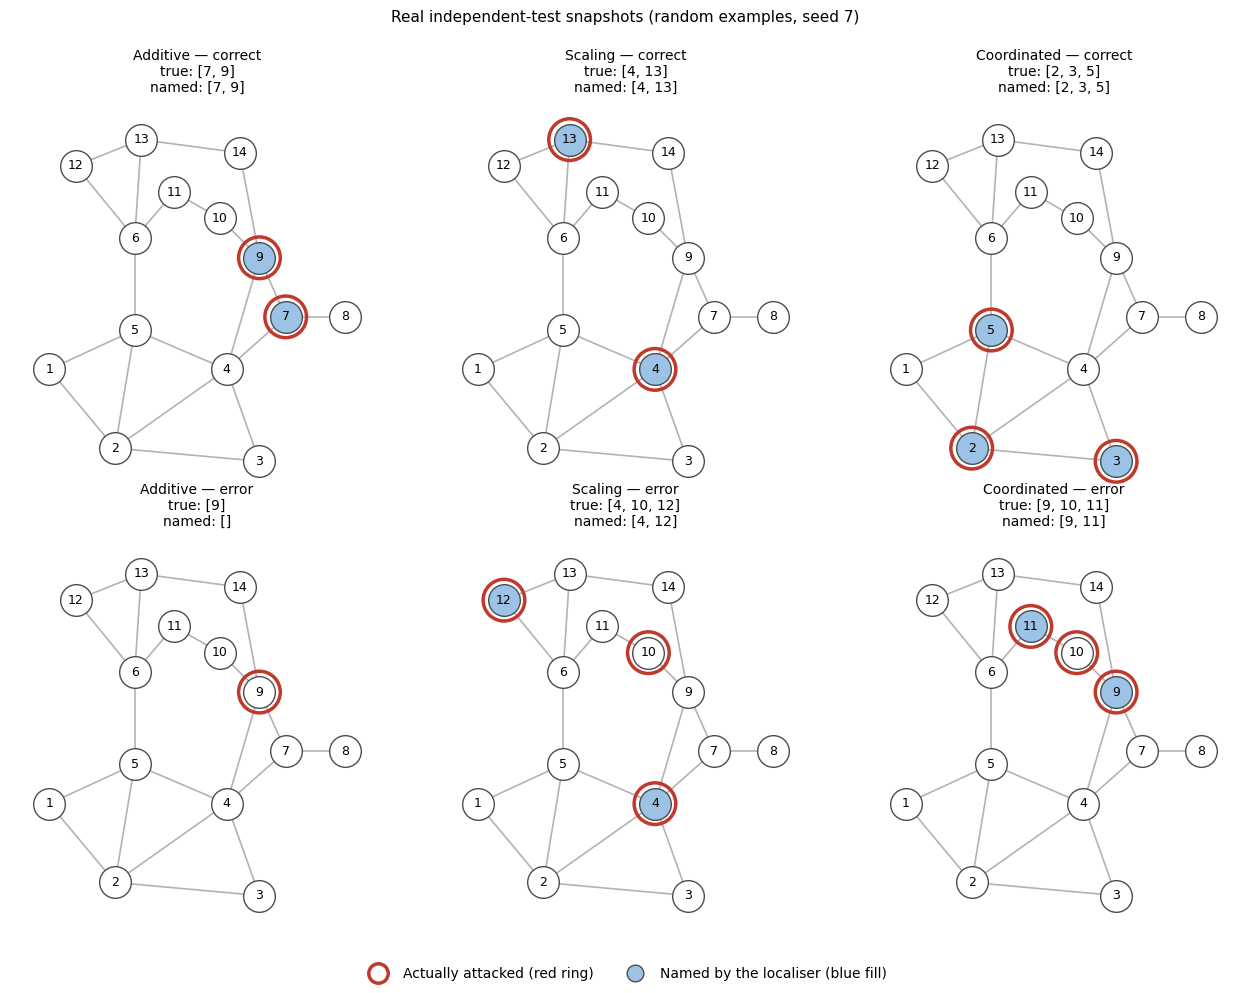

✓ Saved localisation_per_bus.png, localisation_errors_per_bus.png, localisation_by_type_and_size.png, localisation_examples.png and localisation_per_bus.csv


In [33]:
# ============================================================
# GridDefense | Localisation — visual summary (independent test set)
# ============================================================
# Pictures of how well the RF localiser names the attacked buses.
# Uses the trained localiser (rf_loc_final) at its validation threshold
# (best_th_A) on the independent test set of Section 10. Nothing is
# trained or tuned here. Bus 1 (slack) is never attacked and is greyed out.
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import precision_recall_fscore_support

# ── Independent test set (built here, so this cell only needs Section 10's data cell) ──
import os
if 'df_test_ind' not in globals():
    _csv = f'{OUT_DIR}/test_dataset_seed{TEST_SEED}.csv'          # saved by Section 10 on a previous run
    if os.path.exists(_csv):
        print(f"Loading the independent test set saved by Section 10: {_csv}")
        df_test_ind = pd.read_csv(_csv)
    else:
        raise RuntimeError("The independent test set is not in memory and no saved copy was found. "
                           "Run Section 10 ('Independent test set') once, then this cell.")
XF_v   = df_test_ind[rf_feature_cols].values
yF     = df_test_ind['Label'].astype(int).values
tF     = df_test_ind['Attack_Type'].astype(int).values
busF   = df_test_ind[bus_label_cols].values.astype(int)
TYPES  = globals().get('TYPES', [(1, 'Additive'), (2, 'Scaling'), (3, 'Coordinated')])

# ── Predictions on the independent test set ──
P_loc = get_bus_probas(rf_loc_final, add_topo_features(XF_v))
yp_loc = (P_loc >= best_th_A).astype(int)
atk_m, nor_m = (yF == 1), (yF == 0)
Cb = np.arange(1, 14)                                         # buses 2–14
pr, rc, f1, sup = precision_recall_fscore_support(busF[atk_m][:, Cb], yp_loc[atk_m][:, Cb], zero_division=0)
TP = (yp_loc[atk_m][:, Cb] & busF[atk_m][:, Cb]).sum(axis=0)
FN = ((1 - yp_loc[atk_m][:, Cb]) & busF[atk_m][:, Cb]).sum(axis=0)
FP = (yp_loc[atk_m][:, Cb] & (1 - busF[atk_m][:, Cb])).sum(axis=0)
exact = np.all(yp_loc[atk_m][:, Cb] == busF[atk_m][:, Cb], axis=1)
print(f"Independent test: {atk_m.sum()} attacked snapshots | exact match {exact.mean()*100:.2f}% | "
      f"false localisation on normals {np.mean(yp_loc[nor_m][:, Cb].any(axis=1))*100:.2f}% | threshold {best_th_A:.2f}")

# ── IEEE 14-bus drawing positions (schematic) ──
POS = {1: (0.0, 3.0), 2: (1.0, 1.8), 3: (3.2, 1.6), 4: (2.7, 3.0), 5: (1.3, 3.6), 6: (1.3, 5.0),
       7: (3.6, 3.8), 8: (4.5, 3.8), 9: (3.2, 4.7), 10: (2.6, 5.3), 11: (1.9, 5.7), 12: (0.4, 6.1),
       13: (1.4, 6.5), 14: (2.9, 6.3)}
EDGES = sorted({tuple(sorted((a, b))) for a, ns in NEIGHBORS.items() for b in ns})
cmap = plt.cm.RdYlGn

def draw_grid(ax, values=None, highlight_true=None, highlight_pred=None, title=''):
    for a, b in EDGES:
        ax.plot([POS[a][0], POS[b][0]], [POS[a][1], POS[b][1]], color='0.7', lw=1.2, zorder=1)
    for bus, (x, y) in POS.items():
        if values is not None:
            col = '0.85' if bus == 1 else cmap((values[bus - 2] - 0.9) / 0.1)   # colour scale 90–100 %
        elif highlight_pred is not None and highlight_pred[bus - 1]:
            col = '#9cc3e6'                                   # named by the localiser = blue fill
        else:
            col = 'white'
        ax.scatter(x, y, s=520, color=col, edgecolor='0.3', lw=1, zorder=2)
        if highlight_true is not None and highlight_true[bus - 1]:
            ax.scatter(x, y, s=900, facecolor='none', edgecolor='#c0392b', lw=2.5, zorder=3)
        ax.text(x, y, str(bus), ha='center', va='center', fontsize=9, zorder=5)
    ax.set_title(title, fontsize=10); ax.set_aspect('equal'); ax.axis('off')
    ax.set_xlim(-0.6, 5.1); ax.set_ylim(1.0, 7.1)

# ── Figure 1: per-bus F1 on the network + per-bus bars ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1, 1.3]})
draw_grid(axes[0], values=f1, title='Per-bus localisation F1 (independent test)\ncolour: 90 % (red) → 100 % (green); Bus 1 never attacked')
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(90, 100)); fig.colorbar(sm, ax=axes[0], fraction=0.04, label='F1 %')
x = np.arange(len(Cb)); w = 0.27
axes[1].bar(x - w, pr * 100, w, label='Precision'); axes[1].bar(x, rc * 100, w, label='Recall'); axes[1].bar(x + w, f1 * 100, w, label='F1')
axes[1].set_xticks(x); axes[1].set_xticklabels([f'Bus {b+1}' for b in Cb], rotation=45, ha='right')
axes[1].set_ylim(min(85, (np.min([pr, rc, f1]) * 100) - 2), 100.5); axes[1].set_ylabel('%')
axes[1].set_title('Per-bus precision / recall / F1 (attacked test snapshots)', fontsize=10)
axes[1].legend(loc='lower left'); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/results/localisation_per_bus.png', dpi=150); plt.show()

# ── Figure 2: where the errors are (missed vs wrongly flagged buses) ──
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x, FN, label='Missed (attacked, not named)', color='#c0392b')
ax.bar(x, FP, bottom=FN, label='Wrongly named (not attacked)', color='#e6a23c')
ax.set_xticks(x); ax.set_xticklabels([f'Bus {b+1}' for b in Cb], rotation=45, ha='right')
ax.set_ylabel('Number of bus-level errors'); ax.legend(); ax.grid(axis='y', alpha=0.3)
ax.set_title(f'Localisation errors per bus (out of {int(sup.sum())} attacked bus labels)', fontsize=10)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/results/localisation_errors_per_bus.png', dpi=150); plt.show()

# ── Figure 3: exact match by attack type and by number of attacked buses ──
n_att = busF[atk_m][:, Cb].sum(axis=1)
by_type = {nm: exact[tF[atk_m] == c].mean() * 100 for c, nm in TYPES}
by_n = {k: exact[n_att == k].mean() * 100 for k in sorted(np.unique(n_att))}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(list(by_type), list(by_type.values()), color='#2e86ab'); axes[0].set_ylim(80, 100.5)
axes[0].set_title('Exact match by attack type', fontsize=10); axes[0].set_ylabel('%')
for i, v in enumerate(by_type.values()): axes[0].text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=9)
axes[1].bar([f'{k} bus' + ('es' if k > 1 else '') for k in by_n], list(by_n.values()), color='#5c946e'); axes[1].set_ylim(80, 100.5)
axes[1].set_title('Exact match by number of attacked buses', fontsize=10)
for i, v in enumerate(by_n.values()): axes[1].text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/results/localisation_by_type_and_size.png', dpi=150); plt.show()

# ── Figure 4: six real test examples — true attacked buses vs predicted ──
rng_v = np.random.default_rng(7)
idx_att = np.where(atk_m)[0]
ok_idx  = idx_att[exact]
bad_idx = idx_att[~exact]
picks = []
for c, nm in TYPES:                                           # one correct example per attack type
    cand = ok_idx[tF[ok_idx] == c]
    if len(cand): picks.append((rng_v.choice(cand), f'{nm} — correct'))
for c, nm in TYPES:                                           # one error example per type, if any
    cand = bad_idx[tF[bad_idx] == c]
    if len(cand): picks.append((rng_v.choice(cand), f'{nm} — error'))
fig, axes = plt.subplots(2, 3, figsize=(13, 10))
for ax, (i, lab) in zip(axes.ravel(), picks[:6]):
    draw_grid(ax, highlight_true=busF[i], highlight_pred=yp_loc[i],
              title=f'{lab}\ntrue: {[int(b) + 1 for b in np.where(busF[i])[0]]}\nnamed: {[int(b) + 1 for b in np.where(yp_loc[i])[0]]}')
for ax in axes.ravel()[len(picks[:6]):]:
    ax.axis('off')
fig.legend(handles=[Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor='#c0392b', markersize=14, markeredgewidth=2.5, label='Actually attacked (red ring)'),
                    Line2D([], [], marker='o', ls='', markerfacecolor='#9cc3e6', markeredgecolor='0.3', markersize=12, label='Named by the localiser (blue fill)')],
           loc='lower center', ncol=2, frameon=False)
plt.suptitle('Real independent-test snapshots (random examples, seed 7)', fontsize=11)
plt.tight_layout(rect=[0, 0.04, 1, 0.97]); plt.savefig(f'{OUT_DIR}/results/localisation_examples.png', dpi=150); plt.show()

pd.DataFrame({'bus': Cb + 1, 'attacks': sup, 'precision': pr * 100, 'recall': rc * 100, 'f1': f1 * 100,
              'missed': FN, 'wrongly_named': FP}).to_csv(f'{OUT_DIR}/results/localisation_per_bus.csv', index=False)
print("✓ Saved localisation_per_bus.png, localisation_errors_per_bus.png, localisation_by_type_and_size.png, "
      "localisation_examples.png and localisation_per_bus.csv")

## 11 · Detecting an attack type never seen in training

Train on two attack types, test on the third. For each held-out type:
- the RF is retrained without that type;
- fusion weights and threshold are re-selected on validation data without that type;
- the AE and the physics layer are unchanged, because they learn only from normal data;
- evaluation uses the independent test set: all normal snapshots plus the held-out attack type.

In [34]:
# ============================================================
# GridDefense | Unseen attack type (train on 2, test on the 3rd)
# ============================================================
from sklearn.ensemble import RandomForestClassifier

tr_types = np.asarray(y_train_rf)
va_types = np.asarray(y_val_rf)
loao = []
for k, name in TYPES:
    print(f"Held-out type: {name} — training RF on the other two types...")
    keep = tr_types != k
    rf_k = RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_split=5,
                                  class_weight='balanced', random_state=42, n_jobs=-1)
    rf_k.fit(X_train_rf[keep], tr_types[keep])
    assert rf_k.classes_[0] == 0

    # validation WITHOUT the held-out type → AE bounds, fusion weights, threshold
    vm  = va_types != k
    v_e, v_y = val_ae_err[vm], val_true[vm]
    lo  = v_e[v_y == 0].mean() - 2 * v_e[v_y == 0].std(); hi = v_e.max()
    v_ae = np.clip((v_e - lo) / (hi - lo + 1e-9), 0, 1)
    v_rf = 1 - rf_k.predict_proba(X_val_rf[vm])[:, 0]
    v_ph = val_phys_score[vm]
    _, (wa, wr, wp), thr = select_fusion([v_ae, v_rf, v_ph], v_y)

    # independent test set: normal + held-out type only
    tm   = (tF == 0) | (tF == k)
    y    = yF[tm]
    rf_f = (rf_k.predict(XF[tm]) != 0).astype(int)
    rf_s = 1 - rf_k.predict_proba(XF[tm])[:, 0]
    ae_s = np.clip((errF[tm] - lo) / (hi - lo + 1e-9), 0, 1)
    fus  = ((wa * ae_s + wr * rf_s + wp * ph_sF[tm]) >= thr).astype(int)
    vote = ((ae_fF[tm] + rf_f + ph_fF[tm]) >= 2).astype(int)
    for det_name, pred, seen in [('AE alone', ae_fF[tm], summary['AE alone']),
                                 ('RF alone', rf_f, summary['RF alone']),
                                 ('Physics alone', ph_fF[tm], summary['Physics alone']),
                                 ('2-of-3 voting', vote, summary['2-of-3 voting']),
                                 ('Weighted fusion', fus, summary['Weighted fusion'])]:
        loao.append(dict(held_out=name, detector=det_name,
                         unseen_detection=pred[y == 1].mean() * 100,
                         false_alarm=pred[y == 0].mean() * 100,
                         seen_detection=seen['per_class_recall'][name],
                         fusion_weights=f'(AE {wa:.1f} / RF {wr:.1f} / Ph {wp:.1f}, thr {thr:.2f})' if det_name == 'Weighted fusion' else ''))

loao_df = pd.DataFrame(loao)
print("\nDetection of an attack type NOT seen in training (independent test set)")
print("  'seen' = same detector trained with all three types (Section 10)")
for name in [n for _, n in TYPES]:
    print(f"\n  Held-out: {name}")
    print(f"  {'Detector':<18}{'Unseen det %':>14}{'Seen det %':>12}{'False alarm %':>15}")
    for r in loao_df[loao_df.held_out == name].itertuples():
        print(f"  {r.detector:<18}{r.unseen_detection:>14.2f}{r.seen_detection:>12.2f}{r.false_alarm:>15.2f}"
              f"   {r.fusion_weights}")
loao_df.to_csv(f'{OUT_DIR}/results/unseen_attack_type.csv', index=False)
print(f"\n✓ Saved results/unseen_attack_type.csv")

Held-out type: Additive — training RF on the other two types...
Held-out type: Scaling — training RF on the other two types...
Held-out type: Coordinated — training RF on the other two types...

Detection of an attack type NOT seen in training (independent test set)
  'seen' = same detector trained with all three types (Section 10)

  Held-out: Additive
  Detector            Unseen det %  Seen det %  False alarm %
  AE alone                   99.15       99.15           3.66   
  RF alone                   99.00       99.25           0.54   
  Physics alone              99.15       99.15           1.70   
  2-of-3 voting              99.25       99.30           0.40   
  Weighted fusion            99.15       99.10           0.38   (AE 0.3 / RF 0.5 / Ph 0.2, thr 0.40)

  Held-out: Scaling
  Detector            Unseen det %  Seen det %  False alarm %
  AE alone                   99.05       99.05           3.66   
  RF alone                   98.45       99.05           0.34   
  Physic

## 12 · Attack-size sensitivity

The trained system, with nothing retrained or tuned, is tested on new attacks from 0.25% to 3% of the true measurement.


── Attack size 0.25%  (angle bias 0.042°, seed 30000) ──
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30000
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
  ✓ 500
Coordinated (500 samples)...
  ✓ 500

  Processing 1500 samples...

── Attack size 0.50%  (angle bias 0.083°, seed 30001) ──
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30001
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
  ✓ 500
Coordinated (500 samples)...
  ✓ 500

  Processing 1500 samples...

── Attack size 0.75%  (angle bias 0.125°, seed 30002) ──
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30002
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
 

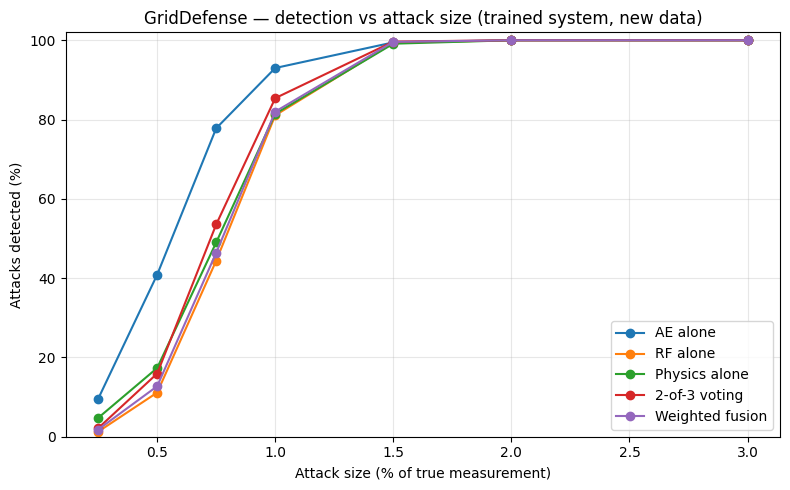

✓ Saved results/attack_size_sensitivity.csv and .png


In [35]:
# ============================================================
# GridDefense | Attack-size sensitivity (trained system, no retraining)
# ============================================================
# How small can an attack be before the system misses it?
# The trained system from the sections above (AE, RF, physics layer,
# fusion — all thresholds and weights unchanged) is run on NEW data in
# which every attack has one fixed size. Nothing is trained or tuned
# here. Each size uses its own new seed (30000, 30001, ...), never used
# anywhere else. The angle bias keeps the same proportion to the attack
# size as in the main experiment (0.5° at 3%).
# Normal snapshots are not affected by attack size, so false-alarm
# rates are the ones reported in Section 10.
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SWEEP_SIZES = [0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03]   # attack size (fraction of true value)
SWEEP_N     = 500        # attacked snapshots per attack type, per size (1,500 per size)
SWEEP_SEED0 = 30000      # seeds 30000, 30001, ... — used only in this section

_saved = (ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG)
_va_per_unit = VA_ATTACK_MAX_DEG / ATTACK_MAX     # degrees of angle bias per unit of attack size

def run_trained_system(df):
    """Apply the trained detectors, unchanged, to a dataset. Returns 0/1 flags per detector."""
    xs   = scaler_ae.transform(df[ae_feature_cols].values)
    err  = np.mean(np.square(xs - autoencoder.predict(xs, verbose=0)), axis=1)
    ae_f = (err > AE_THRESHOLD).astype(int)
    ae_s = np.clip((err - FUSION['ae_lo']) / (FUSION['ae_hi'] - FUSION['ae_lo'] + 1e-9), 0, 1)
    X    = df[rf_feature_cols].values
    rf_f = (rf_model.predict(X) != 0).astype(int)
    rf_s = 1 - rf_model.predict_proba(X)[:, 0]
    P, Q, QK, VAd, VMd, SL = compute_physics(df)
    v    = score_samples(P, Q, VAd, VMd, SL, Z_FINAL)
    ph_f = (v >= SCORE_FINAL).any(axis=1).astype(int)
    ph_s = v.max(axis=1) / N_CHECKS
    fus  = FUSION['w_ae'] * ae_s + FUSION['w_rf'] * rf_s + FUSION['w_phys'] * ph_s
    return {'AE alone': ae_f, 'RF alone': rf_f, 'Physics alone': ph_f,
            '2-of-3 voting': ((ae_f + rf_f + ph_f) >= 2).astype(int),
            'Weighted fusion': (fus >= FUSION['threshold']).astype(int)}

sweep_rows = []
try:
    for k, m in enumerate(SWEEP_SIZES):
        ATTACK_MIN = ATTACK_MAX = m
        VA_ATTACK_MAX_DEG = _va_per_unit * m
        print(f"\n── Attack size {m*100:.2f}%  (angle bias {VA_ATTACK_MAX_DEG:.3f}°, seed {SWEEP_SEED0 + k}) ──")
        _, df_sw = generate_dataset(SWEEP_SEED0 + k, n_normal=1, n_attack=SWEEP_N)
        df_sw = add_physics_features(df_sw)
        t_sw  = df_sw['Attack_Type'].astype(int).values
        for name, p in run_trained_system(df_sw).items():
            lo, hi = wilson(int(p.sum()), len(p))
            sweep_rows.append(dict(size_pct=m * 100, size_vs_vm_noise=m / VM_NOISE_STD, detector=name,
                                   detection=p.mean() * 100, ci_low=lo, ci_high=hi,
                                   **{nm: p[t_sw == c].mean() * 100 for c, nm in TYPES}))
finally:
    ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG = _saved   # restore the experiment settings

sweep = pd.DataFrame(sweep_rows)
DET_ORDER = ['AE alone', 'RF alone', 'Physics alone', '2-of-3 voting', 'Weighted fusion']

print("\n" + "=" * 92)
print("DETECTION (%) vs ATTACK SIZE — trained system, new data, nothing retrained or tuned")
print("=" * 92)
tbl = sweep.pivot(index='size_pct', columns='detector', values='detection')[DET_ORDER]
tbl.index = [f"{s:.2f}%  (≈{s / 100 / VM_NOISE_STD:.1f}× Vm noise σ)" for s in tbl.index]
print(tbl.round(2).to_string())
print("\nFalse alarms (normal data, Section 10): " +
      ", ".join(f"{d} {summary[d]['false_alarm']:.2f}%" for d in DET_ORDER))

print("\nWeighted fusion — detection (%) by attack type")
print(sweep[sweep.detector == 'Weighted fusion'].set_index('size_pct')[[nm for _, nm in TYPES]].round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for d in DET_ORDER:
    s = sweep[sweep.detector == d]
    ax.plot(s.size_pct, s.detection, marker='o', label=d)
ax.set_xlabel('Attack size (% of true measurement)')
ax.set_ylabel('Attacks detected (%)')
ax.set_title('GridDefense — detection vs attack size (trained system, new data)')
ax.set_ylim(0, 102); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/results/attack_size_sensitivity.png', dpi=150)
plt.show()

sweep.to_csv(f'{OUT_DIR}/results/attack_size_sensitivity.csv', index=False)
print(f"✓ Saved results/attack_size_sensitivity.csv and .png")

## 13 · Physics ablation

What physics adds to GridDefense, measured two ways: as RF input features and as the separate physics voting layer.
- 13a: setup and preliminary comparison
- 13b: comparison at the same false-alarm budget
- 13c: localisation and repeatability across seeds
- 13d: integrity checks on the numbers in 13a–13c

In [36]:
# ============================================================
# GridDefense | 13a Physics ablation — setup and preliminary comparison
# ============================================================
# Physics enters GridDefense in two ways:
#   (a) physics-derived FEATURES in the RF and the localiser
#       (P_res, Q_res, LineFlow — 48 of the 104 features)
#   (b) the physics VOTING LAYER (per-bus checks) used in fusion/voting
# This cell builds the variants that remove (a), (b) or both, exactly
# like the full system: models fitted on the TRAINING split, fusion
# weights / thresholds / localisation threshold chosen on VALIDATION
# data with one common search. Nothing is tuned on test data.
# The table below compares each variant at its OWN best-F1 threshold
# (preliminary: thresholds differ between variants). The fair
# comparison at the SAME false-alarm budget is in 13b.
# Evaluation: independent test set (Section 10) + the 0.75 % and 1 %
# attack-size sets of Section 12 (regenerated with the same seeds).
# ============================================================
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score

PHYS_FEATS = [c for c in rf_feature_cols if c.startswith(('P_res', 'Q_res', 'LineFlow'))]
RAW_FEATS  = [c for c in rf_feature_cols if c not in PHYS_FEATS]
raw_idx    = [rf_feature_cols.index(c) for c in RAW_FEATS]
print(f"Physics-derived features removed in 'no physics features' variants: {len(PHYS_FEATS)}  "
      f"(RF keeps {len(RAW_FEATS)} raw measurements)")

y_tr_type = np.asarray(y_train_rf).astype(int)
y_va_type = np.asarray(y_val_rf).astype(int)
y_va_bin  = (y_va_type != 0).astype(int)

# ── RF without physics features (same settings as Section 6) ──
print("Training RF on raw features only (training split)...")
rf_raw = RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_split=5,
                                class_weight='balanced', oob_score=True, random_state=42, n_jobs=-1)
rf_raw.fit(X_train_rf[:, raw_idx], y_tr_type)
assert list(rf_raw.classes_) == [0, 1, 2, 3]
val_rf_raw = 1 - rf_raw.predict_proba(X_val_rf[:, raw_idx])[:, 0]

# ── Localiser without physics features (same settings + threshold rule as Section 7) ──
topo_cols = list(range(104, 172))                       # the 68 topology features (built from Vm / Va only)
loc_raw_cols = raw_idx + topo_cols
print("Training localiser on raw + topology features only (training split)...")
Xtr_loc = add_topo_features(X_train_rf)[:, loc_raw_cols]
Xva_loc = add_topo_features(X_val_rf)[:, loc_raw_cols]
loc_raw = MultiOutputClassifier(RandomForestClassifier(n_estimators=200, random_state=42,
                                class_weight='balanced', min_samples_split=5, n_jobs=-1), n_jobs=1)
loc_raw.fit(Xtr_loc, np.asarray(y_train_loc, dtype=int))

def pick_loc_threshold(probas, y_bus, is_attack):
    """Section 7 rule: highest validation exact match with ≤5 % false localisation on normals."""
    best = (-1.0, None)
    for ti in range(20, 71):
        th = ti / 100.0
        yp = (probas >= th).astype(int)
        if np.mean(np.any(yp[~is_attack] == 1, axis=1)) > 0.05:
            continue
        ex = np.mean(np.all(yp[is_attack] == y_bus[is_attack], axis=1))
        if ex > best[0]:
            best = (ex, th)
    return best[1]

th_raw = pick_loc_threshold(get_bus_probas(loc_raw, Xva_loc), np.asarray(y_val_loc, dtype=int), y_va_bin == 1)
print(f"  localiser threshold (validation): full {best_th_A:.2f} | no physics features {th_raw:.2f}")

# ── Fusion weights for each variant, chosen on VALIDATION with ONE common search ──
# Every variant gets the same search: weights in steps of 0.1 (zero allowed)
# that sum to 1, threshold 0.20–0.75, best validation F1. Using one search
# for all variants means differences come from the inputs, not the search.
# (The main system in Section 8 used a narrower grid; it is shown for reference.)
def select_common(scores, y):
    k = len(scores)
    grid = [np.array(w) / 10 for w in np.ndindex(*([11] * k)) if sum(w) == 10]
    best = (-1, None, None)
    for w in grid:
        f = sum(wi * s for wi, s in zip(w, scores))
        for thr in np.arange(0.2, 0.8, 0.05):
            f1 = _f1_det_fpr((f >= thr).astype(int), y)[0]
            if f1 > best[0]:
                best = (f1, w, thr)
    return best

FUS = {'main': ((FUSION['w_ae'], FUSION['w_rf'], FUSION['w_phys']), FUSION['threshold'])}
_, w, t = select_common([val_ae_score, val_rf_score, val_phys_score], val_true); FUS['full']        = (tuple(w), t)
_, w, t = select_common([val_ae_score, val_rf_score], val_true);                 FUS['no_layer']    = ((w[0], w[1], 0.0), t)
_, w, t = select_common([val_ae_score, val_rf_raw, val_phys_score], val_true);   FUS['no_features'] = (tuple(w), t)
_, w, t = select_common([val_ae_score, val_rf_raw], val_true);                   FUS['no_physics']  = ((w[0], w[1], 0.0), t)

VARIANTS = [  # key, label, RF uses physics features?, uses physics voting layer?
    ('full',        'Full system (AE + RF + physics)',          True,  True),
    ('main',        'Reference: main system (Section 8 fusion)', True, True),
    ('no_layer',    'No physics voting layer',                  True,  False),
    ('no_features', 'No physics features (RF/localiser raw)',   False, True),
    ('no_physics',  'No physics at all',                        False, False)]

def run_variants(df, need_loc=False):
    """Detection (and optionally localisation) for every variant on one dataset."""
    xs  = scaler_ae.transform(df[ae_feature_cols].values)
    err = np.mean(np.square(xs - autoencoder.predict(xs, verbose=0)), axis=1)
    ae_s = np.clip((err - FUSION['ae_lo']) / (FUSION['ae_hi'] - FUSION['ae_lo'] + 1e-9), 0, 1)
    ae_f = (err > AE_THRESHOLD).astype(int)
    X = df[rf_feature_cols].values
    rf_s = {True: 1 - rf_model.predict_proba(X)[:, 0], False: 1 - rf_raw.predict_proba(X[:, raw_idx])[:, 0]}
    rf_f = {True: (rf_model.predict(X) != 0).astype(int), False: (rf_raw.predict(X[:, raw_idx]) != 0).astype(int)}
    P, Q, QK, VAd, VMd, SL = compute_physics(df)
    v = score_samples(P, Q, VAd, VMd, SL, Z_FINAL)
    ph_s, ph_f = v.max(axis=1) / N_CHECKS, (v >= SCORE_FINAL).any(axis=1).astype(int)
    out = {}
    for key, _, feats, layer in VARIANTS:
        (wa, wr, wp), thr = FUS[key]
        fus = ((wa * ae_s + wr * rf_s[feats] + (wp * ph_s if layer else 0)) >= thr).astype(int)
        vote = ((ae_f + rf_f[feats] + ph_f) >= 2).astype(int) if layer else None
        out[key] = {'fusion': fus, 'vote': vote, 'rf': rf_f[feats]}
    if need_loc:
        Xt = add_topo_features(X)
        out['full']['loc']        = (get_bus_probas(rf_loc_final, Xt) >= best_th_A).astype(int)
        out['no_layer']['loc']    = out['full']['loc']
        out['main']['loc']        = out['full']['loc']
        lr = (get_bus_probas(loc_raw, Xt[:, loc_raw_cols]) >= th_raw).astype(int)
        out['no_features']['loc'] = lr
        out['no_physics']['loc']  = lr
    return out

# ── Data: independent test set + small-attack sets (same seeds as Section 12) ──
print("\nRunning variants on the independent test set...")
R_test = run_variants(df_test_ind, need_loc=True)
small = {}
_saved = (ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG)
_va_per_unit = VA_ATTACK_MAX_DEG / ATTACK_MAX
try:
    for k, m in [(2, 0.0075), (3, 0.01)]:                    # seeds 30002 / 30003 = Section 12 sets
        ATTACK_MIN = ATTACK_MAX = m
        VA_ATTACK_MAX_DEG = _va_per_unit * m
        print(f"Regenerating the {m*100:.2f}% attack set (seed {SWEEP_SEED0 + k})...")
        _, d = generate_dataset(SWEEP_SEED0 + k, n_normal=1, n_attack=SWEEP_N)
        d = add_physics_features(d)
        assert (d['Label'] == 1).all()
        small[m] = run_variants(d)
finally:
    ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG = _saved

# ── Metrics ──
y, C = yF, np.arange(1, 14)
atk, nor = (y == 1), (y == 0)
def e2e_exact_rows(det, loc):
    p = loc.copy(); p[(y == 1) & (det == 0)] = 0           # attacks missed by detection → nothing localised
    return np.all(p[atk][:, C] == busF[atk][:, C], axis=1).astype(float)

rows = []
for key, label, _, _ in VARIANTS:
    d = R_test[key]['fusion']
    tp, fp = int(d[atk].sum()), int(d[nor].sum())
    prec = tp / (tp + fp) if tp + fp else 0; rec = tp / atk.sum()
    rows.append({'Variant': label,
                 'Recall %': rec * 100, 'False alarm %': fp / nor.sum() * 100,
                 'F1': 2 * prec * rec / (prec + rec) if prec + rec else 0,
                 'Recall @1% %': small[0.01][key]['fusion'].mean() * 100,
                 'Recall @0.75% %': small[0.0075][key]['fusion'].mean() * 100,
                 'Loc exact %': np.mean(np.all(R_test[key]['loc'][atk][:, C] == busF[atk][:, C], axis=1)) * 100,
                 'End-to-end exact %': e2e_exact_rows(d, R_test[key]['loc']).mean() * 100})
tab = pd.DataFrame(rows).set_index('Variant')
print("\n" + "=" * 110)
print("PRELIMINARY — each variant at its own best-F1 threshold (see 13b for the same-budget comparison)")
print("=" * 110)
print(tab.round({c: (4 if c == 'F1' else 2) for c in tab.columns}).to_string())

# ── Paired bootstrap: difference vs the full system ──
rng_b = np.random.default_rng(0)
B = 1000
ia = rng_b.integers(0, atk.sum(), (B, atk.sum())); inn = rng_b.integers(0, nor.sum(), (B, nor.sum()))
def boot_diff(a, b, idx):
    d = a[idx].mean(axis=1) - b[idx].mean(axis=1)
    return (a.mean() - b.mean()) * 100, np.percentile(d, 2.5) * 100, np.percentile(d, 97.5) * 100

full = R_test['full']
e2e_full = e2e_exact_rows(full['fusion'], full['loc'])
drows = []
for key, label, _, _ in [v for v in VARIANTS if v[0] not in ('full', 'main')]:
    v = R_test[key]
    for metric, a, b, idx in [
        ('Recall (test)',            v['fusion'][atk].astype(float), full['fusion'][atk].astype(float), ia),
        ('False alarm (test)',       v['fusion'][nor].astype(float), full['fusion'][nor].astype(float), inn),
        ('End-to-end exact (test)',  e2e_exact_rows(v['fusion'], v['loc']), e2e_full, ia)]:
        dv, lo, hi = boot_diff(a, b, idx)
        drows.append((label, metric, dv, lo, hi))
    for m in [0.01, 0.0075]:
        a = small[m][key]['fusion'].astype(float); b = small[m]['full']['fusion'].astype(float)
        idx = rng_b.integers(0, len(a), (B, len(a)))
        dv, lo, hi = boot_diff(a, b, idx)
        drows.append((label, f'Recall ({m*100:.2f}% attacks)', dv, lo, hi))

print("\nDIFFERENCE vs FULL SYSTEM (same fusion search for all; percentage points, 95% paired-bootstrap CI)")
print("  positive = variant is higher than the full system; * = 95% paired-bootstrap CI excludes zero")
print(f"  {'Variant':<42}{'Metric':<28}{'Δ pp':>8}   {'95% CI':>18}")
for label, metric, dv, lo, hi in drows:
    flag = '' if lo <= 0 <= hi else '  *'
    print(f"  {label:<42}{metric:<28}{dv:>8.2f}   [{lo:6.2f}, {hi:6.2f}]{flag}")
print("  * = 95% paired-bootstrap CI excludes zero")

# ── Voting layer: 2-of-3 (with physics) vs AE+RF rules without physics ──
ae_t, rf_t, ph_t = ae_fF, rf_fF, ph_fF
print("\nVOTING RULES (independent test set)")
print(f"  {'Rule':<34}{'Recall %':>10}{'False alarm %':>15}")
for nm, p in [('2-of-3 (AE, RF, physics)', vote_fF),
              ('AE AND RF (no physics)', ae_t & rf_t),
              ('AE OR RF (no physics)', ae_t | rf_t)]:
    print(f"  {nm:<34}{p[atk].mean()*100:>10.2f}{p[nor].mean()*100:>15.2f}")

print("\nFusion weights / thresholds per variant (chosen on validation):")
for key, label, _, _ in VARIANTS:
    (wa, wr, wp), thr = FUS[key]
    print(f"  {label:<42} AE {wa:.1f} / RF {wr:.1f} / Physics {wp:.1f}, threshold {thr:.2f}")

tab.to_csv(f'{OUT_DIR}/results/physics_ablation.csv')
pd.DataFrame(drows, columns=['variant', 'metric', 'delta_pp', 'ci_low', 'ci_high']).to_csv(
    f'{OUT_DIR}/results/physics_ablation_differences.csv', index=False)
print("\n✓ Saved results/physics_ablation.csv and physics_ablation_differences.csv")

Physics-derived features removed in 'no physics features' variants: 48  (RF keeps 56 raw measurements)
Training RF on raw features only (training split)...
Training localiser on raw + topology features only (training split)...
  localiser threshold (validation): full 0.31 | no physics features 0.28

Running variants on the independent test set...
Regenerating the 0.75% attack set (seed 30002)...
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30002
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
  ✓ 500
Coordinated (500 samples)...
  ✓ 500

  Processing 1500 samples...
Regenerating the 1.00% attack set (seed 30003)...
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30003
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
  ✓ 500
Coordinated (500 s

In [37]:
# ============================================================
# GridDefense | 13b Physics ablation — same false-alarm budget,
#               fixed vs re-optimised weights, classification,
#               physics-only localisation
# ============================================================
# Question: is the small-attack "cost" of physics real, or only a more
# cautious threshold? Every configuration below gets its threshold set
# on VALIDATION normals so that it raises the SAME share of false
# alarms (0.5 % and 1 %). Then recall is compared at equal false-alarm
# budgets. Two families of variants:
#   fixed       — remove a component, keep the full system's remaining
#                 weights (renormalised); only the threshold is reset
#   re-optimised — weights chosen by the common validation search (13a)
# Nothing is fitted or tuned on test data. Uses the objects from
# Sections 10, 12 and 13a.
# ============================================================
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, recall_score

TARGET_FPR = [0.005, 0.01]          # false-alarm budgets, set on validation normals

# ── Scores (continuous) for every component ──
def component_scores(df):
    xs  = scaler_ae.transform(df[ae_feature_cols].values)
    err = np.mean(np.square(xs - autoencoder.predict(xs, verbose=0)), axis=1)
    X   = df[rf_feature_cols].values
    P, Q, QK, VAd, VMd, SL = compute_physics(df)
    v = score_samples(P, Q, VAd, VMd, SL, Z_FINAL)
    return {'ae': np.clip((err - FUSION['ae_lo']) / (FUSION['ae_hi'] - FUSION['ae_lo'] + 1e-9), 0, 1),
            'rf': 1 - rf_model.predict_proba(X)[:, 0],
            'rf_raw': 1 - rf_raw.predict_proba(X[:, raw_idx])[:, 0],
            'ph': v.max(axis=1) / N_CHECKS}

VAL  = {'ae': val_ae_score, 'rf': val_rf_score, 'rf_raw': val_rf_raw, 'ph': val_phys_score}
TEST = {'ae': ae_sF, 'rf': rf_sF, 'rf_raw': 1 - rf_raw.predict_proba(XF[:, raw_idx])[:, 0], 'ph': ph_sF}
SMALL = {}
_saved = (ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG)
_va_per_unit = VA_ATTACK_MAX_DEG / ATTACK_MAX
try:
    for k, m in [(2, 0.0075), (3, 0.01)]:                    # same sets as Sections 12 / 13
        ATTACK_MIN = ATTACK_MAX = m
        VA_ATTACK_MAX_DEG = _va_per_unit * m
        print(f"Regenerating the {m*100:.2f}% attack set (seed {SWEEP_SEED0 + k})...")
        _, d = generate_dataset(SWEEP_SEED0 + k, n_normal=1, n_attack=SWEEP_N)
        d = add_physics_features(d)
        assert (d['Label'] == 1).all()
        SMALL[m] = component_scores(d)
finally:
    ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG = _saved

# ── Configurations ──
(wa, wr, wp), _ = FUS['full']
def renorm(d):
    s = sum(d.values());  return {k: v / s for k, v in d.items()} if s > 0 else d
def opt(key, names):
    (a, b, c), _ = FUS[key];  return {n: w for n, w in zip(names, (a, b, c)) if w > 0} or {names[1]: 1.0}

CONFIGS = [
    ('Full system',                         'full',      {'ae': wa, 'rf': wr, 'ph': wp}),
    ('No physics layer (fixed weights)',    'fixed',     renorm({'ae': wa, 'rf': wr})),
    ('No physics features (fixed weights)', 'fixed',     {'ae': wa, 'rf_raw': wr, 'ph': wp}),
    ('No physics at all (fixed weights)',   'fixed',     renorm({'ae': wa, 'rf_raw': wr})),
    ('No physics layer (re-optimised)',     'optimised', opt('no_layer',    ['ae', 'rf', 'ph'])),
    ('No physics features (re-optimised)',  'optimised', opt('no_features', ['ae', 'rf_raw', 'ph'])),
    ('No physics at all (re-optimised)',    'optimised', opt('no_physics',  ['ae', 'rf_raw', 'ph'])),
    ('AE alone',                            'single',    {'ae': 1.0}),
    ('RF alone (104 features)',             'single',    {'rf': 1.0}),
    ('RF alone (56 raw features)',          'single',    {'rf_raw': 1.0}),
    ('Physics alone',                       'single',    {'ph': 1.0})]

def fused(D, w):
    return sum(v * D[k] for k, v in w.items())

def thr_at_fpr(s_norm, target):
    """Lowest threshold whose validation false-alarm rate is ≤ target."""
    for t in np.unique(s_norm):
        if np.mean(s_norm >= t) <= target:
            return t
    return s_norm.max() + 1e-9

atkT, norT = (yF == 1), (yF == 0)
v_norm = (val_true == 0)
results, DEC = [], {}
for target in TARGET_FPR:
    for name, fam, w in CONFIGS:
        t  = thr_at_fpr(fused(VAL, w)[v_norm], target)
        pT = (fused(TEST, w) >= t).astype(int)
        tp, fn = int(pT[atkT].sum()), int((1 - pT[atkT]).sum())
        fp, tn = int(pT[norT].sum()), int((1 - pT[norT]).sum())
        prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn)
        row = dict(target_fpr=target * 100, config=name, family=fam,
                   val_fpr=np.mean(fused(VAL, w)[v_norm] >= t) * 100,
                   recall=rec * 100, recall_ci=wilson(tp, tp + fn),
                   fpr=fp / (fp + tn) * 100, fpr_ci=wilson(fp, fp + tn),
                   precision=prec * 100, f1=(2 * prec * rec / (prec + rec) if prec + rec else 0.0),
                   TN=tn, FP=fp, FN=fn, TP=tp)
        DEC[(target, name)] = {'test': pT}
        for m, tag in [(0.01, 'r100'), (0.0075, 'r075')]:
            pS = (fused(SMALL[m], w) >= t).astype(int)
            row[tag] = pS.mean() * 100
            row[tag + '_ci'] = wilson(int(pS.sum()), len(pS))
            DEC[(target, name)][m] = pS
        results.append(row)
res = pd.DataFrame(results)

fmt_ci = lambda c: f"[{c[0]:5.1f},{c[1]:5.1f}]"
for target in TARGET_FPR:
    print("\n" + "=" * 128)
    print(f"SAME FALSE-ALARM BUDGET — every threshold set on validation normals for ≤{target*100:.1f}% false alarms")
    print("=" * 128)
    print(f"  {'Configuration':<38}{'val FA':>7}{'Test recall [95% CI]':>23}{'Test FA [95% CI]':>21}"
          f"{'F1':>8}{'@1% [95% CI]':>21}{'@0.75% [95% CI]':>21}")
    for r in res[res.target_fpr == target * 100].itertuples():
        print(f"  {r.config:<38}{r.val_fpr:>6.2f}%{r.recall:>8.2f} {fmt_ci(r.recall_ci)}{r.fpr:>7.2f} {fmt_ci(r.fpr_ci)}"
              f"{r.f1:>8.4f}{r.r100:>7.1f} {fmt_ci(r.r100_ci)}{r.r075:>7.1f} {fmt_ci(r.r075_ci)}")
    print(f"\n  Confusion (independent test)  TN / FP / FN / TP")
    for r in res[res.target_fpr == target * 100].itertuples():
        print(f"  {r.config:<38}{r.TN:>6} / {r.FP:>4} / {r.FN:>4} / {r.TP:>5}")

# ── Paired-bootstrap differences vs the full system, at the same false-alarm budget ──
rng_c = np.random.default_rng(1)
B = 1000
idx_a = rng_c.integers(0, atkT.sum(), (B, atkT.sum()))
idx_n = rng_c.integers(0, norT.sum(), (B, norT.sum()))
idx_s = {m: rng_c.integers(0, len(SMALL[m]['ae']), (B, len(SMALL[m]['ae']))) for m in [0.01, 0.0075]}
def bdiff(a, b, idx):
    a, b = a.astype(float), b.astype(float)
    d = a[idx].mean(axis=1) - b[idx].mean(axis=1)
    return (a.mean() - b.mean()) * 100, np.percentile(d, 2.5) * 100, np.percentile(d, 97.5) * 100

print("\nDIFFERENCE vs FULL SYSTEM at the same false-alarm budget (percentage points)")
print("  positive = configuration is higher; '*' = 95% paired-bootstrap CI excludes zero")
print(f"  {'Budget':<8}{'Configuration':<38}{'Δ recall test':>22}{'Δ FA test':>22}{'Δ recall @1%':>22}{'Δ recall @0.75%':>22}")
for target in TARGET_FPR:
    F = DEC[(target, 'Full system')]
    for name, fam, _ in CONFIGS[1:7]:
        D = DEC[(target, name)]
        cells = []
        for a, b, idx in [(D['test'][atkT], F['test'][atkT], idx_a), (D['test'][norT], F['test'][norT], idx_n),
                          (D[0.01], F[0.01], idx_s[0.01]), (D[0.0075], F[0.0075], idx_s[0.0075])]:
            dv, lo, hi = bdiff(a, b, idx)
            cells.append(f"{dv:+6.2f} [{lo:+5.1f},{hi:+5.1f}]{'*' if not (lo <= 0 <= hi) else ' '}")
        print(f"  {target*100:>4.1f}%   {name:<38}" + ''.join(f"{c:>22}" for c in cells))

# ── Attack-type classification: RF with vs without physics features ──
print("\nATTACK-TYPE CLASSIFICATION (independent test set) — per-class recall %")
print(f"  {'Model':<28}{'Normal':>8}{'Additive':>10}{'Scaling':>9}{'Coordinated':>13}{'Macro F1':>10}")
for nm, pred in [('RF (104 features)', rf_clsF), ('RF (56 raw, no physics)', rf_raw.predict(XF[:, raw_idx]))]:
    rc = recall_score(tF, pred, labels=[0, 1, 2, 3], average=None) * 100
    print(f"  {nm:<28}{rc[0]:>8.2f}{rc[1]:>10.2f}{rc[2]:>9.2f}{rc[3]:>13.2f}{f1_score(tF, pred, average='macro'):>10.4f}")

# ── Physics-only localisation baseline (per-bus votes) ──
# A bus is reported as attacked if its physics vote count reaches k; k is chosen
# on validation with the Section 7 rule (best exact match, ≤5 % false localisation).
# Evaluated on buses 2–14.
yv_bus = np.asarray(y_val_loc, dtype=int); v_att = (np.asarray(y_val_rf) != 0)
Cb = np.arange(1, 14)
best_k = None; best_ex = -1
for k in range(1, N_CHECKS + 1):
    yp = (sc_val >= k).astype(int)
    if np.mean(np.any(yp[~v_att][:, Cb] == 1, axis=1)) > 0.05:
        continue
    ex = np.mean(np.all(yp[v_att][:, Cb] == yv_bus[v_att][:, Cb], axis=1))
    if ex > best_ex:
        best_ex, best_k = ex, k
print("\nLOCALISATION — physics-only baseline vs RF localiser (independent test set, buses 2–14)")
if best_k is None:
    print("  Physics-only: no vote level met the ≤5% validation false-localisation limit")
else:
    ypP = (votesF >= best_k).astype(int)
    exP = np.mean(np.all(ypP[atkT][:, Cb] == busF[atkT][:, Cb], axis=1)) * 100
    miP = f1_score(busF[atkT][:, Cb], ypP[atkT][:, Cb], average='micro', zero_division=0) * 100
    flP = np.mean(np.any(ypP[norT][:, Cb] == 1, axis=1)) * 100
    print(f"  {'Method':<34}{'Exact %':>9}{'Micro F1 %':>12}{'False loc %':>13}")
    print(f"  {'Physics votes (≥' + str(best_k) + ' votes per bus)':<34}{exP:>9.2f}{miP:>12.2f}{flP:>13.2f}")
    L = summary['Localisation']
    print(f"  {'RF localiser (Section 10)':<34}{L['exact_match']:>9.2f}{L['micro_f1']:>12.2f}{L['false_localisation']:>13.2f}")

res.to_csv(f'{OUT_DIR}/results/physics_ablation_matched_fpr.csv', index=False)
print("\n✓ Saved results/physics_ablation_matched_fpr.csv")

Regenerating the 0.75% attack set (seed 30002)...
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30002
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
  ✓ 500
Coordinated (500 samples)...
  ✓ 500

  Processing 1500 samples...
Regenerating the 1.00% attack set (seed 30003)...
STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 1
  Per type : 500
  Seed     : 30003
  Bus labels: saved per attacked sample

Normal data...
✓ Normal: 1

Additive (500 samples)...
  ✓ 500
Scaling (500 samples)...
  ✓ 500
Coordinated (500 samples)...
  ✓ 500

  Processing 1500 samples...

SAME FALSE-ALARM BUDGET — every threshold set on validation normals for ≤0.5% false alarms
  Configuration                          val FA   Test recall [95% CI]     Test FA [95% CI]      F1         @1% [95% CI]      @0.75% [95% CI]
  Full system                             0.40%   99.33 [ 99.1, 99

In [38]:
# ============================================================
# GridDefense | 13c Physics ablation — localisation and repeatability
# ============================================================
# Uses the objects from Sections 10, 12, 13a and 13b. Nothing is fitted
# or tuned here; every threshold and weight comes from validation data.
#   1. LOCALISATION (independent test set) — end-to-end exact match for
#      every configuration at the same validation false-alarm budget,
#      and per-bus performance of the localiser with vs without
#      physics features
#   2. REPEATABILITY — the weak-attack comparison (detection, false
#      alarms, localisation, end-to-end) repeated on five NEW,
#      independently generated data sets (seeds 31000–31009, used
#      nowhere else). The trained models are frozen, so this tests
#      variation in the evaluation data, not in training. Seeds are the
#      unit of analysis: results are descriptive (mean ± SD, range,
#      how many of the 5 seeds agree in direction).
# ============================================================
import numpy as np, pandas as pd
from sklearn.metrics import precision_recall_fscore_support

Cb = np.arange(1, 14)                                    # buses 2–14 (Bus 1 = slack, never attacked)
LOC_OF = {  # which localiser each configuration uses — stated explicitly
    'Full system':                         'with physics features',
    'No physics layer (fixed weights)':    'with physics features',
    'No physics features (fixed weights)': 'without physics features',
    'No physics at all (fixed weights)':   'without physics features',
    'No physics layer (re-optimised)':     'with physics features',
    'No physics features (re-optimised)':  'without physics features',
    'No physics at all (re-optimised)':    'without physics features'}
assert set(LOC_OF) == {n for n, _, _ in CONFIGS[:7]}

def localise(df):
    """Both localisers, frozen, at their validation thresholds (Sections 7 and 13a)."""
    Xt = add_topo_features(df[rf_feature_cols].values)
    return {'with physics features':    (get_bus_probas(rf_loc_final, Xt) >= best_th_A).astype(int),
            'without physics features': (get_bus_probas(loc_raw, Xt[:, loc_raw_cols]) >= th_raw).astype(int)}

def desc(x):
    """mean ± SD [min, max]  and how many of the seeds agree in direction."""
    pos, neg = int((x > 0).sum()), int((x < 0).sum())
    return (f"{x.mean():+5.2f}±{x.std(ddof=1):4.2f} [{x.min():+5.1f},{x.max():+5.1f}] "
            f"{max(pos, neg)}/{len(x)}{'+' if pos > neg else '-' if neg > pos else '='}")

# ──────────────────── 1. LOCALISATION — independent test set ────────────────────
print("=" * 100); print("1. LOCALISATION — independent test set"); print("=" * 100)
LOC_T = localise(df_test_ind)
LOC_FULL, LOC_RAW = LOC_T['with physics features'], LOC_T['without physics features']
for n, l in LOC_OF.items():
    print(f"  {n:<40}→ localiser {l}")

def e2e(det, loc):
    p = loc.copy(); p[(yF == 1) & (det == 0)] = 0        # a missed attack localises nothing
    return np.all(p[atkT][:, Cb] == busF[atkT][:, Cb], axis=1).astype(float)

rows = []
for target in TARGET_FPR:
    for name, _f, w in CONFIGS[:7]:
        e = e2e(DEC[(target, name)]['test'], LOC_T[LOC_OF[name]])
        lo, hi = wilson(int(e.sum()), len(e))
        rows.append(dict(budget=f"{target*100:.1f}%", config=name, localiser=LOC_OF[name],
                         e2e_exact=e.mean() * 100, ci=f"[{lo:.1f}, {hi:.1f}]", evec=e))
loc_tab = pd.DataFrame(rows)
print("\nEND-TO-END EXACT MATCH (detected AND every attacked bus correct), same validation false-alarm budget")
print(loc_tab.drop(columns='evec').to_string(index=False, float_format=lambda v: f"{v:.2f}"))

rng_l = np.random.default_rng(2); B = 1000
idx_l = rng_l.integers(0, atkT.sum(), (B, atkT.sum()))
print("\n  Δ end-to-end exact vs full system (pp, 95% paired bootstrap over test attacks; * = CI excludes zero)")
for target in TARGET_FPR:
    base = loc_tab[(loc_tab.budget == f"{target*100:.1f}%") & (loc_tab.config == 'Full system')].evec.iloc[0]
    for r in loc_tab[(loc_tab.budget == f"{target*100:.1f}%") & (loc_tab.config != 'Full system')].itertuples():
        d = r.evec[idx_l].mean(axis=1) - base[idx_l].mean(axis=1)
        lo, hi = np.percentile(d, [2.5, 97.5]) * 100
        print(f"  {r.budget:>5}  {r.config:<38}{(r.evec.mean()-base.mean())*100:+7.2f} [{lo:+5.2f},{hi:+5.2f}]{'*' if not lo <= 0 <= hi else ''}")

print("\nPER-BUS LOCALISATION on attacked test snapshots (localiser alone, before detection)")
pf, rf_, f1f, sup = precision_recall_fscore_support(busF[atkT][:, Cb], LOC_FULL[atkT][:, Cb], zero_division=0)
pr, rr, f1r, _    = precision_recall_fscore_support(busF[atkT][:, Cb], LOC_RAW[atkT][:, Cb], zero_division=0)
per_bus = pd.DataFrame({'Bus': Cb + 1, 'Attacks on bus': sup,
                        'Recall % (with)': rf_ * 100, 'Recall % (without)': rr * 100,
                        'F1 % (with)': f1f * 100, 'F1 % (without)': f1r * 100})
per_bus['ΔF1 pp'] = per_bus['F1 % (without)'] - per_bus['F1 % (with)']
print(per_bus.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"  Mean per-bus F1: with {f1f.mean()*100:.2f}% | without {f1r.mean()*100:.2f}%   "
      f"(buses where 'without' is lower: {(per_bus['ΔF1 pp'] < 0).sum()}/13)")

# ──────────────────── 2. REPEATABILITY — five new data sets ────────────────────
print("\n" + "=" * 100); print("2. REPEATABILITY — five new evaluation data sets (trained system frozen)"); print("=" * 100)
REP_SEEDS  = [31000 + 2 * i for i in range(5)]          # 1% set uses seed s, 0.75% set uses s+1
REP_NORMAL = 1000                                       # new normal snapshots per seed (false alarms)
_va_per_unit = VA_ATTACK_MAX_DEG / ATTACK_MAX
# Thresholds are fixed from validation BEFORE any new data is generated.
thr = {(t, n): thr_at_fpr(fused(VAL, w)[v_norm], t) for t in TARGET_FPR for n, _, w in CONFIGS[:7]}

EX = {}                                                 # the exact data sets, kept for the checks in 13d
rep, det_rows, loc_rows = [], [], []
_saved = (ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG)
try:
    for s in REP_SEEDS:
        D = {}
        for m, seed in [(0.01, s), (0.0075, s + 1)]:
            ATTACK_MIN = ATTACK_MAX = m
            VA_ATTACK_MAX_DEG = _va_per_unit * m
            print(f"  seed {seed}: {m*100:.2f}% attacks" + (f" + {REP_NORMAL} normals" if m == 0.01 else '') + " ...")
            dn, da = generate_dataset(seed, n_normal=(REP_NORMAL if m == 0.01 else 1), n_attack=SWEEP_N)
            da = add_physics_features(da); assert (da['Label'] == 1).all()
            EX[(seed, 'attack')] = da
            D[m] = component_scores(da)
            # localisation on the same attacked snapshots
            yb, L = da[bus_label_cols].values.astype(int), localise(da)
            for ln, Lp in L.items():
                loc_rows.append(dict(seed=s, size=m, localiser=ln,
                                     exact=np.mean(np.all(Lp[:, Cb] == yb[:, Cb], axis=1)) * 100,
                                     mean_bus_f1=precision_recall_fscore_support(
                                         yb[:, Cb], Lp[:, Cb], zero_division=0)[2].mean() * 100))
            for t in TARGET_FPR:
                for n, _, w in CONFIGS[:7]:
                    det = fused(D[m], w) >= thr[(t, n)]
                    p = L[LOC_OF[n]].copy(); p[~det] = 0
                    det_rows.append(dict(seed=s, size=m, budget=t * 100, config=n, recall=det.mean() * 100,
                                         e2e=np.mean(np.all(p[:, Cb] == yb[:, Cb], axis=1)) * 100))
            if m == 0.01:
                dn = add_physics_features(dn); assert (dn['Label'] == 0).all()
                EX[(seed, 'normal')] = dn
                D['normal'] = component_scores(dn)
        for t in TARGET_FPR:
            for n, _, w in CONFIGS[:7]:
                rep.append(dict(seed=s, budget=t * 100, config=n,
                                fa=np.mean(fused(D['normal'], w) >= thr[(t, n)]) * 100,
                                r100=np.mean(fused(D[0.01], w) >= thr[(t, n)]) * 100,
                                r075=np.mean(fused(D[0.0075], w) >= thr[(t, n)]) * 100))
finally:
    ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG = _saved
rep, DR, LR = pd.DataFrame(rep), pd.DataFrame(det_rows), pd.DataFrame(loc_rows)
full_r = rep[rep.config == 'Full system'].set_index(['seed', 'budget'])
for col in ['fa', 'r100', 'r075']:
    rep['d_' + col] = rep[col].values - full_r.loc[list(zip(rep.seed, rep.budget)), col].values

print("\n2a. DETECTION — Δ vs full system (pp): mean ± SD [min, max], seeds agreeing in direction")
print(f"  {'Budget':<7}{'Configuration':<38}{'Δ false alarms':>26}{'Δ recall @1%':>30}{'Δ recall @0.75%':>30}")
for t in TARGET_FPR:
    for n, _, _ in CONFIGS[1:7]:
        g = rep[(rep.budget == t * 100) & (rep.config == n)].sort_values('seed')
        print(f"  {t*100:>4.1f}%  {n:<38}{desc(g.d_fa.values):>26}{desc(g.d_r100.values):>30}{desc(g.d_r075.values):>30}")
print("\n  Full system across seeds:")
for t in TARGET_FPR:
    g = rep[(rep.budget == t * 100) & (rep.config == 'Full system')]
    print(f"  {t*100:.1f}% budget: false alarms {g.fa.mean():.2f}±{g.fa.std(ddof=1):.2f}% | "
          f"recall @1% {g.r100.mean():.1f}±{g.r100.std(ddof=1):.1f} | @0.75% {g.r075.mean():.1f}±{g.r075.std(ddof=1):.1f}")

print("\n2b. LOCALISER ALONE — with vs without physics features (all attacked snapshots, before detection)")
for m in [0.01, 0.0075]:
    w_ = LR[(LR['size'] == m) & (LR.localiser == 'with physics features')].sort_values('seed')
    wo = LR[(LR['size'] == m) & (LR.localiser == 'without physics features')].sort_values('seed')
    print(f"  {m*100:.2f}% attacks | exact %: with {w_.exact.mean():.2f}±{w_.exact.std(ddof=1):.2f}, "
          f"without {wo.exact.mean():.2f}±{wo.exact.std(ddof=1):.2f} | mean per-bus F1 %: with "
          f"{w_.mean_bus_f1.mean():.2f}, without {wo.mean_bus_f1.mean():.2f}")
    print(f"      Δ exact (without − with):       {desc(wo.exact.values - w_.exact.values)}")
    print(f"      Δ per-bus F1 (without − with):  {desc(wo.mean_bus_f1.values - w_.mean_bus_f1.values)}")

print("\n2c. END-TO-END EXACT MATCH — Δ vs full system (pp)")
summ = []
for m in [0.01, 0.0075]:
    for t in TARGET_FPR:
        F = DR[(DR['size'] == m) & (DR.budget == t * 100) & (DR.config == 'Full system')].sort_values('seed')
        print(f"\n  {m*100:.2f}% attacks, {t*100:.1f}% budget — full system: end-to-end {F.e2e.mean():.2f}±{F.e2e.std(ddof=1):.2f}% "
              f"(recall {F.recall.mean():.2f}%)")
        for n, _, _ in CONFIGS[1:7]:
            V = DR[(DR['size'] == m) & (DR.budget == t * 100) & (DR.config == n)].sort_values('seed')
            dlt = V.e2e.values - F.e2e.values
            print(f"  {n:<40}{V.e2e.mean():>8.2f}±{V.e2e.std(ddof=1):4.2f}   Δ {desc(dlt)}")
            summ.append(dict(size_pct=m * 100, budget=t * 100, config=n, e2e_mean=V.e2e.mean(),
                             delta_mean=dlt.mean(), delta_sd=dlt.std(ddof=1), delta_min=dlt.min(),
                             delta_max=dlt.max(), seeds_lower=int((dlt < 0).sum()), seeds_higher=int((dlt > 0).sum())))
print("\n  Reading: '5/5-' = lower than the full system in all five seeds. Descriptive, not a significance test.")

loc_tab.drop(columns='evec').to_csv(f'{OUT_DIR}/results/physics_ablation_localisation.csv', index=False)
per_bus.to_csv(f'{OUT_DIR}/results/physics_ablation_per_bus.csv', index=False)
rep.to_csv(f'{OUT_DIR}/results/physics_ablation_repeatability.csv', index=False)
DR.to_csv(f'{OUT_DIR}/results/repeatability_e2e_per_seed.csv', index=False)
LR.to_csv(f'{OUT_DIR}/results/repeatability_localiser_per_seed.csv', index=False)
pd.DataFrame(summ).to_csv(f'{OUT_DIR}/results/repeatability_e2e_summary.csv', index=False)
print("\n✓ Saved localisation, per-bus, repeatability and end-to-end CSVs to results/")

1. LOCALISATION — independent test set
  Full system                             → localiser with physics features
  No physics layer (fixed weights)        → localiser with physics features
  No physics features (fixed weights)     → localiser without physics features
  No physics at all (fixed weights)       → localiser without physics features
  No physics layer (re-optimised)         → localiser with physics features
  No physics features (re-optimised)      → localiser without physics features
  No physics at all (re-optimised)        → localiser without physics features

END-TO-END EXACT MATCH (detected AND every attacked bus correct), same validation false-alarm budget
budget                              config                localiser  e2e_exact           ci
  0.5%                         Full system    with physics features      95.87 [95.3, 96.3]
  0.5%    No physics layer (fixed weights)    with physics features      95.65 [95.1, 96.1]
  0.5% No physics features (fixed weigh

In [39]:
# ============================================================
# GridDefense | 13d Physics ablation — integrity checks
# ============================================================
# Proof that the numbers in 13a–13c are computed correctly.
# Audit only: nothing is fitted, tuned or re-scored.
#   1. Feature split and labels
#   2. Configuration → localiser mapping and bus alignment
#   3. Threshold provenance (validation only)
#   4. The exact repeatability data sets used in 13c
# The checks cover the tested synthetic setup only; they do not show
# generalisation to real grid data or new attack mechanisms.
# ============================================================
import numpy as np, pandas as pd
from scipy.stats import ks_2samp

chk = []
def check(ok, msg):
    chk.append(bool(ok)); print(f"  {'PASS' if ok else 'FAIL'}  {msg}")

# ── 1. Feature split and labels ──
print("=" * 90); print("1. FEATURE SPLIT AND LABELS"); print("=" * 90)
fam = {f: sum(c.startswith(f) for c in PHYS_FEATS) for f in ('P_res', 'Q_res', 'LineFlow')}
print(f"  Removed (physics-derived): {len(PHYS_FEATS)} {fam} | kept (raw): {len(RAW_FEATS)}")
check(len(PHYS_FEATS) == 48 and len(RAW_FEATS) == 56, "48 physics-derived + 56 raw features")
check(set(PHYS_FEATS).isdisjoint(RAW_FEATS) and set(PHYS_FEATS) | set(RAW_FEATS) == set(rf_feature_cols),
      "the two groups do not overlap and together are exactly the RF's 104 features")
check(set(RAW_FEATS) == set(ae_feature_cols), "raw group = the AE's 56 measurement columns")
check(not [c for c in RAW_FEATS if any(k in c for k in ('res', 'Flow', 'KCL', 'Balance', 'Loading'))],
      "no physics-derived name left in the raw group")
for nm, Xm, d in [('train', X_train_rf, df_full.iloc[list(train_idx)]),
                  ('validation', X_val_rf, df_full.iloc[list(val_idx)]),
                  ('independent test', XF, df_test_ind)]:
    check(np.array_equal(Xm[:, raw_idx], d[RAW_FEATS].values), f"raw_idx selects the same named columns ({nm})")
gt_type = df_full.iloc[list(val_idx)]['Attack_Type'].astype(int).values
gt_bus  = df_full.iloc[list(val_idx)][bus_label_cols].values.astype(int)
check(np.array_equal(np.asarray(y_val_rf).astype(int), gt_type), "y_val_rf = ground-truth validation attack type (not predictions)")
check(np.array_equal(np.asarray(val_true), (gt_type != 0).astype(int)), "val_true = ground-truth validation Label")
check(np.array_equal(np.asarray(y_val_loc, dtype=int), gt_bus), "y_val_loc = ground-truth validation bus labels")
check(gt_bus[gt_type == 0].sum() == 0 and (gt_bus[gt_type != 0].sum(axis=1) > 0).all(),
      "normal rows have no attacked bus; every attacked row has at least one")

# ── 2. Localiser mapping and bus alignment ──
print("\n" + "=" * 90); print("2. LOCALISER MAPPING AND BUS ALIGNMENT"); print("=" * 90)
names7 = [n for n, _, _ in CONFIGS[:7]]
check(len(set(names7)) == 7 and set(LOC_OF) == set(names7), "explicit mapping covers the 7 configurations exactly")
check(len(loc_tab) == 14 and not loc_tab.duplicated(['budget', 'config']).any(), "14 unique budget/configuration rows")
check(all(LOC_OF[r.config] == r.localiser for r in loc_tab.itertuples()), "13c used this mapping for every row")
ok = all(np.isclose(e2e(DEC[(float(r.budget.rstrip('%')) / 100, r.config)]['test'],
                        LOC_T[LOC_OF[r.config]]).mean() * 100, r.e2e_exact, rtol=0, atol=1e-8)
         for r in loc_tab.itertuples())
check(ok, "end-to-end exact match recomputes for all 14 rows")
check(list(bus_label_cols) == [f'bus_label_{i+1}' for i in range(14)], "label columns are bus_label_1 … bus_label_14 in order")
check(np.array_equal(busF, df_test_ind[bus_label_cols].values.astype(int)), "busF = test ground-truth bus labels")
check(busF[:, 0].sum() == 0, "Bus 1 (slack) is never attacked")
for nm, L in [('with', LOC_FULL), ('without', LOC_RAW)]:
    check(L.shape == (len(df_test_ind), 14) and np.isin(L, [0, 1]).all(), f"localiser {nm} physics features: 0/1, shape (n_test, 14)")
check(np.array_equal(LOC_FULL, R_test['full']['loc']) and np.array_equal(LOC_RAW, R_test['no_features']['loc']),
      "13c localiser outputs = the 13a localiser outputs on the test set")
print("  Both localisers were trained on df_full.iloc[train_idx][bus_label_cols] (same Bus 1–14 order).")

# ── 3. Threshold provenance ──
print("\n" + "=" * 90); print("3. THRESHOLD PROVENANCE"); print("=" * 90)
thr_again = {(t, n): thr_at_fpr(fused(VAL, w)[v_norm], t) for t in TARGET_FPR for n, _, w in CONFIGS[:7]}
check(thr_again.keys() == thr.keys() and all(np.isclose(thr_again[k], thr[k], rtol=0, atol=1e-12) for k in thr),
      "all 14 detection thresholds re-derive from validation-normal scores alone")
check(np.array_equal(v_norm, np.asarray(val_true) == 0), "v_norm = exactly the validation normal rows")
print("  Fusion weights (13a, chosen by select_common on validation scores and val_true only):")
for k, ((a, b, c), t) in FUS.items():
    print(f"    {k:<12} AE {a:.1f} / RF {b:.1f} / physics {c:.1f}, threshold {t:.2f}")
print("  In 13c, thresholds are fixed before any repeatability data are generated.")

# ── 4. The exact repeatability data sets ──
print("\n" + "=" * 90); print("4. REPEATABILITY DATA SETS (exactly the ones scored in 13c)"); print("=" * 90)
for s in REP_SEEDS:
    n, a1, a2 = EX[(s, 'normal')], EX[(s, 'attack')], EX[(s + 1, 'attack')]
    check(len(n) == REP_NORMAL and (n.Label == 0).all()
          and all(len(a) == 3 * SWEEP_N and (a.Label == 1).all()
                  and (a.Attack_Type.value_counts().values == SWEEP_N).all() for a in (a1, a2)),
          f"seed {s}/{s+1}: {len(n)} normals, {len(a1)} + {len(a2)} attacks ({SWEEP_N} per type)")
pd_cols = [f'Pd_{i+1}' for i in range(14)]
key = lambda d: list(map(tuple, np.round(d[pd_cols].values, 9)))
all_keys = [k for d in EX.values() for k in key(d)]
check(len(all_keys) == len(set(all_keys)), f"no repeated load vector across all {len(EX)} data sets ({len(all_keys)} rows)")
check(not (set(all_keys) & (set(key(df_full)) | set(key(df_test_ind)))),
      "no load vector shared with development or independent-test data")

dev = df_full[df_full.Label == 0][pd_cols]
rows = []
for s in REP_SEEDS:
    nrm = EX[(s, 'normal')][pd_cols]
    for c in pd_cols:
        rows.append(dict(seed=s, bus=c, p=ks_2samp(nrm[c], dev[c]).pvalue,
                         smd=(nrm[c].mean() - dev[c].mean()) / dev[c].std(), sd_ratio=nrm[c].std() / dev[c].std()))
pb = pd.DataFrame(rows)
print(f"\n  Per-bus load (normals vs development): {len(pb)} KS tests, {(pb.p < 0.05).sum()} with p < 0.05 "
      f"(≈{0.05*len(pb):.1f} expected by chance); largest mean shift {pb.smd.abs().max():.3f} SD; "
      f"SD ratio {pb.sd_ratio.min():.3f}–{pb.sd_ratio.max():.3f}")
off = ~np.eye(14, dtype=bool); C_dev = dev.corr().values
print(f"  Bus-to-bus load correlation: development max |r| {np.abs(C_dev[off]).max():.3f}; per seed max |r| "
      + ", ".join(f"{np.abs(EX[(s, 'normal')][pd_cols].corr().values[off]).max():.3f}" for s in REP_SEEDS))
print("  Loads are drawn independently per bus (U(0.8, 1.2)), so near-zero correlation is expected by")
print("  design; real grids have correlated loads — a stated limitation.")

print("\n" + "=" * 90)
print(f"INTEGRITY CHECKS: {sum(chk)}/{len(chk)} passed" + ("" if all(chk) else "  ← review every FAIL above"))
print("=" * 90)
pb.to_csv(f'{OUT_DIR}/results/repeatability_per_bus_ks.csv', index=False)

1. FEATURE SPLIT AND LABELS
  Removed (physics-derived): 48 {'P_res': 14, 'Q_res': 14, 'LineFlow': 20} | kept (raw): 56
  PASS  48 physics-derived + 56 raw features
  PASS  the two groups do not overlap and together are exactly the RF's 104 features
  PASS  raw group = the AE's 56 measurement columns
  PASS  no physics-derived name left in the raw group
  PASS  raw_idx selects the same named columns (train)
  PASS  raw_idx selects the same named columns (validation)
  PASS  raw_idx selects the same named columns (independent test)
  PASS  y_val_rf = ground-truth validation attack type (not predictions)
  PASS  val_true = ground-truth validation Label
  PASS  y_val_loc = ground-truth validation bus labels
  PASS  normal rows have no attacked bus; every attacked row has at least one

2. LOCALISER MAPPING AND BUS ALIGNMENT
  PASS  explicit mapping covers the 7 configurations exactly
  PASS  14 unique budget/configuration rows
  PASS  13c used this mapping for every row
  PASS  end-to-end 

## 14 · Stealthy-attack stress test

Attacks built with increasing knowledge of the grid, from L0 (loads only) to L4 (fully consistent and within the normal load range).

In [40]:
# ============================================================
# GridDefense | Stealthy-attack stress test (graded attacker knowledge)
# ============================================================
# The attacks in Sections 3–13 change voltages without making the rest
# of the measurements agree, so the physics residuals expose them.
# Here the attacker instead invents a FAKE operating point: the load at
# 1–3 target buses is shifted by ±s (all in the same direction), a real
# AC power flow is solved for that fake load, and the fake values are
# reported. Four levels of attacker knowledge / access:
#   L0  loads only        — target load readings changed, nothing else
#                           (no grid model needed)
#   L1  voltages only     — all Vm / Va replaced by the fake power flow;
#                           load and generator readings left true
#   L2  voltages + loads  — Vm, Va, Pd, Qd from the fake power flow;
#                           generator readings left true
#   L3  everything        — Vm, Va, Pd, Qd, Pg, Qg all from the fake
#                           power flow (fully consistent, needs the grid
#                           model AND access to every meter)
#   L4  everything + realistic — as L3, and the fake loads are also kept
#                           inside the normal 80–120 % load range, so the
#                           fake operating point looks like an ordinary one
#                           (the strongest attacker considered here)
# Measurement noise is added after the attack, exactly as in Section 3.
# The trained system is applied unchanged: nothing is retrained or
# tuned here. Seeds 32000+ are used only in this section.
#
# Consistency is checked independently of the detectors: for every
# bus, the 99.9th percentile of |P_res| and |Q_res| on TRAINING normals
# is the limit; the table shows how often any bus exceeds it.
# Theory (Liu, Ning & Reiter, ACM CCS 2009): a fully consistent attack
# cannot be told apart from a real operating point by any detector that
# looks at one snapshot, unless the fake point itself is unusual.
# ============================================================
import numpy as np, pandas as pd

STEALTH_SHIFTS = [0.10, 0.20, 0.40]          # fake load change at target buses (fraction of load)
STEALTH_N      = 500                         # attacked snapshots per level and shift
STEALTH_SEED0  = 32000
LEVELS = [(0, 'L0 loads only'), (1, 'L1 voltages only'),
          (2, 'L2 voltages + loads'), (3, 'L3 everything (consistent)'),
          (4, 'L4 consistent + in range')]
LOAD_BUSES = np.array([b for b in ATTACKABLE if base_Pd[b] > 0])    # buses that carry load
print(f"Target buses (load buses, slack excluded): {list(LOAD_BUSES + 1)}")

def _meas(result):
    return np.concatenate([result['bus'][:, VM], result['bus'][:, VA],
                           result['bus'][:, PD], result['bus'][:, QD]]).copy()

def stealth_dataset(seed, level, shift, n):
    rng = np.random.default_rng(seed)
    rows, pgs, qgs, bls, outside, inj = [], [], [], [], [], []
    while len(rows) < n:
        lf = rng.uniform(LOAD_MIN, LOAD_MAX, N_BUSES)
        tg = rng.choice(LOAD_BUSES, size=int(rng.integers(1, 4)), replace=False)
        d  = int(rng.choice([-1, 1]))
        if level == 4:
            # keep the FAKE target loads inside the normal range: draw the true target
            # loads from the interval that allows it (flip direction if none exists)
            for _ in range(2):
                lo = max(LOAD_MIN, LOAD_MIN / (1 + d * shift)); hi = min(LOAD_MAX, LOAD_MAX / (1 + d * shift))
                if lo <= hi:
                    break
                d = -d
            lf[tg] = rng.uniform(lo, hi, len(tg))
        lf_f = lf.copy(); lf_f[tg] *= (1 + d * shift)
        pf_t, pf_f = run_pf(lf), run_pf(lf_f)
        if pf_t is None or pf_f is None:
            continue
        (res_t, pg_t, qg_t), (res_f, pg_f, qg_f) = pf_t, pf_f
        true, fake = _meas(res_t), _meas(res_f)
        m, pg, qg = true.copy(), pg_t, qg_t
        if level == 0:   m[2*N_BUSES:] = fake[2*N_BUSES:]           # loads (differ only at targets)
        elif level == 1: m[:2*N_BUSES] = fake[:2*N_BUSES]           # voltages
        elif level == 2: m = fake.copy()                            # voltages + loads
        else:            m, pg, qg = fake.copy(), pg_f, qg_f        # everything (L3, L4)
        m = add_noise(m, rng)
        pg, qg = add_gen_noise(pg, qg, rng)
        b = np.zeros(N_BUSES, dtype=int); b[tg] = 1
        rows.append(m); pgs.append(pg); qgs.append(qg); bls.append(b)
        outside.append(bool(((lf_f[tg] < LOAD_MIN) | (lf_f[tg] > LOAD_MAX)).any()))
        inj.append(abs(fake[2*N_BUSES:3*N_BUSES].sum() - true[2*N_BUSES:3*N_BUSES].sum()))
    df = pd.DataFrame(rows, columns=base_cols)
    df['Label'], df['Attack_Type'] = 1, 9                           # 9 = stealthy (not a training class)
    pgs, qgs, bls = np.array(pgs), np.array(qgs), np.array(bls)
    for i in range(N_BUSES):
        df[f'Pg_ref_{i+1}'], df[f'Qg_ref_{i+1}'], df[f'bus_label_{i+1}'] = pgs[:, i], qgs[:, i], bls[:, i]
    return df, np.mean(outside) * 100, np.mean(inj)

# ── Independent consistency check: per-bus limits from TRAINING normals ──
p_cols = [f'P_res_{i+1}' for i in range(N_BUSES)]
q_cols = [f'Q_res_{i+1}' for i in range(N_BUSES)]
P_LIM = np.percentile(np.abs(train_normal_df[p_cols].values), 99.9, axis=0)
Q_LIM = np.percentile(np.abs(train_normal_df[q_cols].values), 99.9, axis=0)
def residual_flags(df):
    p = (np.abs(df[p_cols].values) > P_LIM).any(axis=1)
    q = (np.abs(df[q_cols].values) > Q_LIM).any(axis=1)
    return p.mean() * 100, q.mean() * 100, np.median(np.abs(df[p_cols].values).max(axis=1))

DET = ['AE alone', 'RF alone', 'Physics alone', '2-of-3 voting', 'Weighted fusion']
st_rows = []
_norm_test = df_test_ind[df_test_ind['Label'] == 0]
pN, qN, mN = residual_flags(_norm_test)
st_rows.append(dict(level='Normal (Section 10 test)', shift_pct=np.nan, inj_MW=0.0, outside_pct=0.0,
                    P_res_flag=pN, Q_res_flag=qN, med_max_P_res=mN,
                    **{d: summary[d]['false_alarm'] for d in DET}, fus_ci=''))
k = 0
for lv, lname in LEVELS:
    for s in STEALTH_SHIFTS:
        print(f"\n── {lname}, load shift ±{s*100:.0f}% (seed {STEALTH_SEED0 + k}) ──")
        df_st, out_pct, inj = stealth_dataset(STEALTH_SEED0 + k, lv, s, STEALTH_N); k += 1
        df_st = add_physics_features(df_st)
        pF, qF, mF = residual_flags(df_st)
        flags = run_trained_system(df_st)
        lo, hi = wilson(int(flags['Weighted fusion'].sum()), len(df_st))
        st_rows.append(dict(level=lname, shift_pct=s * 100, inj_MW=inj, outside_pct=out_pct,
                            P_res_flag=pF, Q_res_flag=qF, med_max_P_res=mF,
                            **{d: flags[d].mean() * 100 for d in DET}, fus_ci=f"[{lo:.1f}, {hi:.1f}]"))
st = pd.DataFrame(st_rows)

print("\n" + "=" * 100)
print("A. CONSISTENCY CHECK (independent of the detectors)")
print("=" * 100)
print("  % of snapshots where ANY bus exceeds the training-normal 99.9th percentile of |P_res| / |Q_res|")
print(f"  {'Level':<28}{'Shift':>7}{'Fake load MW':>14}{'Fake load outside normal range %':>34}"
      f"{'P_res flag %':>14}{'Q_res flag %':>14}{'median max|P_res| MW':>22}")
for r in st.itertuples():
    sh = '' if np.isnan(r.shift_pct) else f"±{r.shift_pct:.0f}%"
    print(f"  {r.level:<28}{sh:>7}{r.inj_MW:>14.1f}{r.outside_pct:>34.1f}{r.P_res_flag:>14.1f}"
          f"{r.Q_res_flag:>14.1f}{r.med_max_P_res:>22.2f}")

print("\n" + "=" * 100)
print("B. DETECTION (%) — trained system, unchanged operating points (Normal row = false alarms)")
print("=" * 100)
print(f"  {'Level':<28}{'Shift':>7}" + ''.join(f"{d:>17}" for d in DET) + f"{'fusion 95% CI':>16}")
for r in st.itertuples():
    sh = '' if np.isnan(r.shift_pct) else f"±{r.shift_pct:.0f}%"
    vals = [st.loc[r.Index, d] for d in DET]
    print(f"  {r.level:<28}{sh:>7}" + ''.join(f"{v:>17.2f}" for v in vals) + f"{r.fus_ci:>16}")

l4 = st[st.level == 'L4 consistent + in range']
assert (l4.outside_pct == 0).all(), "L4 fake loads must stay inside the normal range"
print("\n  Check: L4 fake loads inside the normal 80–120 % range in 100 % of snapshots ✓")
print("\n  Reading guide: L0–L2 leave some measurements inconsistent (residual flags above the")
print("  Normal row) — physics checks can catch them. L3/L4 are consistent (residual flags ≈ Normal);")
print("  at L4 the fake point also looks ordinary, so detection near the false-alarm rate is the")
print("  expected limit of any single-snapshot detector (Liu et al., 2009), not a bug.")

st.to_csv(f'{OUT_DIR}/results/stealthy_attack_stress_test.csv', index=False)
print(f"\n✓ Saved results/stealthy_attack_stress_test.csv")

Target buses (load buses, slack excluded): [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]

── L0 loads only, load shift ±10% (seed 32000) ──
  Processing 500 samples...

── L0 loads only, load shift ±20% (seed 32001) ──
  Processing 500 samples...

── L0 loads only, load shift ±40% (seed 32002) ──
  Processing 500 samples...

── L1 voltages only, load shift ±10% (seed 32003) ──
  Processing 500 samples...

── L1 voltages only, load shift ±20% (seed 32004) ──
  Processing 500 samples...

── L1 voltages only, load shift ±40% (seed 32005) ──
  Processing 500 samples...

── L2 voltages + loads, load shift ±10% (seed 32006) ──
  Processing 500 samples...

── L2 voltages + loads, load shift ±20% (seed 32007) ──
  Processing 500 samples...

── L2 voltages + loads, load shift ±40% (seed 32008) ──
  Processing 500 samples...

── L3 everything (consistent), load shift ±10% (seed 32009) ──
  Proc

## 15 · Improving detection of unseen attacks without raising false alarms

In [41]:
# ============================================================
# GridDefense | 15 Improving detection of unseen attacks
#               without raising false alarms
# ============================================================
# Section 14 showed that the weighted fusion, tuned on the three known
# attack types, trusts the RF so much that it misses new attack types
# the AE can see. Two fixes are tested:
#   (1) ROBUST WEIGHTS — fusion weights chosen to work on an attack type
#       the RF has NOT seen (leave-one-attack-out on validation data),
#       instead of on all three known types
#   (2) AE OVERRIDE — an extra alarm when the AE error alone is extreme;
#       part of the false-alarm budget is given to this rule
# PROTOCOL (no peeking):
#   • DESIGN uses validation data only. For each held-out type k an RF
#     is trained without k (as in Section 11); a design is scored by
#     its mean recall on the held-out type. Every design is calibrated
#     to the SAME total validation false-alarm budget (0.5 % and 1 %).
#   • The Section 14 stealth data (seeds 32000–32014) are NOT used.
#   • Designs are frozen, then tested ONCE on: the independent test set
#     (known attacks + false alarms), an unseen-type test (Section 11
#     setup on the test set), and NEW stealthy attacks (seeds 33000+).
# ============================================================
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier

BUDGETS = [0.005, 0.01]
GEN_SEED0 = 33000                                  # new stealth seeds, used only here
va_types = np.asarray(y_val_rf).astype(int); tr_types = np.asarray(y_train_rf).astype(int)
vN = (val_true == 0)
nV = int(vN.sum())

def thr_count(s_norm, max_count):
    """Lowest threshold with at most max_count normal snapshots at or above it."""
    for t in np.unique(s_norm):
        if (s_norm >= t).sum() <= max_count:
            return t
    return s_norm.max() + 1e-9

def calibrate(b_norm, e_norm, n_override, budget):
    """Thresholds (base, AE) so that base-OR-override fires on ≤ budget of normals."""
    allowed = int(np.floor(budget * len(b_norm) + 1e-9))
    if n_override == 0:
        return thr_count(b_norm, allowed), np.inf
    t_e = thr_count(e_norm, n_override)
    ov  = e_norm >= t_e
    t_b = thr_count(b_norm[~ov], max(allowed - int(ov.sum()), 0)) if (~ov).any() else np.inf
    return t_b, t_e

def alarm(b, e, t_b, t_e):
    return (b >= t_b) | (e >= t_e)

# ── Leave-one-attack-out RFs (training split only; same settings as Section 6) ──
print("Training three leave-one-attack-out RFs (training split only)...")
RFK = {}
for k, name in TYPES:
    keep = tr_types != k
    rf_k = RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_split=5,
                                  class_weight='balanced', random_state=42, n_jobs=-1)
    rf_k.fit(X_train_rf[keep], tr_types[keep]); assert rf_k.classes_[0] == 0
    RFK[k] = dict(name=name, model=rf_k,
                  val=1 - rf_k.predict_proba(X_val_rf)[:, 0],
                  test=1 - rf_k.predict_proba(XF)[:, 0])

V_ae, V_rf, V_ph, V_err = val_ae_score, val_rf_score, val_phys_score, val_ae_err

def loao_score(w, n_ov, budget):
    """Mean validation recall on the held-out type (RF never saw it) at the given budget."""
    recs = []
    for k, R in RFK.items():
        b = w[0] * V_ae + w[1] * R['val'] + w[2] * V_ph
        t_b, t_e = calibrate(b[vN], V_err[vN], n_ov, budget)
        hk = va_types == k
        recs.append(alarm(b[hk], V_err[hk], t_b, t_e).mean())
    return float(np.mean(recs))

# ── DESIGN (validation only) ──
W_GRID = [np.array(w) / 10 for w in np.ndindex(11, 11, 11) if sum(w) == 10]
(wa, wr, wp), _ = FUS['full']
W_CUR = np.array([wa, wr, wp])
DESIGNS = {}
for B in BUDGETS:
    max_ov = int(np.floor(B * nV + 1e-9)) - 1                 # keep at least one alarm for the base rule
    OVS = list(range(0, max_ov + 1))
    best_rob = max(((loao_score(w, 0, B), tuple(w)) for w in W_GRID))
    best_cur_ov = max(((loao_score(W_CUR, n, B), n) for n in OVS))
    best_rob_ov = max(((loao_score(w, n, B), tuple(w), n) for w in W_GRID for n in OVS))
    DESIGNS[B] = {
        'Current fusion':                (W_CUR, 0, loao_score(W_CUR, 0, B)),
        'Robust weights':                (np.array(best_rob[1]), 0, best_rob[0]),
        'Current + AE override':         (W_CUR, best_cur_ov[1], best_cur_ov[0]),
        'Robust weights + AE override':  (np.array(best_rob_ov[1]), best_rob_ov[2], best_rob_ov[0]),
        'AE alone':                      (np.array([1.0, 0.0, 0.0]), 0, loao_score(np.array([1.0, 0, 0]), 0, B))}

print("\n" + "=" * 104)
print("DESIGNS — chosen on VALIDATION only (score = mean recall on the attack type the RF never saw)")
print("=" * 104)
print(f"  validation normals: {nV}  →  0.5 % budget = {int(0.005*nV)} alarms, 1 % = {int(0.01*nV)} alarms")
for B in BUDGETS:
    print(f"\n  Budget {B*100:.1f}%")
    for nm, (w, n, sc) in DESIGNS[B].items():
        print(f"    {nm:<30} weights AE {w[0]:.1f} / RF {w[1]:.1f} / Ph {w[2]:.1f} | AE-override alarms "
              f"allowed on validation normals: {n} | held-out recall (val) {sc*100:6.2f}%")

# deployment thresholds: full RF, calibrated on validation normals
def deploy(B, nm):
    w, n, _ = DESIGNS[B][nm]
    b = w[0] * V_ae + w[1] * V_rf + w[2] * V_ph
    return w, calibrate(b[vN], V_err[vN], n, B)

def scores_err(df):
    xs  = scaler_ae.transform(df[ae_feature_cols].values)
    err = np.mean(np.square(xs - autoencoder.predict(xs, verbose=0)), axis=1)
    c   = component_scores(df)
    return c['ae'], c['rf'], c['ph'], err

def decide(B, nm, ae, rf, ph, err):
    w, (t_b, t_e) = deploy(B, nm)
    return alarm(w[0] * ae + w[1] * rf + w[2] * ph, err, t_b, t_e).astype(int)

# ── TEST 1: independent test set (known attacks + false alarms) ──
atk, nor = (yF == 1), (yF == 0)
rows = []
for B in BUDGETS:
    for nm in DESIGNS[B]:
        p = decide(B, nm, ae_sF, rf_sF, ph_sF, errF)
        tp, fp = int(p[atk].sum()), int(p[nor].sum())
        row = dict(budget=B * 100, design=nm, recall=p[atk].mean() * 100, recall_ci=wilson(tp, atk.sum()),
                   fa=p[nor].mean() * 100, fa_ci=wilson(fp, nor.sum()), _p=p)
        for c, cn in TYPES:
            row[cn] = p[tF == c].mean() * 100
        rows.append(row)
T1 = pd.DataFrame(rows)

# consistency: 'Current fusion' must equal the 13b Full system at the same budget
for B in BUDGETS:
    ref = res[(res.target_fpr == B * 100) & (res.config == 'Full system')].recall.iloc[0]
    got = T1[(T1.budget == B * 100) & (T1.design == 'Current fusion')].recall.iloc[0]
    print(f"\n  {'PASS' if np.isclose(ref, got) else 'FAIL'}  'Current fusion' at {B*100:.1f}% reproduces 13b Full system recall ({got:.2f}%)")

# ── TEST 2: unseen attack type on the test set (Section 11 setup) ──
rows2 = []
for B in BUDGETS:
    for nm, (w, n, _) in DESIGNS[B].items():
        for k, R in RFK.items():
            bv = w[0] * V_ae + w[1] * R['val'] + w[2] * V_ph
            t_b, t_e = calibrate(bv[vN], V_err[vN], n, B)
            bt = w[0] * ae_sF + w[1] * R['test'] + w[2] * ph_sF
            p  = alarm(bt, errF, t_b, t_e)
            rows2.append(dict(budget=B * 100, design=nm, held_out=R['name'],
                              unseen_recall=p[tF == k].mean() * 100, fa=p[nor].mean() * 100))
T2 = pd.DataFrame(rows2)

# ── TEST 3: NEW stealthy attacks (seeds 33000+, Section 14 generator) ──
print("\nGenerating NEW stealthy attacks (seeds 33000+, never used before)...")
ST = {}
kk = 0
for lv, lname in LEVELS:
    for s in STEALTH_SHIFTS:
        d, _, _ = stealth_dataset(GEN_SEED0 + kk, lv, s, STEALTH_N); kk += 1
        d = add_physics_features(d)
        ST[(lname, s)] = scores_err(d)
rows3 = []
for B in BUDGETS:
    for nm in DESIGNS[B]:
        for (lname, s), (ae, rf, ph, err) in ST.items():
            p = decide(B, nm, ae, rf, ph, err)
            rows3.append(dict(budget=B * 100, design=nm, level=lname, shift=s * 100, detection=p.mean() * 100, _p=p))
T3 = pd.DataFrame(rows3)

# ── REPORT ──
DN = list(DESIGNS[BUDGETS[0]])
fmt = lambda c: f"[{c[0]:4.1f},{c[1]:4.1f}]"
for B in BUDGETS:
    print("\n" + "=" * 118)
    print(f"RESULTS — total validation false-alarm budget {B*100:.1f}%")
    print("=" * 118)
    print(f"  {'Design':<30}{'Known recall [CI]':>22}{'Test FA % [CI]':>21}" + ''.join(f"{cn:>13}" for _, cn in TYPES)
          + f"{'Unseen type':>13}")
    for nm in DN:
        r = T1[(T1.budget == B * 100) & (T1.design == nm)].iloc[0]
        u = T2[(T2.budget == B * 100) & (T2.design == nm)].unseen_recall.mean()
        print(f"  {nm:<30}{r.recall:>9.2f} {fmt(r.recall_ci)}{r.fa:>8.2f} {fmt(r.fa_ci)}"
              + ''.join(f"{r[cn]:>13.2f}" for _, cn in TYPES) + f"{u:>13.2f}")
    print("  'Unseen type' = mean recall on the attack type left out of RF training (test set)")
    print(f"\n  NEW stealthy attacks — detection % (Normal false alarms = 'Test FA' column above)")
    print(f"  {'Level':<28}{'Shift':>7}" + ''.join(f"{nm[:22]:>24}" for nm in DN))
    for (lname, s) in ST:
        vals = [T3[(T3.budget == B * 100) & (T3.design == nm) & (T3.level == lname) & (T3['shift'] == s * 100)].detection.iloc[0] for nm in DN]
        print(f"  {lname:<28}{'±%d%%' % (s*100):>7}" + ''.join(f"{v:>24.2f}" for v in vals))

# ── Paired differences vs current fusion ──
rng_g = np.random.default_rng(3); Bt = 1000
ia = rng_g.integers(0, atk.sum(), (Bt, atk.sum())); inn = rng_g.integers(0, nor.sum(), (Bt, nor.sum()))
def bd(a, b, idx):
    a, b = a.astype(float), b.astype(float); d = a[idx].mean(axis=1) - b[idx].mean(axis=1)
    lo, hi = np.percentile(d, [2.5, 97.5]) * 100
    return f"{(a.mean()-b.mean())*100:+6.2f} [{lo:+5.2f},{hi:+5.2f}]{'*' if not lo <= 0 <= hi else ' '}"
print("\n" + "=" * 118)
print("DIFFERENCE vs CURRENT FUSION (pp, 95% paired bootstrap; * = CI excludes zero)")
print("=" * 118)
for B in BUDGETS:
    base = T1[(T1.budget == B * 100) & (T1.design == 'Current fusion')]._p.iloc[0]
    print(f"\n  Budget {B*100:.1f}%   {'Design':<30}{'Δ known recall':>24}{'Δ test FA':>24}" +
          ''.join(f"{('Δ ' + n.split()[0] + ' stealth'):>24}" for _, n in LEVELS))
    for nm in DN[1:]:
        p = T1[(T1.budget == B * 100) & (T1.design == nm)]._p.iloc[0]
        cells = [bd(p[atk], base[atk], ia), bd(p[nor], base[nor], inn)]
        for _, lname in LEVELS:
            a = np.concatenate([T3[(T3.budget == B * 100) & (T3.design == nm) & (T3.level == lname) & (T3['shift'] == s * 100)]._p.iloc[0] for s in STEALTH_SHIFTS])
            b = np.concatenate([T3[(T3.budget == B * 100) & (T3.design == 'Current fusion') & (T3.level == lname) & (T3['shift'] == s * 100)]._p.iloc[0] for s in STEALTH_SHIFTS])
            cells.append(bd(a, b, rng_g.integers(0, len(a), (Bt, len(a)))))
        print(f"  {'':<10}{nm:<30}" + ''.join(f"{c:>24}" for c in cells))
print("\n  Stealth columns pool the three load shifts of each level (1,500 snapshots).")

T1.drop(columns='_p').to_csv(f'{OUT_DIR}/results/generalisation_known_test.csv', index=False)
T2.to_csv(f'{OUT_DIR}/results/generalisation_unseen_type.csv', index=False)
T3.drop(columns='_p').to_csv(f'{OUT_DIR}/results/generalisation_new_stealth.csv', index=False)
print("\n✓ Saved generalisation_known_test.csv, generalisation_unseen_type.csv, generalisation_new_stealth.csv")

Training three leave-one-attack-out RFs (training split only)...

DESIGNS — chosen on VALIDATION only (score = mean recall on the attack type the RF never saw)
  validation normals: 750  →  0.5 % budget = 3 alarms, 1 % = 7 alarms

  Budget 0.5%
    Current fusion                 weights AE 0.3 / RF 0.4 / Ph 0.3 | AE-override alarms allowed on validation normals: 0 | held-out recall (val)  98.78%
    Robust weights                 weights AE 0.8 / RF 0.1 / Ph 0.1 | AE-override alarms allowed on validation normals: 0 | held-out recall (val)  99.56%
    Current + AE override          weights AE 0.3 / RF 0.4 / Ph 0.3 | AE-override alarms allowed on validation normals: 1 | held-out recall (val)  99.11%
    Robust weights + AE override   weights AE 0.8 / RF 0.1 / Ph 0.1 | AE-override alarms allowed on validation normals: 0 | held-out recall (val)  99.56%
    AE alone                       weights AE 1.0 / RF 0.0 / Ph 0.0 | AE-override alarms allowed on validation normals: 0 | held-out recall

## 16 · Baseline: the classical bad-data detector

In [42]:
# ============================================================
# GridDefense | 16 Baseline: the classical bad-data detector
# ============================================================
# Control rooms already run a standard check: AC state estimation (WLS)
# followed by the chi-square bad-data test. It estimates the grid state
# that best fits ALL meters, weighting each meter by its accuracy, and
# raises an alarm when the leftover mismatch J is too large.
#   J = Σ ((measured − model) / meter_sigma)²   ~ χ² with (m − n) dof
# Measurements (56): Vm and Va at 14 buses, net P and Q injection at
# 14 buses (Pg − Pd, Qg − Qd). State (27): 13 angles (slack = 0) and
# 14 magnitudes. Meter sigmas = the noise settings of Section 1, i.e.
# the detector knows the true meter accuracy (best case for it).
# Comparison at the SAME validation false-alarm budget (0.5 %, 1 %) as
# Sections 13b and 15. Evaluated on the independent test set, weak
# attacks (1 %, 0.75 %; Section 12 seeds) and the Section 15 stealthy
# attacks (seeds 33000+, regenerated identically). Nothing is trained.
# ============================================================
import numpy as np, pandas as pd
from scipy.stats import chi2
from pypower.api import case14, ext2int
from pypower.makeYbus import makeYbus

_ppc = ext2int(case14())
BASE = _ppc['baseMVA']
YBUS = makeYbus(BASE, _ppc['bus'], _ppc['branch'])[0].toarray()
NB = N_BUSES
NONSLACK = np.arange(1, NB)                       # Bus 1 is the slack (angle reference)
M_MEAS, N_STATE = 4 * NB, (NB - 1) + NB
DOF = M_MEAS - N_STATE
vm_c, va_c = [f'Vm_{i+1}' for i in range(NB)], [f'Va_{i+1}' for i in range(NB)]
pd_c, qd_c = [f'Pd_{i+1}' for i in range(NB)], [f'Qd_{i+1}' for i in range(NB)]
pg_c, qg_c = [f'Pg_ref_{i+1}' for i in range(NB)], [f'Qg_ref_{i+1}' for i in range(NB)]
is_gen = np.zeros(NB, bool); is_gen[GEN_BUSES] = True

def _h_and_H(va, vm):
    V = vm * np.exp(1j * va)
    I = YBUS @ V
    S = V * np.conj(I)
    dS_dVm = np.diag(V) @ np.conj(YBUS @ np.diag(V / vm)) + np.diag(np.conj(I) * V / vm)
    dS_dVa = 1j * np.diag(V) @ np.conj(np.diag(I) - YBUS @ np.diag(V))
    h = np.concatenate([vm, va, S.real, S.imag])
    H = np.zeros((M_MEAS, N_STATE))
    H[0:NB, NB - 1:] = np.eye(NB)                                   # Vm rows
    H[NB + NONSLACK, np.arange(NB - 1)] = 1.0                       # Va rows (non-slack)
    H[2 * NB:3 * NB, :NB - 1] = dS_dVa.real[:, NONSLACK]; H[2 * NB:3 * NB, NB - 1:] = dS_dVm.real
    H[3 * NB:, :NB - 1] = dS_dVa.imag[:, NONSLACK];       H[3 * NB:, NB - 1:] = dS_dVm.imag
    return h, H

def bdd_J(df, max_iter=15, tol=1e-7):
    """WLS state estimation per snapshot; returns J and a converged flag per snapshot.
    A snapshot that does not converge gets J = inf (counted as an alarm) and is reported."""
    Vm = df[vm_c].values; Va = np.deg2rad(df[va_c].values)
    Pd, Qd, Pg, Qg = df[pd_c].values, df[qd_c].values, df[pg_c].values, df[qg_c].values
    sP = np.sqrt((PD_NOISE_REL * np.maximum(np.abs(Pd), PD_NOISE_FLOOR)) ** 2
                 + is_gen * (PG_NOISE_REL * np.maximum(np.abs(Pg), PD_NOISE_FLOOR)) ** 2) / BASE
    sQ = np.sqrt((QD_NOISE_REL * np.maximum(np.abs(Qd), QD_NOISE_FLOOR)) ** 2
                 + is_gen * (QG_NOISE_REL * np.maximum(np.abs(Qg), QD_NOISE_FLOOR)) ** 2) / BASE
    J, conv = np.empty(len(df)), np.zeros(len(df), bool)
    for k in range(len(df)):
        z = np.concatenate([Vm[k], Va[k], (Pg[k] - Pd[k]) / BASE, (Qg[k] - Qd[k]) / BASE])
        w = 1.0 / np.concatenate([np.full(NB, VM_NOISE_STD), np.full(NB, np.deg2rad(VA_NOISE_STD)), sP[k], sQ[k]]) ** 2
        va, vm = Va[k].copy(), Vm[k].copy(); va[0] = 0.0     # start from the measured voltages
        ok = False
        for _ in range(max_iter):
            h, H = _h_and_H(va, vm)
            r = z - h
            HW = H.T * w
            dx = np.linalg.solve(HW @ H, HW @ r)
            va[NONSLACK] += dx[:NB - 1]; vm += dx[NB - 1:]
            if np.max(np.abs(dx)) < tol:
                ok = True; break
        h, _ = _h_and_H(va, vm)
        J[k] = np.sum(w * (z - h) ** 2) if ok else np.inf
        conv[k] = ok
    return J, conv

# ── Diagnostics: is the baseline implemented correctly? ──
import time
print("=" * 100); print("DIAGNOSTICS"); print("=" * 100)
print(f"  Measurements {M_MEAS}, state variables {N_STATE} → χ² degrees of freedom {DOF}")
# (a) model vs data on clean (noise-free) power-flow snapshots
rng_d, mis = np.random.default_rng(99), []
for _ in range(20):
    out = run_pf(rng_d.uniform(LOAD_MIN, LOAD_MAX, NB))
    if out is None:
        continue
    res_, pg_, qg_ = out
    va_t, vm_t = np.deg2rad(res_['bus'][:, VA]), res_['bus'][:, VM]
    h_, _ = _h_and_H(va_t, vm_t)
    z_ = np.concatenate([vm_t, va_t, (pg_ - res_['bus'][:, PD]) / BASE, (qg_ - res_['bus'][:, QD]) / BASE])
    mis.append(np.max(np.abs(z_ - h_)[2 * NB:]) * BASE)
print(f"  (a) clean power flow: largest |measured − modelled| injection = {max(mis):.2e} MW over {len(mis)} snapshots "
      f"(≈0 means the measurement model matches the data generator)")
# (b) Jacobian vs finite differences
va0, vm0 = np.deg2rad(df_test_ind[va_c].values[0]), df_test_ind[vm_c].values[0].copy(); va0[0] = 0
h0, H0 = _h_and_H(va0, vm0); Hn = np.zeros_like(H0); eps = 1e-7
for j in range(N_STATE):
    va1, vm1 = va0.copy(), vm0.copy()
    if j < NB - 1: va1[NONSLACK[j]] += eps
    else: vm1[j - (NB - 1)] += eps
    Hn[:, j] = (_h_and_H(va1, vm1)[0] - h0) / eps
print(f"  (b) Jacobian vs finite differences: max abs difference {np.max(np.abs(H0 - Hn)):.1e} (scale of entries ≈ {np.max(np.abs(H0)):.0f})")
# (c) meter accuracies used = the generator's noise settings
print(f"  (c) meter sigmas: Vm {VM_NOISE_STD} p.u., Va {VA_NOISE_STD}°, loads {PD_NOISE_REL*100:.0f}% (floor {PD_NOISE_FLOOR}), "
      f"generators {PG_NOISE_REL*100:.0f}% — the generator's add_gen_noise uses the load floors "
      f"(PD/QD_NOISE_FLOOR) for generators too, so the same floors are used here"
      + ("" if 'PG_NOISE_FLOOR' not in globals() else "  ⚠ PG_NOISE_FLOOR exists — check add_gen_noise"))
# (d) does J on normal data follow χ²?
t0 = time.time(); J_val, cv_v = bdd_J(val_df_f); J_test, cv_t = bdd_J(df_test_ind); t_bdd = (time.time() - t0) / (len(val_df_f) + len(df_test_ind))
Jn = J_test[yF == 0]
print(f"  (d) test normals (n={len(Jn)}): mean J {Jn.mean():.1f} (theory {DOF}); quantiles empirical vs χ²:")
for q in [0.50, 0.90, 0.95, 0.99, 0.995]:
    print(f"        {q*100:5.1f}%   {np.quantile(Jn, q):7.1f}   vs {chi2.ppf(q, DOF):7.1f}")
T99 = chi2.ppf(0.99, DOF)
print(f"      textbook threshold χ²(0.99, {DOF}) = {T99:.1f} → false alarms on test normals {np.mean(Jn > T99)*100:.2f}% (theory 1.00%)")
print(f"  (e) non-converged state estimations: validation {int((~cv_v).sum())}/{len(cv_v)}, test {int((~cv_t).sum())}/{len(cv_t)}")
print("  The MAIN comparison below uses thresholds calibrated on validation normals (same budget as 13b/15);")
print("  the textbook threshold is shown only as a calibration check.")

# ── Data: weak attacks (Section 12 seeds) and Section 15 stealthy attacks (same seeds) ──
EVAL = {}
_saved = (ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG)
try:
    for k, m in [(3, 0.01), (2, 0.0075)]:
        ATTACK_MIN = ATTACK_MAX = m
        VA_ATTACK_MAX_DEG = _saved[2] / _saved[1] * m
        _, d = generate_dataset(SWEEP_SEED0 + k, n_normal=1, n_attack=SWEEP_N)
        EVAL[f'Weak attacks {m*100:.2f}%'] = add_physics_features(d)
        assert (d['Label'] == 1).all(), 'weak-attack set must contain attacked snapshots only'
finally:
    ATTACK_MIN, ATTACK_MAX, VA_ATTACK_MAX_DEG = _saved
kk = 0
for lv, lname in LEVELS:
    for s in STEALTH_SHIFTS:
        d, _, _ = stealth_dataset(GEN_SEED0 + kk, lv, s, STEALTH_N); kk += 1
        EVAL[f'{lname} ±{s*100:.0f}%'] = add_physics_features(d)
        assert (d['Label'] == 1).all(), 'stealth set must contain attacked snapshots only'

# ── Detectors compared, all at the same validation false-alarm budget ──
COMPARE = ['Classical bad-data test', 'Physics layer alone', 'Current fusion', 'Current + AE override']
def all_flags(B, J, sc):
    ae, rf, ph, err = sc
    tJ = thr_count(J_val[vN], int(np.floor(B * nV + 1e-9)))
    tP = thr_count(V_ph[vN], int(np.floor(B * nV + 1e-9)))
    return {'Classical bad-data test': (J >= tJ).astype(int),
            'Physics layer alone': (ph >= tP).astype(int),
            'Current fusion': decide(B, 'Current fusion', ae, rf, ph, err),
            'Current + AE override': decide(B, 'Current + AE override', ae, rf, ph, err)}

SC_test = (ae_sF, rf_sF, ph_sF, errF)
print("\nScoring the evaluation sets (state estimation + trained system)...")
SC_eval, CONV = {}, {}
for nm, d in EVAL.items():
    J_, cv_ = bdd_J(d)
    SC_eval[nm] = (J_, scores_err(d)); CONV[nm] = int((~cv_).sum())
print("  non-converged state estimations per set: " + (", ".join(f"{k}: {v}" for k, v in CONV.items() if v) or "none"))
_bench_df = df_test_ind.iloc[:2000]
def _bench(fn, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append((time.perf_counter() - t0) / len(_bench_df))
    return np.median(ts) * 1000
t_b = _bench(lambda: bdd_J(_bench_df))
t_g = _bench(lambda: decide(0.005, 'Current + AE override', *scores_err(_bench_df)))
print(f"  runtime per snapshot, full inference on the same {len(_bench_df)} test snapshots, median of 3 runs: "
      f"bad-data test {t_b:.2f} ms | GridDefense (AE + RF + physics + fusion) {t_g:.2f} ms — indicative only (Colab, shared CPU)")

SC_val = (V_ae, V_rf, V_ph, V_err)
rows, FLAGS = [], {}
for B in BUDGETS:
    F = all_flags(B, J_test, SC_test)
    FV = all_flags(B, J_val, SC_val)
    FLAGS[(B, 'test')] = F
    for nm, (J, sc) in SC_eval.items():
        FLAGS[(B, nm)] = all_flags(B, J, sc)
    for det in COMPARE:
        p = F[det]
        row = dict(budget=B * 100, detector=det,
                   test_recall=p[yF == 1].mean() * 100, rec_ci=wilson(int(p[yF == 1].sum()), int((yF == 1).sum())),
                   precision=(p[yF == 1].sum() / max(p.sum(), 1)) * 100,
                   val_fa=FV[det][vN].mean() * 100, test_fa=p[yF == 0].mean() * 100,
                   fa_ci=wilson(int(p[yF == 0].sum()), int((yF == 0).sum())))
        for c, cn in TYPES:
            row[cn] = p[tF == c].mean() * 100
        for nm, (J, sc) in SC_eval.items():
            row[nm] = FLAGS[(B, nm)][det].mean() * 100
        rows.append(row)
BD = pd.DataFrame(rows)

for B in BUDGETS:
    t = BD[BD.budget == B * 100].set_index('detector')
    print("\n" + "=" * 110)
    print(f"CLASSICAL BAD-DATA TEST vs GRIDDEFENSE — same validation false-alarm budget {B*100:.1f}%")
    print("=" * 110)
    print(f"  {'Detector':<28}{'Recall % [CI]':>22}{'Val FA %':>10}{'Test FA % [CI]':>20}{'Precision %':>13}{'F1 %':>8}" + ''.join(f"{cn:>13}" for _, cn in TYPES))
    for det in COMPARE:
        r = t.loc[det]
        f1 = 2 * r.precision * r.test_recall / (r.precision + r.test_recall)
        print(f"  {det:<28}{r.test_recall:>9.2f} [{r.rec_ci[0]:5.2f},{r.rec_ci[1]:5.2f}]{r.val_fa:>10.2f}{r.test_fa:>7.2f} [{r.fa_ci[0]:4.2f},{r.fa_ci[1]:4.2f}]{r.precision:>13.2f}{f1:>8.2f}"
              + ''.join(f"{r[cn]:>13.2f}" for _, cn in TYPES))
    print(f"\n  Detection % on weak and stealthy attacks (n = {STEALTH_N} per stealth set, {3*SWEEP_N} per weak set; 95% CI at most ±4.4 pp and ±2.5 pp)")
    print(f"  {'Attack set':<34}" + ''.join(f"{d[:24]:>26}" for d in COMPARE))
    for nm in EVAL:
        print(f"  {nm:<34}" + ''.join(f"{t.loc[d, nm]:>26.2f}" for d in COMPARE))
print("  'Val FA' = false-alarm rate actually achieved on validation normals (must be ≤ budget). The physics")
print("  layer's score has only a few possible values (vote counts), so its achievable rates are coarse.")

# ── Paired differences vs the classical test (same snapshots, 95% paired bootstrap) ──
rng_p = np.random.default_rng(4); BB = 1000
def pdiff(a, b):
    a, b = a.astype(float), b.astype(float); idx = rng_p.integers(0, len(a), (BB, len(a)))
    d = a[idx].mean(axis=1) - b[idx].mean(axis=1); lo, hi = np.percentile(d, [2.5, 97.5]) * 100
    return f"{(a.mean()-b.mean())*100:+6.2f} [{lo:+5.1f},{hi:+5.1f}]{'*' if not lo <= 0 <= hi else ' '}"
SETS = [('Known attacks (test)', lambda B: (FLAGS[(B, 'test')], yF == 1)),
        ('False alarms (test)', lambda B: (FLAGS[(B, 'test')], yF == 0))]
SETS += [(nm, (lambda nm: (lambda B: (FLAGS[(B, nm)], np.ones(len(FLAGS[(B, nm)]['Current fusion']), bool))))(nm))
         for nm in EVAL if nm.startswith('Weak')]
for _, lname in LEVELS:
    SETS.append((f'{lname} (all shifts)', (lambda ln: (lambda B: ({d: np.concatenate([FLAGS[(B, f'{ln} ±{s*100:.0f}%')][d] for s in STEALTH_SHIFTS]) for d in COMPARE},
                                                                   np.ones(3 * STEALTH_N, bool))))(lname)))
for B in BUDGETS:
    print(f"\n  DIFFERENCE vs CLASSICAL TEST at {B*100:.1f}% budget (pp; positive = GridDefense higher; * = 95% paired CI excludes 0)")
    print(f"  {'Set':<40}{'Current fusion':>26}{'Current + AE override':>26}")
    for nm, get in SETS:
        Fd, m = get(B)
        print(f"  {nm:<40}" + ''.join(f"{pdiff(Fd[d][m], Fd['Classical bad-data test'][m]):>26}" for d in ['Current fusion', 'Current + AE override']))
print("  For 'False alarms', negative = GridDefense raises FEWER false alarms.")

print("\n  Reading: the bad-data test is the standard control-room check and knows the exact meter")
print("  accuracies. It should catch inconsistent attacks (L0–L2) and, by design, miss consistent")
print("  ones (L3, L4) — that is the definition of a 'stealthy' attack (Liu et al., 2009).")
print("  Note: GridDefense's AE flags snapshots that look unlike normal operation. On L3 the fake loads")
print("  fall outside the normal range in most snapshots (Section 14), which is what the AE picks up;")
print("  on L4 they stay inside it, and nothing detects them.")

BD.drop(columns=['fa_ci', 'rec_ci']).to_csv(f'{OUT_DIR}/results/classical_bad_data_baseline.csv', index=False)
print("\n✓ Saved results/classical_bad_data_baseline.csv")

DIAGNOSTICS
  Measurements 56, state variables 27 → χ² degrees of freedom 29
  (a) clean power flow: largest |measured − modelled| injection = 9.12e-07 MW over 20 snapshots (≈0 means the measurement model matches the data generator)
  (b) Jacobian vs finite differences: max abs difference 3.9e-06 (scale of entries ≈ 40)
  (c) meter sigmas: Vm 0.002 p.u., Va 0.115°, loads 1% (floor 0.01), generators 1% — the generator's add_gen_noise uses the load floors (PD/QD_NOISE_FLOOR) for generators too, so the same floors are used here
  (d) test normals (n=5000): mean J 28.9 (theory 29); quantiles empirical vs χ²:
         50.0%      28.2   vs    28.3
         90.0%      39.4   vs    39.1
         95.0%      43.2   vs    42.6
         99.0%      49.0   vs    49.6
         99.5%      51.9   vs    52.3
      textbook threshold χ²(0.99, 29) = 49.6 → false alarms on test normals 0.90% (theory 1.00%)
  (e) non-converged state estimations: validation 0/1650, test 0/11000
  The MAIN comparison below us

## 17 · External dataset

The GridDefense method is retrained and tested on an independent public IEEE 14-bus benchmark (fdia-graph).

In [46]:
# ============================================================
# GridDefense | 17 External dataset — the GridDefense METHOD retrained
#               on an independent public IEEE 14-bus benchmark
# ============================================================
# Dataset: fdia-graph (B. Myers; data CC BY 4.0; pip install fdia-graph).
# IEEE 14-bus, AC power flow, 72,000 snapshots, time-varying (correlated)
# loads, its own noise model, 7 attack families — 4 of them designed to
# evade the classical bad-data test. Chronological 60/20/20 split.
# Why RETRAIN instead of reusing the trained models: this dataset meters
# voltage/angle at only 9 of 14 buses and reports net injections
# (generation − load), so our 56 trained inputs do not exist here.
# What is the same: AE architecture and training, RF settings, the RF
# localiser and its threshold rule, fusion weights chosen on VALIDATION,
# thresholds set on validation normals at the same false-alarm budgets.
# What is left out: physics features / physics layer (they need voltages
# at every bus). Temporal features are not used (single snapshots, as in
# GridDefense). The test split is held out from model selection and evaluated
# after training and validation-based selection, at two pre-set budgets.
# Confidence intervals: the benchmark is a time series, so neighbouring snapshots
# are correlated. CIs are a block bootstrap: attacks resampled by attack sequence
# (seq_id), normals by 60-step time blocks — not single rows (which would be too narrow).
# ============================================================
!pip install -q fdia-graph
import random, numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score
import fdia_graph as fg

FAM_NAMES = {0: 'Normal', 1: 'Aq load rescale (stealthy)', 2: 'Ad meter bias', 3: 'As meter scaling',
             4: 'Ar replay', 5: 'At slow load ramp (stealthy)', 6: 'Al load redistribution (stealthy)',
             7: 'Am sub-noise steps (stealthy)'}
BUDGETS_X = [0.005, 0.01]

# ── 1. Load the three splits ──
FIELDS = ['node_x', 'node_m', 'edge_x', 'edge_m', 'y', 'family', 'stealthy', 'seq_id', 'timestep']
SPL = {s: fg.load('ieee14', split=s).export(fields=FIELDS) for s in ['train', 'val', 'test']}
# keep only channels that are metered in every record (mask = 1 throughout)
nm = SPL['train'].node_m.reshape(len(SPL['train'].node_m), -1).min(axis=0).astype(bool)
em = SPL['train'].edge_m.reshape(len(SPL['train'].edge_m), -1).min(axis=0).astype(bool)
for s in SPL.values():
    assert (s.node_m.reshape(len(s.node_m), -1)[:, nm] == 1).all() and (s.edge_m.reshape(len(s.edge_m), -1)[:, em] == 1).all()
def feats(b):
    return np.hstack([b.node_x.reshape(len(b.node_x), -1)[:, nm], b.edge_x.reshape(len(b.edge_x), -1)[:, em]]).astype(np.float64)
X = {k: feats(v) for k, v in SPL.items()}
FAM = {k: v.family.astype(int) for k, v in SPL.items()}
LAB = {k: (v != 0).astype(int) for k, v in FAM.items()}
BUS = {k: v.y.astype(int) for k, v in SPL.items()}
for k in SPL:   # y = one 0/1 attack label per bus, in network bus order (package schema: y [n, N])
    assert BUS[k].shape == (len(X[k]), 14) and set(np.unique(BUS[k])) <= {0, 1}
    assert BUS[k][LAB[k] == 0].sum() == 0 and (BUS[k][LAB[k] == 1].sum(axis=1) > 0).all()
vm_m, th_m = nm.reshape(14, 4)[:, 0], nm.reshape(14, 4)[:, 3]
assert (vm_m == th_m).all(), "voltage and angle meters should be at the same buses"
print(f"Inputs per snapshot: {X['train'].shape[1]} metered channels "
      f"({int(vm_m.sum())} buses with voltage AND angle meters: {list(np.where(vm_m)[0] + 1)}, net P/Q at 14 buses, {int(em.sum())} branch-flow channels)")
for k in SPL:
    print(f"  {k:<5}: {len(X[k]):>6} snapshots | normal {np.mean(LAB[k] == 0)*100:4.1f}% | families {sorted(np.unique(FAM[k]))}")

# ── 2. AE (same architecture and training as Section 5), trained on TRAIN normals ──
sc_x = MinMaxScaler().fit(X['train'][LAB['train'] == 0])
S = {k: sc_x.transform(v) for k, v in X.items()}   # no clipping, as in Section 5: values outside the
# training-normal range cannot be reconstructed by the sigmoid output, so they raise the error — intended
keras.backend.clear_session(); random.seed(42); np.random.seed(42); tf.random.set_seed(42)
d_in = S['train'].shape[1]
inp = keras.Input(shape=(d_in,))
h = layers.Dense(40, activation='relu')(inp); h = layers.Dense(24, activation='relu')(h)
h = layers.Dense(24, activation='relu')(h); h = layers.Dense(24, activation='relu')(h)
h = layers.Dense(40, activation='relu')(h); out = layers.Dense(d_in, activation='sigmoid')(h)
ae_x = keras.Model(inp, out); ae_x.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
print("\nTraining the AE on training normals...")
ae_x.fit(S['train'][LAB['train'] == 0], S['train'][LAB['train'] == 0],
         validation_data=(S['val'][LAB['val'] == 0], S['val'][LAB['val'] == 0]),
         epochs=100, batch_size=64, verbose=0,
         callbacks=[EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
                    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6)])
ERR = {k: np.mean((v - ae_x.predict(v, verbose=0)) ** 2, axis=1) for k, v in S.items()}
vn = ERR['val'][LAB['val'] == 0]
lo_x, hi_x = vn.mean() - 2 * vn.std(), ERR['val'].max()
AEs = {k: np.clip((v - lo_x) / (hi_x - lo_x + 1e-12), 0, 1) for k, v in ERR.items()}

# ── 3. RF detector (same settings as Section 6), trained on TRAIN, classes = families ──
print("Training the RF detector (training split)...")
rf_x = RandomForestClassifier(n_estimators=500, min_samples_split=5, class_weight='balanced',
                              random_state=42, n_jobs=-1).fit(X['train'], FAM['train'])
assert rf_x.classes_[0] == 0
RFs = {k: 1 - rf_x.predict_proba(v)[:, 0] for k, v in X.items()}
RFcls = {k: rf_x.predict(v) for k, v in X.items()}

# ── 4. RF localiser (same settings + threshold rule as Section 7), trained on TRAIN attacks ──
print("Training the RF localiser (training split, attacked snapshots)...")
att_tr = LAB['train'] == 1
bus_cols = np.where(BUS['train'][att_tr].sum(axis=0) > 0)[0]          # buses that are ever attacked
loc_x = MultiOutputClassifier(RandomForestClassifier(n_estimators=200, min_samples_split=5, class_weight='balanced',
                                                     random_state=42, n_jobs=-1), n_jobs=1)
loc_x.fit(X['train'][att_tr], BUS['train'][att_tr][:, bus_cols])
def loc_proba(Xm):
    return np.column_stack([e.predict_proba(Xm)[:, list(e.classes_).index(1)] if 1 in e.classes_ else np.zeros(len(Xm))
                            for e in loc_x.estimators_])
def loc_proba14(Xm):                      # 14 columns; buses never attacked in training → probability 0
    P = np.zeros((len(Xm), 14)); P[:, bus_cols] = loc_proba(Xm); return P
LP = {k: loc_proba14(X[k]) for k in ['val', 'test']}
print(f"  buses never attacked in training (predicted 0): {[b + 1 for b in range(14) if b not in bus_cols]}; "
      f"attacked in test: {[b + 1 for b in range(14) if b not in bus_cols and BUS['test'][:, b].any()] or 'none'}")
best_lt, fl_min = (-1, None), (9, None)
for ti in range(20, 100):                      # Section 7 used 0.20–0.70; widened here because this
    th = ti / 100; yp = (LP['val'] >= th).astype(int)   # localiser fires more often on normals
    fl = np.mean(yp[LAB['val'] == 0].any(axis=1))
    if fl < fl_min[0]:
        fl_min = (fl, th)
    if fl > 0.05:
        continue
    ex = np.mean(np.all(yp[LAB['val'] == 1] == BUS['val'][LAB['val'] == 1], axis=1))
    if ex > best_lt[0]:
        best_lt = (ex, th)
LOC_TH = best_lt[1] if best_lt[1] is not None else fl_min[1]
print(f"  localiser threshold (validation rule): {LOC_TH:.2f}" +
      ("" if best_lt[1] is not None else f"  (no threshold met ≤5% false localisation; lowest found {fl_min[0]*100:.1f}%)"))
print("  Note: the localiser is applied only to snapshots the detector flags; false localisation on")
print("  normals is reported for the localiser alone, as in Section 7.")

# ── 5. Fusion, AE override and thresholds — all chosen on VALIDATION ──
vN_x = LAB['val'] == 0
def thr_cnt(s, k):
    for t in np.unique(s):
        if (s >= t).sum() <= k:
            return t
    return s.max() + 1e-9
def calib(b, e, n_ov, B):
    allowed = int(np.floor(B * vN_x.sum() + 1e-9))
    if n_ov == 0:
        return thr_cnt(b[vN_x], allowed), np.inf
    t_e = thr_cnt(e[vN_x], n_ov); ov = e[vN_x] >= t_e
    return thr_cnt(b[vN_x][~ov], max(allowed - int(ov.sum()), 0)), t_e
DES = {}
for B in BUDGETS_X:
    allowed = int(np.floor(B * vN_x.sum() + 1e-9))
    best = (-1, None)
    for wa in np.arange(0, 1.01, 0.1):
        b = wa * AEs['val'] + (1 - wa) * RFs['val']
        tb, _ = calib(b, ERR['val'], 0, B)
        r = np.mean(b[LAB['val'] == 1] >= tb)
        if r > best[0]:
            best = (r, wa)
    wa = best[1]
    b = wa * AEs['val'] + (1 - wa) * RFs['val']
    best_ov = (-1, 0)
    for n_ov in [0, allowed // 4, allowed // 2]:
        tb, te = calib(b, ERR['val'], n_ov, B)
        r = np.mean(((b >= tb) | (ERR['val'] >= te))[LAB['val'] == 1])
        if r > best_ov[0]:
            best_ov = (r, n_ov)
    DES[B] = dict(w_ae=wa, n_ov=best_ov[1])
    _, te_ = calib(b, ERR['val'], best_ov[1], B)
    print(f"  budget {B*100:.1f}%: fusion weights AE {wa:.1f} / RF {1-wa:.1f}; AE-override share: at most {best_ov[1]} of {allowed} "
          f"validation-normal alarms (actual {int((ERR['val'][vN_x] >= te_).sum())})")

def detectors(k, B):
    D = DES[B]; out = {}
    out['AE alone'] = AEs[k] >= thr_cnt(AEs['val'][vN_x], int(np.floor(B * vN_x.sum() + 1e-9)))
    out['RF alone'] = RFs[k] >= thr_cnt(RFs['val'][vN_x], int(np.floor(B * vN_x.sum() + 1e-9)))
    bv = D['w_ae'] * AEs['val'] + (1 - D['w_ae']) * RFs['val']
    bk = D['w_ae'] * AEs[k] + (1 - D['w_ae']) * RFs[k]
    tb, _ = calib(bv, ERR['val'], 0, B); out['Fusion (AE + RF)'] = bk >= tb
    tb, te = calib(bv, ERR['val'], D['n_ov'], B); out['Fusion + AE override'] = (bk >= tb) | (ERR[k] >= te)
    return {n: v.astype(int) for n, v in out.items()}

# ── 6. TEST (used once) ──
yT, fT, bT = LAB['test'], FAM['test'], BUS['test']
# Block bootstrap units (see header): attack sequences, and 60-step blocks of the normal timeline
_seq, _ts = SPL['test'].seq_id.astype(int), SPL['test'].timestep.astype(int)
assert (_seq[yT == 1] >= 0).all() and (_seq[yT == 0] == -1).all(), "unexpected sequence layout in the test split"
_blk = np.where(yT == 1, _seq, -1 - _ts // 60)
_ab, _ai = np.unique(_blk[yT == 1], return_inverse=True)        # attack block index per attack row
_nb, _ni = np.unique(_blk[yT == 0], return_inverse=True)        # normal block index per normal row
_rng_ci = np.random.default_rng(0)
_A_DRAW = _rng_ci.integers(0, len(_ab), (2000, len(_ab)))       # same resamples for every detector (paired)
_N_DRAW = _rng_ci.integers(0, len(_nb), (2000, len(_nb)))
def block_ci(p, cls):
    """95% block-bootstrap CI (%) of the mean of p over rows of class cls (1 = attacks, 0 = normals)."""
    inv, nbk, draw = (_ai, len(_ab), _A_DRAW) if cls == 1 else (_ni, len(_nb), _N_DRAW)
    hits = np.bincount(inv, weights=p[yT == cls], minlength=nbk); size = np.bincount(inv, minlength=nbk)
    cnt = np.zeros((len(draw), nbk)); np.add.at(cnt, (np.arange(len(draw))[:, None], draw), 1)
    est = (cnt @ hits) / (cnt @ size) * 100
    return np.percentile(est, 2.5), np.percentile(est, 97.5)
print(f"\nTest split: {len(_ab)} attack sequences and {len(_nb)} normal 60-step blocks (CI resampling units)")
for B in BUDGETS_X:
    DV, DT = detectors('val', B), detectors('test', B)
    print("\n" + "=" * 118)
    print(f"EXTERNAL DATASET (fdia-graph IEEE-14, test split) — validation false-alarm budget {B*100:.1f}%")
    print("=" * 118)
    print(f"  {'Detector':<24}{'Recall % [CI]':>22}{'Val FA %':>10}{'Test FA % [CI]':>21}" + ''.join(f"{FAM_NAMES[f].split()[0]:>8}" for f in range(1, 8)))
    for nmd, p in DT.items():
        tp, fp = int(p[yT == 1].sum()), int(p[yT == 0].sum())
        rc, fa = block_ci(p, 1), block_ci(p, 0)
        print(f"  {nmd:<24}{p[yT == 1].mean()*100:>9.2f} [{rc[0]:5.1f},{rc[1]:5.1f}]{DV[nmd][LAB['val'] == 0].mean()*100:>10.2f}"
              f"{p[yT == 0].mean()*100:>8.2f} [{fa[0]:4.2f},{fa[1]:4.2f}]" + ''.join(f"{p[fT == f].mean()*100:>8.1f}" for f in range(1, 8)))
    print("  Columns Aq…Am = detection % per attack family; Aq, At, Al, Am are built to evade the classical bad-data test.")
    print("  [CI] = 95% block bootstrap (attack sequences / 60-step normal blocks).")

# attack-family classification and localisation (budget-independent)
att = yT == 1
print("\nATTACK-FAMILY CLASSIFICATION (RF, test): macro F1 over the 8 classes = "
      f"{f1_score(fT, RFcls['test'], labels=np.arange(8), average='macro', zero_division=0)*100:.2f}% "
      f"(test counts per family: {np.bincount(fT, minlength=8).tolist()})")
yp = (LP['test'] >= LOC_TH).astype(int)
exact = np.mean(np.all(yp[att] == bT[att], axis=1)) * 100
micro = f1_score(bT[att], yp[att], average='micro', zero_division=0) * 100
floc = np.mean(yp[~att].any(axis=1)) * 100
print(f"LOCALISATION (RF localiser alone, test attacks): exact match {exact:.2f}% | micro F1 {micro:.2f}% | "
      f"false localisation on normals {floc:.2f}%")
det05 = detectors('test', 0.005)['Fusion + AE override'].astype(bool)
yp_e = yp.copy(); yp_e[~det05] = 0
print(f"END-TO-END (Fusion + AE override at 0.5%, then localiser): exact match on test attacks "
      f"{np.mean(np.all(yp_e[att] == bT[att], axis=1))*100:.2f}% | false localisation on normals {np.mean(yp_e[~att].any(axis=1))*100:.2f}%")
print("  per family exact %: " + ", ".join(f"{FAM_NAMES[f].split()[0]} {np.mean(np.all(yp[fT == f] == bT[fT == f], axis=1))*100:.1f}"
                                          for f in range(1, 8)))
print("\nReading: this tests the GridDefense METHOD (retrained) on an independent simulator with partial")
print("metering and correlated, time-varying loads. It is not the trained system of Sections 3–16, and")
print("the physics layer is absent here (Section 17b adds a partial one). Single-snapshot detection")
print("of slow (At) or sub-noise (Am) attacks is")
print("expected to be hard; those families were designed for temporal detectors.")

Inputs per snapshot: 82 metered channels (9 buses with voltage AND angle meters: [np.int64(1), np.int64(3), np.int64(4), np.int64(6), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(14)], net P/Q at 14 buses, 36 branch-flow channels)
  train:  43200 snapshots | normal 50.8% | families [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
  val  :  14400 snapshots | normal 49.2% | families [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
  test :  14400 snapshots | normal 48.4% | families [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Training the AE on training normals...
Training the RF detector (training split)...
Training the RF localiser (training split, attacked snapshots)...
  buses never attacked in training (predicted 0): [1, 7, 8]; attacked in test: none
  localiser threshold (validation rule): 0.8

In [47]:
# ============================================================
# GridDefense | 17b External dataset — partial physics layer
# ============================================================
# Section 17 left the physics layer out because voltage meters exist at only
# 9 of 14 buses. This cell adds the physics checks that CAN be computed:
#   • power balance (P_res, Q_res) at buses whose own voltage AND every
#     neighbour's voltage are metered (only buses 10 and 11 qualify);
#   • line-flow consistency (measured P/Q flow vs the flow implied by the two
#     end voltages) on metered lines whose both ends have voltage meters.
# Same rules as Section 8: residuals standardised with TRAINING normals,
# z-limit chosen on VALIDATION normals (first Z with < 5% false alarms at
# ≥ 2 votes), alarm if any bus/line reaches 2 votes (its P and Q check both fail).
# Fusion weights (AE / RF / physics) chosen on VALIDATION at the same false-alarm
# budgets as Section 17. TEST is evaluated once. Run directly after Section 17.
# Hard checks (the cell stops if any fails): physical units, bus/branch
# ordering, sign convention, and residuals small on training normals.
# ============================================================
import numpy as np, pandas as pd, os
import fdia_graph as fg

# ── 1. Grid model shipped with the dataset (admittance matrices, line list) ──
_ds = fg.load('ieee14', split='train')
YBUS, YF, EIDX, BASE = _ds.ybus_np, _ds.yf_np, _ds.edge_index_np, float(_ds.baseMVA)
NODE_M = SPL['train'].node_m.reshape(len(SPL['train'].node_m), 14, 4).min(axis=0).astype(bool)
EDGE_M = SPL['train'].edge_m.reshape(len(SPL['train'].edge_m), 20, 2).min(axis=0).astype(bool)
# ── Check A: units and layout (package schema: node_x = [|V| p.u., P_inj, Q_inj load-positive, theta deg],
#    edge_x = [P_from, Q_from], MW/Mvar; Ybus/Yf per-unit in node_x bus order) ──
assert _ds.units == 'physical', f"expected physical units, got {_ds.units!r} — residuals would be invalid"
assert _ds.N == 14 and _ds.E == 20 and YBUS.shape == (14, 14) and YF.shape == (20, 14) and EIDX.shape == (2, 20)
_pairs = [tuple(sorted(p)) for p in EIDX.T.tolist()]
assert len(set(_pairs)) == 20, "edge list has duplicate / reversed branches"
_ybus_pairs = {(i, j) for i in range(14) for j in range(i + 1, 14) if abs(YBUS[i, j]) > 1e-9}
assert set(_pairs) == _ybus_pairs, "edge list does not match the branches in Ybus"
_vm = SPL['train'].node_x.reshape(len(SPL['train'].node_x), 14, 4)[..., 0][:, NODE_M[:, 0]]
assert 0.85 < _vm.min() and _vm.max() < 1.15, "voltage magnitudes are not in p.u."
print("✓ Check A: physical units, 14 buses, 20 distinct branches matching Ybus")
V_OK = NODE_M[:, 0] & NODE_M[:, 3]                        # voltage magnitude AND angle metered
assert NODE_M[:, 1].all() and NODE_M[:, 2].all(), "net P/Q expected at every bus"
BAL_BUSES = [i for i in range(14) if all(V_OK[j] for j in np.where(np.abs(YBUS[i]) > 0)[0])]
FLOW_LINES = [e for e, (f, t) in enumerate(EIDX.T) if V_OK[f] and V_OK[t] and EDGE_M[e].all()]
print(f"Voltage-metered buses: {list(np.where(V_OK)[0] + 1)}")
print(f"Power-balance checks possible at buses: {[b + 1 for b in BAL_BUSES]}")
print(f"Line-flow checks possible on lines: {[f'{EIDX[0, e] + 1}-{EIDX[1, e] + 1}' for e in FLOW_LINES]}")
print(f"Coverage: {len(BAL_BUSES)} of 14 buses, {len(FLOW_LINES)} of 20 lines")

# ── 2. Residuals: measured minus physics-implied (MW / Mvar) ──
def residuals(split):
    nx = SPL[split].node_x.reshape(len(SPL[split].node_x), 14, 4)    # [Vm p.u., P, Q (load-positive), Va deg]
    ex = SPL[split].edge_x.reshape(len(SPL[split].edge_x), 20, 2)    # [P flow, Q flow] at the from-end
    V = nx[..., 0] * np.exp(1j * np.deg2rad(nx[..., 3]))
    S_bus = V * np.conj(V @ YBUS.T) * BASE                            # injection implied by the voltages
    cols = []
    for i in BAL_BUSES:                                               # dataset P/Q are load-positive → injection = −P
        cols += [(-nx[:, i, 1]) - S_bus[:, i].real, (-nx[:, i, 2]) - S_bus[:, i].imag]
    for e in FLOW_LINES:
        S_f = V[:, EIDX[0, e]] * np.conj(V @ YF[e]) * BASE
        cols += [ex[:, e, 0] - S_f.real, ex[:, e, 1] - S_f.imag]
    return np.column_stack(cols)                                      # pairs (P, Q) per bus / line
RES = {k: residuals(k) for k in ['train', 'val', 'test']}
N_LOC = len(BAL_BUSES) + len(FLOW_LINES)
LOC_NAMES = [f"bus {b + 1}" for b in BAL_BUSES] + [f"line {EIDX[0, e] + 1}-{EIDX[1, e] + 1}" for e in FLOW_LINES]

_tn = LAB['train'] == 0
CHK_NAMES = [f"{n} {q}" for n in LOC_NAMES for q in ('P', 'Q')]

# ── Check B: sign convention. With the documented load-positive convention, the physics-implied
#    injection must track the measured one; flipping the sign must make it far worse (RMS error). ──
_nx = SPL['train'].node_x.reshape(len(SPL['train'].node_x), 14, 4)[_tn]
_V = _nx[..., 0] * np.exp(1j * np.deg2rad(_nx[..., 3])); _Sb = _V * np.conj(_V @ YBUS.T) * BASE
for i in BAL_BUSES:
    ok = np.sqrt(np.mean((-_nx[:, i, 1] - _Sb[:, i].real) ** 2))
    flip = np.sqrt(np.mean((_nx[:, i, 1] - _Sb[:, i].real) ** 2))
    print(f"  bus {i+1}: RMS error {ok:.2f} MW with the documented sign vs {flip:.2f} MW flipped")
    assert ok < 0.5 * flip, f"bus {i+1}: sign convention check failed"
print("✓ Check B: load-positive sign convention confirmed at every power-balance bus")

# ── Check C: is each check reliable? On TRAIN normals, ratio = residual std / std of the measured quantity.
#    ratio < 1 → the physics equation explains the quantity better than its own variation (a usable check);
#    ratio ≥ 1 → measurement noise in the voltages dominates, so the check is dropped. A bus/line is kept only
#    if BOTH its P and Q checks pass (the ≥2-vote rule needs both). Decided on TRAINING normals only. ──
def _measured(split, mask):
    nx = SPL[split].node_x.reshape(len(SPL[split].node_x), 14, 4)[mask]
    ex = SPL[split].edge_x.reshape(len(SPL[split].edge_x), 20, 2)[mask]
    cols = []
    for i in BAL_BUSES: cols += [-nx[:, i, 1], -nx[:, i, 2]]
    for e in FLOW_LINES: cols += [ex[:, e, 0], ex[:, e, 1]]
    return np.column_stack(cols)
RATIO = RES['train'][_tn].std(axis=0) / (_measured('train', _tn).std(axis=0) + 1e-9)
print("\nCheck C — train normals: residual std (MW/Mvar) and ratio to the quantity's own std")
for n, r_sd, q in zip(CHK_NAMES, RES['train'][_tn].std(axis=0), RATIO):
    print(f"  {n:<14} residual std {r_sd:6.2f}   ratio {q:5.2f}")
_keep = [j for j in range(N_LOC) if RATIO[2 * j] < 1 and RATIO[2 * j + 1] < 1]
print(f"  kept   : {[LOC_NAMES[j] for j in _keep]}")
print(f"  dropped: {[LOC_NAMES[j] for j in range(N_LOC) if j not in _keep]} (noise-dominated on normal data)")
assert len(_keep) > 0, "no reliable physics check left — do not use the physics layer on this dataset"
_cols = [c for j in _keep for c in (2 * j, 2 * j + 1)]
RES = {k: v[:, _cols] for k, v in RES.items()}
LOC_NAMES = [LOC_NAMES[j] for j in _keep]; N_LOC = len(_keep)
print(f"✓ Check C: physics layer uses {N_LOC} reliable locations")

mu, sd = RES['train'][_tn].mean(axis=0), RES['train'][_tn].std(axis=0) + 1e-9
def votes(split, z):                                                  # 0, 1 or 2 votes per bus / line
    v = (np.abs(RES[split] - mu) / sd > z).astype(int)
    return v[:, 0::2] + v[:, 1::2]

# ── 3. Z chosen on VALIDATION normals (Section 8 rule) ──
vN = LAB['val'] == 0
Z_X = None
print("\nValidation false alarms of the physics layer (≥2 votes at any bus/line):")
for z in [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]:
    fa = (votes('val', z)[vN] >= 2).any(axis=1).mean() * 100
    print(f"  Z = {z}: {fa:.2f}%")
    if Z_X is None and fa < 5.0:
        Z_X = z
Z_X = Z_X if Z_X is not None else 5.0
print(f"✓ Selected Z = {Z_X} (validation only)")
PHv = {k: votes(k, Z_X) for k in ['val', 'test']}
PHf = {k: (v >= 2).any(axis=1).astype(int) for k, v in PHv.items()}
PHs = {k: v.max(axis=1) / 2.0 for k, v in PHv.items()}                # 0, 0.5 or 1 — as in Section 8

# ── 4. Three-way fusion: weights chosen on VALIDATION at each budget ──
DES3 = {}
for B in BUDGETS_X:
    allowed = int(np.floor(B * vN.sum() + 1e-9))
    best = (-1, None)
    for wa in np.arange(0, 1.01, 0.1):
        for wp in np.arange(0, 1.01 - wa, 0.1):
            wr = 1 - wa - wp
            b = wa * AEs['val'] + wr * RFs['val'] + wp * PHs['val']
            r = np.mean(b[LAB['val'] == 1] >= thr_cnt(b[vN], allowed))
            if r > best[0] + 1e-12:
                best = (r, (round(wa, 1), round(wr, 1), round(wp, 1)))
    DES3[B] = best[1]
    print(f"  budget {B*100:.1f}%: fusion weights AE {best[1][0]:.1f} / RF {best[1][1]:.1f} / Physics {best[1][2]:.1f} "
          f"(validation recall {best[0]*100:.2f}%)")

def fused3(k, B):
    wa, wr, wp = DES3[B]
    allowed = int(np.floor(B * vN.sum() + 1e-9))
    bv = wa * AEs['val'] + wr * RFs['val'] + wp * PHs['val']
    return ((wa * AEs[k] + wr * RFs[k] + wp * PHs[k]) >= thr_cnt(bv[vN], allowed)).astype(int)

# ── 5. TEST (used once) ──
yT, fT = LAB['test'], FAM['test']
rng_b = np.random.default_rng(0)
# Test snapshots are correlated in time, so the bootstrap resamples BLOCKS, not single rows
# (otherwise the intervals would be too narrow). Attacks: one block per attack sequence (seq_id).
# Normals carry seq_id = -1 (one continuous timeline), so they are cut into 60-step time blocks
# (60 = the longest attack sequence). Attack and normal blocks are resampled separately.
_tb = fg.load('ieee14', split='test').export(fields=['seq_id', 'timestep'])
SEQ_T, TS_T = _tb.seq_id.astype(int), _tb.timestep.astype(int)
assert len(SEQ_T) == len(yT) and (SEQ_T[yT == 0] == -1).all() and (SEQ_T[yT == 1] >= 0).all()
BLOCK = np.where(yT == 1, SEQ_T, -1 - TS_T // 60)
_ab, _nb = np.unique(BLOCK[yT == 1]), np.unique(BLOCK[yT == 0])
_rows_of = {q: np.where(BLOCK == q)[0] for q in np.concatenate([_ab, _nb])}
print(f"Test split: {len(_ab)} attack sequences and {len(_nb)} normal 60-step blocks (bootstrap units)")
rows = []
for B in BUDGETS_X:
    DT = detectors('test', B)
    preds = {'Physics alone (partial)': PHf['test'], 'Fusion AE + RF (Section 17)': DT['Fusion (AE + RF)'],
             'Fusion AE + RF + physics': fused3('test', B)}
    print("\n" + "=" * 118)
    print(f"EXTERNAL DATASET + PARTIAL PHYSICS (test split) — validation false-alarm budget {B*100:.1f}%")
    print("=" * 118)
    print(f"  {'Detector':<30}{'Recall % [CI]':>22}{'Test FA % [CI]':>21}" + ''.join(f"{FAM_NAMES[f].split()[0]:>8}" for f in range(1, 8)))
    for nmd, p in preds.items():
        tp, fp = int(p[yT == 1].sum()), int(p[yT == 0].sum())
        rc, fa = block_ci(p, 1), block_ci(p, 0)        # block bootstrap, defined in Section 17
        print(f"  {nmd:<30}{p[yT == 1].mean()*100:>9.2f} [{rc[0]:5.1f},{rc[1]:5.1f}]"
              f"{p[yT == 0].mean()*100:>8.2f} [{fa[0]:4.2f},{fa[1]:4.2f}]" + ''.join(f"{p[fT == f].mean()*100:>8.1f}" for f in range(1, 8)))
        rows.append(dict(budget=B, detector=nmd, recall=p[yT == 1].mean() * 100, false_alarm=p[yT == 0].mean() * 100,
                         **{FAM_NAMES[f].split()[0]: p[fT == f].mean() * 100 for f in range(1, 8)}))
    # paired bootstrap: does adding physics change recall / false alarms?
    a, b_ = preds['Fusion AE + RF + physics'], preds['Fusion AE + RF (Section 17)']
    ia, inn = np.where(yT == 1)[0], np.where(yT == 0)[0]
    dR, dF = [], []
    for _ in range(2000):
        at = np.concatenate([_rows_of[q] for q in rng_b.choice(_ab, len(_ab))])
        nr = np.concatenate([_rows_of[q] for q in rng_b.choice(_nb, len(_nb))])
        dR.append(np.mean(a[at] - b_[at]) * 100); dF.append(np.mean(a[nr] - b_[nr]) * 100)
    print(f"  Adding physics (paired block bootstrap, 95% CI): Δ recall {np.mean(a[ia] - b_[ia])*100:+.2f} pp "
          f"[{np.percentile(dR, 2.5):+.2f}, {np.percentile(dR, 97.5):+.2f}] | Δ false alarm {np.mean(a[inn] - b_[inn])*100:+.2f} pp "
          f"[{np.percentile(dF, 2.5):+.2f}, {np.percentile(dF, 97.5):+.2f}]")

# which physics checks caught attacks (test attacks flagged by physics)
fl = (PHv['test'] >= 2)[yT == 1]
print("\nShare of test attacks flagged at each physics location: " +
      ", ".join(f"{n} {fl[:, j].mean()*100:.1f}%" for j, n in enumerate(LOC_NAMES)))

os.makedirs(f'{OUT_DIR}/results', exist_ok=True)
pd.DataFrame(rows).to_csv(f'{OUT_DIR}/results/external_partial_physics.csv', index=False)
print(f"\n✓ Saved results/external_partial_physics.csv")
print("Reading: physics here covers only the metered part of the grid, so attacks on unmetered buses")
print("are invisible to it. Families built to be physically consistent (Aq, At, Al, Am) are not expected")
print("to break these checks; meter-level attacks (Ad, As, Ar) can.")

✓ Check A: physical units, 14 buses, 20 distinct branches matching Ybus
Voltage-metered buses: [np.int64(1), np.int64(3), np.int64(4), np.int64(6), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(14)]
Power-balance checks possible at buses: [10, 11]
Line-flow checks possible on lines: ['3-4', '6-12', '9-10', '9-14', '10-11', '4-9']
Coverage: 2 of 14 buses, 6 of 20 lines
  bus 10: RMS error 1.31 MW with the documented sign vs 20.21 MW flipped
  bus 11: RMS error 1.82 MW with the documented sign vs 5.63 MW flipped
✓ Check B: load-positive sign convention confirmed at every power-balance bus

Check C — train normals: residual std (MW/Mvar) and ratio to the quantity's own std
  bus 10 P       residual std   0.90   ratio  0.94
  bus 10 Q       residual std   0.68   ratio  1.10
  bus 11 P       residual std   0.51   ratio  1.35
  bus 11 Q       residual std   0.40   ratio  2.01
  line 3-4 P     residual std   0.34   ratio  0.13
  line 3-4 Q     residual std   0.27   ratio  0.

## 18 · Output manifest

Fingerprints (MD5) of every saved output file and the library versions, so the results can be checked later. Run last.

In [48]:
# ============================================================
# GridDefense | Output manifest
# ============================================================
import hashlib, json, sys, sklearn
import tensorflow as tf

def _md5(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for c in iter(lambda: f.read(1 << 20), b''):
            h.update(c)
    return h.hexdigest()

files = sorted(os.path.relpath(os.path.join(r, f), OUT_DIR)
               for r, _, fs in os.walk(OUT_DIR) for f in fs if f != 'MANIFEST.json')
manifest = {'config': CONFIG,
            'md5': {f: _md5(os.path.join(OUT_DIR, f)) for f in files},
            'versions': {'python': sys.version.split()[0], 'tensorflow': tf.__version__,
                         'scikit-learn': sklearn.__version__, 'numpy': np.__version__,
                         'pandas': pd.__version__}}
with open(f'{OUT_DIR}/MANIFEST.json', 'w') as f:
    json.dump(manifest, f, indent=2)
print(f"✓ MANIFEST.json written ({len(files)} output files fingerprinted) → {OUT_DIR}")
print("  Library versions:", manifest['versions'])

✓ MANIFEST.json written (60 output files fingerprinted) → /content/drive/MyDrive/GridDefense/final_notebook
  Library versions: {'python': '3.13.16', 'tensorflow': '2.21.0', 'scikit-learn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3'}
